In [1]:

# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')


## 1. Data Cleaning & Auditing

We first load and inspect the raw Formula 1 tables before applying any cleaning. Cleaning decisions will be based on issues identified through programmatic checks and visualizations.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from pathlib import Path
import os

# Set F1_DATA_DIR for a local run; Kaggle uses the attached dataset by default.
BASE_PATH = Path(os.environ.get("F1_DATA_DIR", "/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020"))
OUTPUT_DIR = Path(os.environ.get("F1_OUTPUT_DIR", "/kaggle/working/person1_additions" if Path("/kaggle").exists() else "person1_additions"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


circuits_raw = pd.read_csv(f"{BASE_PATH}/circuits.csv")
constructors_raw = pd.read_csv(f"{BASE_PATH}/constructors.csv")
constructor_results_raw = pd.read_csv(f"{BASE_PATH}/constructor_results.csv")
constructor_standings_raw = pd.read_csv(f"{BASE_PATH}/constructor_standings.csv")
drivers_raw = pd.read_csv(f"{BASE_PATH}/drivers.csv")
driver_standings_raw = pd.read_csv(f"{BASE_PATH}/driver_standings.csv")
races_raw = pd.read_csv(f"{BASE_PATH}/races.csv")
results_raw = pd.read_csv(f"{BASE_PATH}/results.csv")
qualifying_raw = pd.read_csv(f"{BASE_PATH}/qualifying.csv")
lap_times_raw = pd.read_csv(f"{BASE_PATH}/lap_times.csv")
pit_stops_raw = pd.read_csv(f"{BASE_PATH}/pit_stops.csv")
sprint_results_raw = pd.read_csv(f"{BASE_PATH}/sprint_results.csv")
seasons_raw = pd.read_csv(f"{BASE_PATH}/seasons.csv")
status_raw = pd.read_csv(f"{BASE_PATH}/status.csv")

tables_raw = {
    "circuits": circuits_raw,
    "constructors": constructors_raw,
    "constructor_results": constructor_results_raw,
    "constructor_standings": constructor_standings_raw,
    "drivers": drivers_raw,
    "driver_standings": driver_standings_raw,
    "races": races_raw,
    "results": results_raw,
    "qualifying": qualifying_raw,
    "lap_times": lap_times_raw,
    "pit_stops": pit_stops_raw,
    "sprint_results": sprint_results_raw,
    "seasons": seasons_raw,
    "status": status_raw
}

print("Number of tables loaded:", len(tables_raw))


Number of tables loaded: 14


## 2. Initial EDA — Dataset Overview

We first inspect the size and structure of each table programmatically. This helps us understand the scale and grain of the relational dataset before cleaning.

In [3]:
overview = []

for name, df in tables_raw.items():
    overview.append({
        "table": name,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "duplicate_rows": df.duplicated().sum()
    })

overview_df = pd.DataFrame(overview).sort_values("rows", ascending=False)

overview_df


,table,rows,columns,duplicate_rows
9,lap_times,589081,6,0
5,driver_standings,34863,7,0
7,results,26759,18,0
3,constructor_standings,13391,7,0
2,constructor_results,12625,5,0
10,pit_stops,11371,7,0
8,qualifying,10494,9,0
6,races,1125,18,0
4,drivers,861,9,0
11,sprint_results,360,16,0


### Observation

No table contains exact duplicate rows.

However, this does not guarantee that the required modeling grain is valid. The `results` table must still be checked separately for repeated `(raceId, driverId)` combinations, since historical shared-drive cases can create multiple rows for the same driver in one race.

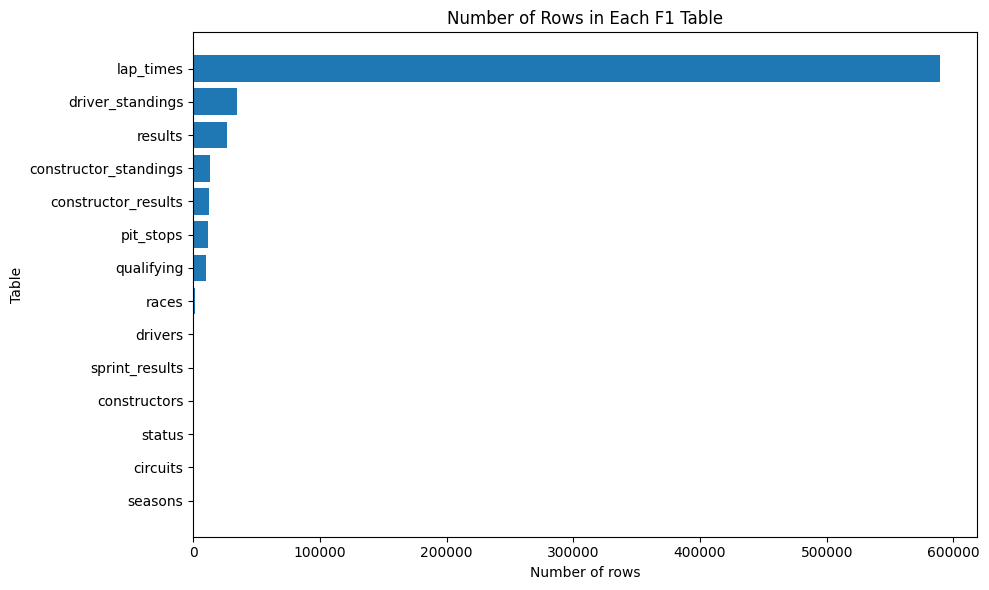

In [4]:
plt.figure(figsize=(10, 6))

plot_df = overview_df.sort_values("rows")

plt.barh(plot_df["table"], plot_df["rows"])

plt.xlabel("Number of rows")
plt.ylabel("Table")
plt.title("Number of Rows in Each F1 Table")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_raw_table_sizes.png", dpi=160, bbox_inches="tight")
plt.show()


### Observation

The dataset contains tables with very different sizes and grains. For example, event-level tables such as lap times contain many more rows than lookup tables such as circuits or constructors.

Therefore, cleaning and duplicate checks should be performed according to the meaning and key structure of each table rather than applying the same rule to all tables.

## 3. Missing Values and Sentinel Analysis

The dataset uses the literal value `\N` as a placeholder for missing data. We first identify where these sentinel values occur before cleaning so that the cleaning decision is based on observed missingness.

In [5]:
missing_summary = []

for name, df in tables_raw.items():
    for col in df.columns:
        sentinel_count = (df[col].astype(str) == r"\N").sum()

        if sentinel_count > 0:
            missing_summary.append({
                "table": name,
                "column": col,
                "sentinel_count": sentinel_count,
                "sentinel_pct": sentinel_count / len(df) * 100
            })

missing_summary_df = pd.DataFrame(missing_summary)

missing_summary_df.sort_values(
    "sentinel_pct",
    ascending=False
).head(30)


,table,column,sentinel_count,sentinel_pct
0,constructor_results,status,12608,99.865347
13,races,sprint_time,1110,98.666667
12,races,sprint_date,1107,98.400000
9,races,fp3_time,1072,95.288889
7,races,fp2_time,1057,93.955556
5,races,fp1_time,1057,93.955556
11,races,quali_time,1057,93.955556
8,races,fp3_date,1053,93.600000
1,drivers,number,802,93.147503
4,races,fp1_date,1035,92.000000


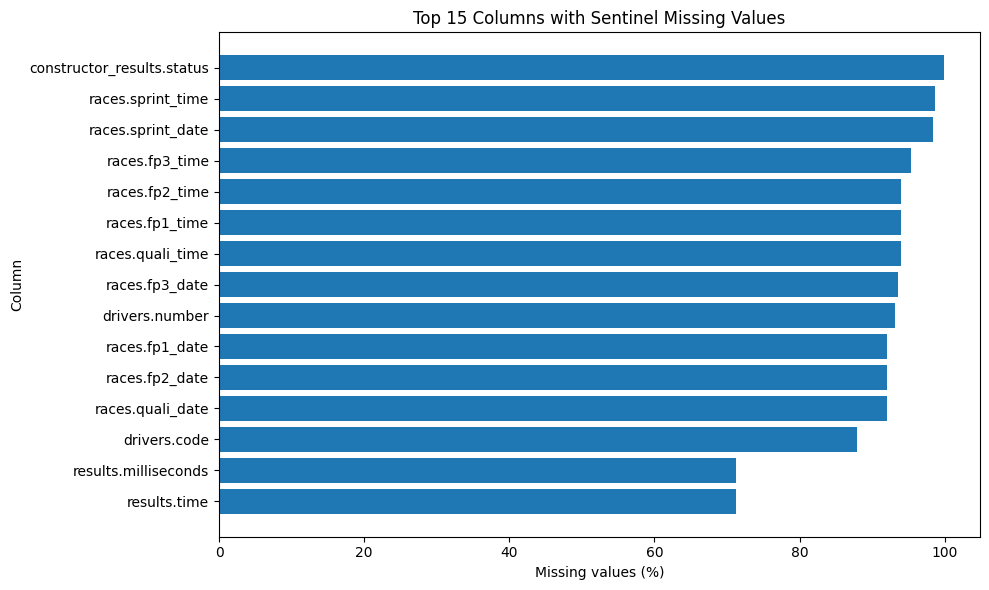

In [6]:
top_missing = (
    missing_summary_df
    .sort_values("sentinel_pct", ascending=False)
    .head(15)
    .copy()
)

top_missing["label"] = top_missing["table"] + "." + top_missing["column"]

plt.figure(figsize=(10, 6))

plt.barh(
    top_missing["label"][::-1],
    top_missing["sentinel_pct"][::-1]
)

plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.title("Top 15 Columns with Sentinel Missing Values")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_raw_missing_sentinels.png", dpi=160, bbox_inches="tight")
plt.show()


### Observation and Cleaning Decision

The amount of missing data differs across columns.

Some columns, such as `constructor_results.status` and several practice/sprint fields in `races`, have very high missingness, while others have moderate or low missingness.

Because the missing values have different meanings depending on the column, we will not apply one imputation method to every field.

At this cleaning stage, the literal `\N` sentinel values will be converted to proper missing values (`NaN`). Any later imputation or feature removal will be decided separately based on the meaning and usefulness of each feature.

In [7]:
tables_clean = {
    name: df.copy()
    for name, df in tables_raw.items()
}

for name, df in tables_clean.items():
    df.replace(r"\N", np.nan, inplace=True)


In [8]:
remaining_sentinels = 0

for name, df in tables_clean.items():
    remaining_sentinels += (df.astype(str) == r"\N").sum().sum()

print("Remaining literal \\N values:", remaining_sentinels)


Remaining literal \N values: 0


## 4. Semantic Typing

Some columns are stored as strings even though they represent dates or durations. We convert them into appropriate data types so they can be processed correctly later.

In [9]:
date_columns = {
    "drivers": ["dob"],
    "races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]
}

for table_name, columns in date_columns.items():
    for col in columns:
        if col in tables_clean[table_name].columns:
            tables_clean[table_name][col] = pd.to_datetime(
                tables_clean[table_name][col],
                errors="coerce"
            )


In [10]:
print(tables_clean["drivers"]["dob"].dtype)
print(tables_clean["races"]["date"].dtype)


datetime64[ns]
datetime64[ns]


### Justification

Date columns are converted to `datetime` so they can be sorted, compared, and used in time-based analysis correctly.

`errors="coerce"` is used so invalid or unavailable dates become missing values instead of causing errors.

### Duration Conversion

Some timing columns are stored as strings such as `1:23.456`. We convert them to numeric seconds so they can be analyzed and compared mathematically.

In [11]:
def time_to_seconds(value):
    if pd.isna(value):
        return np.nan

    parts = str(value).split(":")

    try:
        if len(parts) == 2:
            minutes, seconds = parts
            return float(minutes) * 60 + float(seconds)

        elif len(parts) == 3:
            hours, minutes, seconds = parts
            return (
                float(hours) * 3600
                + float(minutes) * 60
                + float(seconds)
            )

        else:
            return float(value)

    except ValueError:
        return np.nan


In [12]:
tables_clean["qualifying"]["q1_seconds"] = (
    tables_clean["qualifying"]["q1"].apply(time_to_seconds)
)

tables_clean["qualifying"]["q2_seconds"] = (
    tables_clean["qualifying"]["q2"].apply(time_to_seconds)
)

tables_clean["qualifying"]["q3_seconds"] = (
    tables_clean["qualifying"]["q3"].apply(time_to_seconds)
)

tables_clean["lap_times"]["time_seconds"] = (
    tables_clean["lap_times"]["time"].apply(time_to_seconds)
)

tables_clean["pit_stops"]["duration_seconds"] = (
    tables_clean["pit_stops"]["duration"].apply(time_to_seconds)
)


### Complete numeric and timing types

Sentinel-bearing numeric columns are explicitly converted to nullable integer or floating-point types. Fastest-lap durations in results and sprint results receive numeric seconds equivalents, and canonical milliseconds provide elapsed race time in seconds. Original timing text is preserved: `time` may contain relative gaps, so it is not blindly parsed as an absolute duration. These current-race outcome fields are for data quality and historical analysis only, and are not allowed prediction features. The audit stops on unexpected non-missing values that fail conversion.


In [13]:
# Columns with missing sentinels can otherwise remain text after replacement.
INTEGER_COLUMNS = {
    "drivers": ["number"],
    "results": ["number", "position", "milliseconds", "fastestLap", "rank"],
    "sprint_results": ["number", "position", "milliseconds", "fastestLap"],
}
FLOAT_COLUMNS = {"results": ["fastestLapSpeed"]}

def apply_semantic_types(tables):
    """Complete typing in an already-copied table dictionary; return parse audit."""
    audit = []
    def record(table, column, source, converted):
        bad = source.notna() & converted.isna()
        audit.append({"table": table, "column": column,
                      "nonmissing_input": int(source.notna().sum()),
                      "parse_failures": int(bad.sum()),
                      "examples": source.loc[bad].astype(str).head(3).tolist()})
        if bad.any():
            raise ValueError(f"Unexpected parse failures in {table}.{column}: {audit[-1]['examples']}")
    for table, columns in INTEGER_COLUMNS.items():
        for column in columns:
            if column not in tables[table]:
                continue
            source = tables[table][column]
            converted = pd.to_numeric(source, errors="coerce")
            record(table, column, source, converted)
            tables[table][column] = converted.astype("Int64")
    for table, columns in FLOAT_COLUMNS.items():
        for column in columns:
            source = tables[table][column]
            converted = pd.to_numeric(source, errors="coerce")
            record(table, column, source, converted)
            tables[table][column] = converted.astype("Float64")
    for table in ["results", "sprint_results"]:
        source = tables[table]["fastestLapTime"]
        converted = source.apply(time_to_seconds)
        record(table, "fastestLapTime_seconds", source, converted)
        tables[table]["fastestLapTime_seconds"] = converted.astype("Float64")
        # results.time mixes winner elapsed times and relative gaps (e.g. +5.123).
        # The canonical milliseconds field already records elapsed race time.
        # Keep the original text; do not interpret a gap as elapsed race time.
        tables[table]["elapsed_time_seconds"] = tables[table]["milliseconds"].astype("Float64") / 1000
    return pd.DataFrame(audit)

semantic_type_audit = apply_semantic_types(tables_clean)
display(semantic_type_audit)
semantic_type_audit.to_csv(OUTPUT_DIR / "semantic_type_audit.csv", index=False)
print("Remaining timing/numeric fields converted; unexpected parse failures:", semantic_type_audit["parse_failures"].sum())

# Audit the original date/lap/pit-duration conversions as well.
conversion_rows = []
for table, columns in date_columns.items():
    for column in columns:
        source = tables_raw[table][column].replace(r"\N", np.nan)
        failures = source.notna() & tables_clean[table][column].isna()
        conversion_rows.append({"table": table, "column": column, "parse_failures": int(failures.sum())})
for table, mapping in {"qualifying": {"q1": "q1_seconds", "q2": "q2_seconds", "q3": "q3_seconds"}, "lap_times": {"time": "time_seconds"}, "pit_stops": {"duration": "duration_seconds"}}.items():
    for original, converted in mapping.items():
        source = tables_raw[table][original].replace(r"\N", np.nan)
        failures = source.notna() & tables_clean[table][converted].isna()
        conversion_rows.append({"table": table, "column": converted, "parse_failures": int(failures.sum())})
conversion_audit = pd.DataFrame(conversion_rows)
assert conversion_audit["parse_failures"].eq(0).all(), "Date or duration parse failures need review"
conversion_audit.to_csv(OUTPUT_DIR / "date_duration_parse_audit.csv", index=False)


,table,column,nonmissing_input,parse_failures,examples
0,drivers,number,59,0,[]
1,results,number,26753,0,[]
2,results,position,15806,0,[]
3,results,milliseconds,7680,0,[]
4,results,fastestLap,8252,0,[]
5,results,rank,8510,0,[]
6,sprint_results,number,360,0,[]
7,sprint_results,position,345,0,[]
8,sprint_results,milliseconds,340,0,[]
9,sprint_results,fastestLap,351,0,[]


Remaining timing/numeric fields converted; unexpected parse failures: 0


In [14]:
tables_clean["qualifying"][
    ["q1", "q1_seconds", "q2", "q2_seconds", "q3", "q3_seconds"]
].head(10)


,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236
5,1:26.427,86.427,1:26.101,86.101,1:28.527,88.527
6,1:26.295,86.295,1:26.059,86.059,1:28.687,88.687
7,1:26.381,86.381,1:26.063,86.063,1:29.041,89.041
8,1:26.919,86.919,1:26.164,86.164,1:29.593,89.593
9,1:26.702,86.702,1:25.842,85.842,NaN,NaN


### Observation

The qualifying time strings were successfully converted to numeric seconds while missing values remained as `NaN`.

This makes the timing data easier to compare and use in later numerical analysis without inventing values for missing sessions.

## 5. Driver-Race Duplicate Check

The final modeling table must contain one row for each driver in each race. Therefore, we check whether the combination `(raceId, driverId)` is unique in the `results` table.

In [15]:
driver_race_counts = (
    tables_clean["results"]
    .groupby(["raceId", "driverId"])
    .size()
    .reset_index(name="count")
)

duplicate_driver_races = driver_race_counts[
    driver_race_counts["count"] > 1
]

print(
    "Number of duplicated driver-race combinations:",
    len(duplicate_driver_races)
)

duplicate_driver_races.head()


,raceId,driverId,count
13659,540,229,2
17821,717,373,2
18222,733,465,2
18445,742,475,2
18532,745,418,2


Number of duplicated driver-race combinations: 85


In [16]:
duplicate_details = (
    tables_clean["results"]
    .merge(
        duplicate_driver_races[["raceId", "driverId"]],
        on=["raceId", "driverId"],
        how="inner"
    )
    .merge(
        tables_clean["races"][["raceId", "year", "name"]],
        on="raceId",
        how="left"
    )
)

duplicate_by_year = (
    duplicate_details[
        ["year", "raceId", "driverId"]
    ]
    .drop_duplicates()
    .groupby("year")
    .size()
)

duplicate_by_year


year
1950     4
1951     4
1952     3
1953    14
1954    16
1955    15
1956    12
1957     8
1958     3
1960     1
1961     2
1962     1
1964     1
1978     1
dtype: int64

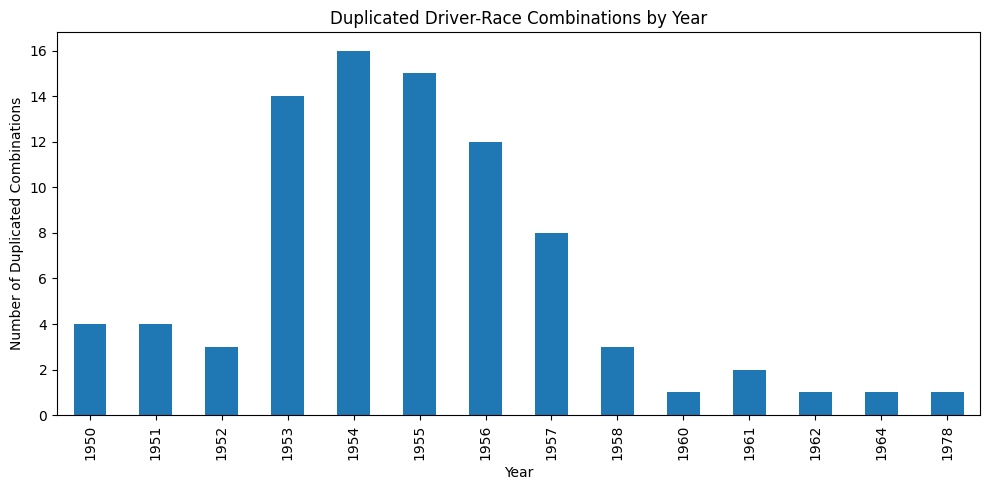

In [17]:
plt.figure(figsize=(10, 5))

duplicate_by_year.plot(kind="bar")

plt.title("Duplicated Driver-Race Combinations by Year")
plt.xlabel("Year")
plt.ylabel("Number of Duplicated Combinations")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_duplicate_groups_by_year.png", dpi=160, bbox_inches="tight")
plt.show()


### Observation

The duplicated driver-race combinations are concentrated mainly in the earlier Formula 1 seasons.

This matches the historical shared-drive issue, where a driver could appear more than once in the same race after switching cars.

Since the final modeling table requires one row per `(raceId, driverId)`, a consistent rule is needed to keep only one record for each duplicated pair.

### Duplicate Resolution Rule

Most duplicated `(raceId, driverId)` combinations occur in early Formula 1 seasons and are related to historical shared-drive cases.

To keep one row per driver and race without using post-race information, duplicates are resolved using the starting grid:

- Rows with a valid non-zero grid position are preferred.
- If multiple valid rows remain, the row with the lowest grid position is kept.
- `resultId` is used only as a tie-breaker.

`positionOrder` is not used for duplicate resolution because it is a post-race outcome and could introduce data leakage.

In [18]:
results_clean = tables_clean["results"].copy()

results_clean["valid_grid"] = results_clean["grid"] > 0

results_clean = (
    results_clean
    .sort_values(
        by=["raceId", "driverId", "valid_grid", "grid", "resultId"],
        ascending=[True, True, False, True, True]
    )
    .drop_duplicates(
        subset=["raceId", "driverId"],
        keep="first"
    )
    .drop(columns="valid_grid")
)

tables_clean["results"] = results_clean


In [19]:
remaining_duplicates = (
    tables_clean["results"]
    .duplicated(subset=["raceId", "driverId"])
    .sum()
)

print("Remaining duplicated driver-race combinations:", remaining_duplicates)
print("Rows before:", len(results_raw))
print("Rows after:", len(tables_clean["results"]))


Remaining duplicated driver-race combinations: 0
Rows before: 26759
Rows after: 26668


### Result

After applying the duplicate-resolution rule, no duplicated `(raceId, driverId)` combinations remain.

The `results` table decreased from 26,759 to 26,668 rows, giving one record per driver per race as required.

## 6. Primary Key Auditing

We verify that the expected primary key of each table is unique and contains no missing values. For tables without a single identifier column, the appropriate composite key is checked.

In [20]:
primary_keys = {
    "circuits": ["circuitId"],
    "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"],
    "driver_standings": ["driverStandingsId"],
    "races": ["raceId"],
    "results": ["resultId"],
    "qualifying": ["qualifyId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "sprint_results": ["resultId"],
    "seasons": ["year"],
    "status": ["statusId"]
}

pk_audit = []

for table_name, key_cols in primary_keys.items():
    df = tables_clean[table_name]

    missing_keys = df[key_cols].isna().any(axis=1).sum()
    duplicate_keys = df.duplicated(subset=key_cols).sum()

    pk_audit.append({
        "table": table_name,
        "key": ", ".join(key_cols),
        "missing_key_rows": missing_keys,
        "duplicate_key_rows": duplicate_keys
    })

pk_audit_df = pd.DataFrame(pk_audit)

display(pk_audit_df)

assert not pk_audit_df[["missing_key_rows", "duplicate_key_rows"]].to_numpy().any(), "Primary-key validation failed"


,table,key,missing_key_rows,duplicate_key_rows
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,constructor_results,constructorResultsId,0,0
3,constructor_standings,constructorStandingsId,0,0
4,drivers,driverId,0,0
5,driver_standings,driverStandingsId,0,0
6,races,raceId,0,0
7,results,resultId,0,0
8,qualifying,qualifyId,0,0
9,lap_times,"raceId, driverId, lap",0,0


### Observation

All expected primary keys are complete and unique.

No table contains missing key values or duplicated primary/composite keys, so the key structure is internally consistent after cleaning.

## 7. Foreign Key Auditing

We check whether foreign-key values in child tables can be matched to the corresponding parent tables.

This verifies that the relational tables can be joined consistently without unmatched identifiers.

In [21]:
foreign_keys = [
    ("races", "year", "seasons", "year"),
    ("races", "circuitId", "circuits", "circuitId"),

    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),

    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),

    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),

    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),

    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),

    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),

    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),

    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId")
]

fk_audit = []

for child_table, child_col, parent_table, parent_col in foreign_keys:
    child_values = tables_clean[child_table][child_col]
    parent_values = tables_clean[parent_table][parent_col]

    unmatched = (
        child_values.notna()
        & ~child_values.isin(parent_values)
    ).sum()

    fk_audit.append({
        "child_table": child_table,
        "foreign_key": child_col,
        "parent_table": parent_table,
        "parent_key": parent_col,
        "unmatched_rows": unmatched
    })

fk_audit_df = pd.DataFrame(fk_audit)

display(fk_audit_df)

assert fk_audit_df["unmatched_rows"].eq(0).all(), "Foreign-key validation failed"


,child_table,foreign_key,parent_table,parent_key,unmatched_rows
0,races,year,seasons,year,0
1,races,circuitId,circuits,circuitId,0
2,results,raceId,races,raceId,0
3,results,driverId,drivers,driverId,0
4,results,constructorId,constructors,constructorId,0
5,results,statusId,status,statusId,0
6,qualifying,raceId,races,raceId,0
7,qualifying,driverId,drivers,driverId,0
8,qualifying,constructorId,constructors,constructorId,0
9,lap_times,raceId,races,raceId,0


### Observation

All checked foreign keys successfully match their corresponding parent-table keys.

No unmatched foreign-key values were found, which indicates that the relational links between the cleaned tables are consistent.

## 8. Post-Cleaning Verification

After cleaning, we verify that the main data-quality issues identified earlier have been resolved.

In [22]:
before_after = pd.DataFrame({
    "check": [
        "Literal sentinel values",
        "Duplicated (raceId, driverId)"
    ],
    "before": [
        sum(
            (df.astype(str) == r"\N").sum().sum()
            for df in tables_raw.values()
        ),
        int((tables_raw["results"].groupby(["raceId", "driverId"]).size() > 1).sum())
    ],
    "after": [
        sum(
            (df.astype(str) == r"\N").sum().sum()
            for df in tables_clean.values()
        ),
        tables_clean["results"]
        .duplicated(subset=["raceId", "driverId"])
        .sum()
    ]
})

before_after


,check,before,after
0,Literal sentinel values,160076,0
1,"Duplicated (raceId, driverId)",85,0


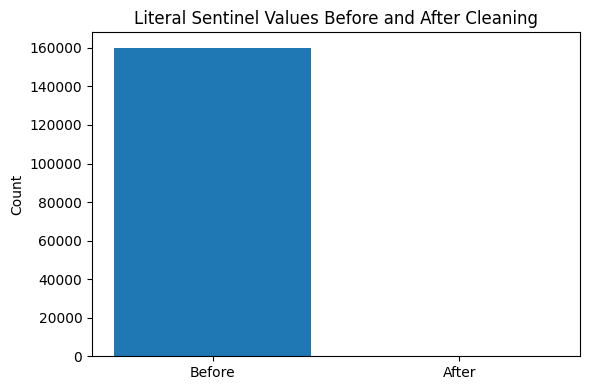

In [23]:
plt.figure(figsize=(6, 4))

plt.bar(
    ["Before", "After"],
    [before_after.loc[0, "before"], before_after.loc[0, "after"]]
)

plt.ylabel("Count")
plt.title("Literal Sentinel Values Before and After Cleaning")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_sentinels_before_after.png", dpi=160, bbox_inches="tight")
plt.show()


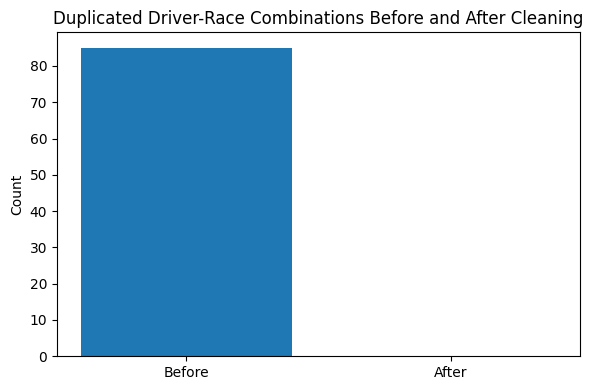

In [24]:
plt.figure(figsize=(6, 4))

plt.bar(
    ["Before", "After"],
    [before_after.loc[1, "before"], before_after.loc[1, "after"]]
)

plt.ylabel("Count")
plt.title("Duplicated Driver-Race Combinations Before and After Cleaning")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_duplicates_before_after.png", dpi=160, bbox_inches="tight")
plt.show()


### Final Cleaning Result

The literal `\N` sentinel values were successfully converted to proper missing values.

The duplicated `(raceId, driverId)` combinations were also resolved, leaving one row per driver per race.

Primary-key and foreign-key audits showed no remaining integrity problems in the checked tables.

### Cleaned Dataset Summary

The following tables are now ready for the next stages of analysis and feature engineering.

In [25]:
clean_summary = []

for name, df in tables_clean.items():
    clean_summary.append({
        "table": name,
        "rows": df.shape[0],
        "columns": df.shape[1]
    })

clean_summary_df = pd.DataFrame(clean_summary).sort_values(
    "rows",
    ascending=False
)

clean_summary_df


,table,rows,columns
9,lap_times,589081,7
5,driver_standings,34863,7
7,results,26668,20
3,constructor_standings,13391,7
2,constructor_results,12625,5
10,pit_stops,11371,8
8,qualifying,10494,12
6,races,1125,18
4,drivers,861,9
11,sprint_results,360,18


## 9. Additional checks — original cells above preserved

The original code and explanations above remain in their original order. These appended cells complete the missing work without changing the cleaned tables used by the rest of the team.

### 9.1 Columns and types

Inspect all 14 schemas programmatically so the raw-data overview explicitly covers column names and types.

In [26]:
from pathlib import Path
from IPython.display import display, Markdown

# OUTPUT_DIR is configured in the loading cell; every plot is saved there.

def save_plot(filename):
    plt.gcf().savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

schema_df = pd.DataFrame([
    {"table": name, "column": column, "raw_type": str(frame[column].dtype)}
    for name, frame in tables_raw.items() for column in frame.columns
])
with pd.option_context("display.max_rows", None):
    display(schema_df)


,table,column,raw_type
0,circuits,circuitId,int64
1,circuits,circuitRef,object
2,circuits,name,object
3,circuits,location,object
4,circuits,country,object
5,circuits,lat,float64
6,circuits,lng,float64
7,circuits,alt,int64
8,circuits,url,object
9,constructors,constructorId,int64


### 9.2 Calculated duplicate summary

The original summary above used the known value `85`. This additional summary calculates the counts directly instead. Duplicate groups and surplus rows are different quantities: one group with three records contributes one group and two surplus rows.

,check,before,after
0,Duplicated driver-race groups,85,0
1,Surplus driver-race rows,91,0
2,Results rows,26759,26668


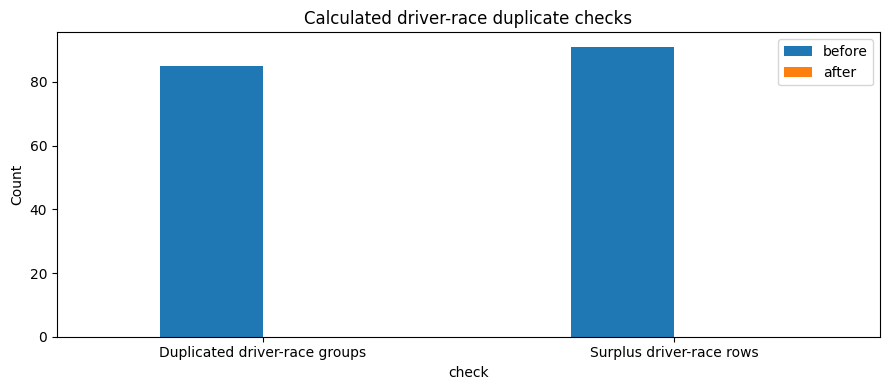

In [27]:
def duplicate_summary(frame):
    counts = frame.groupby(["raceId", "driverId"], dropna=False).size()
    return {"duplicate_groups": int((counts > 1).sum()),
            "surplus_rows": int((counts - 1).clip(lower=0).sum())}

raw_duplicates = duplicate_summary(tables_raw["results"])
clean_duplicates = duplicate_summary(tables_clean["results"])
before_after_calculated = pd.DataFrame({
    "check": ["Duplicated driver-race groups", "Surplus driver-race rows", "Results rows"],
    "before": [raw_duplicates["duplicate_groups"], raw_duplicates["surplus_rows"], len(tables_raw["results"])],
    "after": [clean_duplicates["duplicate_groups"], clean_duplicates["surplus_rows"], len(tables_clean["results"])]
})
display(before_after_calculated)
assert clean_duplicates["duplicate_groups"] == 0
ax = before_after_calculated.iloc[:2].set_index("check").plot.bar(rot=0, figsize=(9,4))
ax.set_ylabel("Count")
ax.set_title("Calculated driver-race duplicate checks")
plt.tight_layout()
save_plot("calculated_duplicate_checks.png")


### 9.3 Reusable cleaning function — same existing steps

This wraps the existing cleaning operations for reuse. The original inline cells are retained. The function uses the original `time_to_seconds()` and returns copies. Its output is checked against the existing `tables_clean`; the team handoff variable is not replaced.

In [28]:
DATE_COLUMNS = {'drivers': ['dob'], 'races': ['date', 'fp1_date', 'fp2_date', 'fp3_date', 'quali_date', 'sprint_date']}
DURATION_COLUMNS = {'qualifying': {'q1': 'q1_seconds', 'q2': 'q2_seconds', 'q3': 'q3_seconds'}, 'lap_times': {'time': 'time_seconds'}, 'pit_stops': {'duration': 'duration_seconds'}}

def clean_tables(raw_tables):
    clean = {name: df.copy(deep=True) for name, df in raw_tables.items()}
    for df in clean.values():
        df.replace('\\N', np.nan, inplace=True)
    for name, columns in DATE_COLUMNS.items():
        for col in columns:
            if col in clean[name]:
                clean[name][col] = pd.to_datetime(clean[name][col], errors='coerce')
    for name, mappings in DURATION_COLUMNS.items():
        for original_col, new_col in mappings.items():
            clean[name][new_col] = clean[name][original_col].apply(time_to_seconds)
    apply_semantic_types(clean)
    results = clean['results'].copy()
    results['valid_grid'] = results['grid'] > 0
    clean['results'] = results.sort_values(['raceId', 'driverId', 'valid_grid', 'grid', 'resultId'], ascending=[True, True, False, True, True]).drop_duplicates(['raceId', 'driverId'], keep='first').drop(columns='valid_grid')
    return clean

reusable_check = clean_tables(tables_raw)
for name in tables_clean:
    pd.testing.assert_frame_equal(tables_clean[name], reusable_check[name])
print("Reusable function matches all 14 existing cleaned tables exactly.")
del reusable_check


Reusable function matches all 14 existing cleaned tables exactly.


### 9.4 Additional post-cleaning EDA

The existing before/after plots check cleaning success. The additional plot below compares effective missingness before and after cleaning: sentinel replacement converts missing markers to nulls without inventing information. The distribution comparison shows whether removing historical duplicate records changed season counts or starting-grid values. No additional cleaning or imputation is performed.

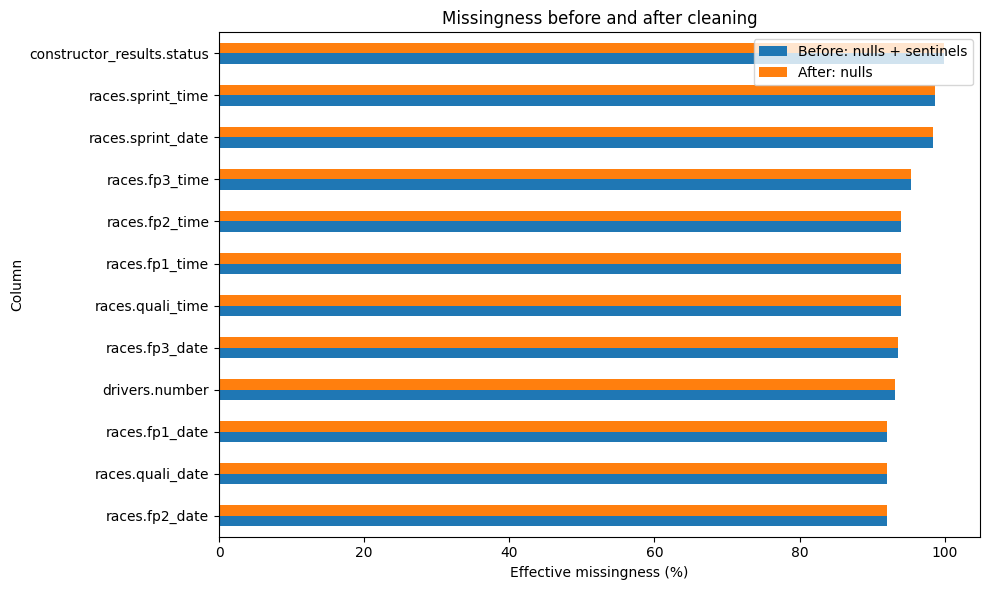

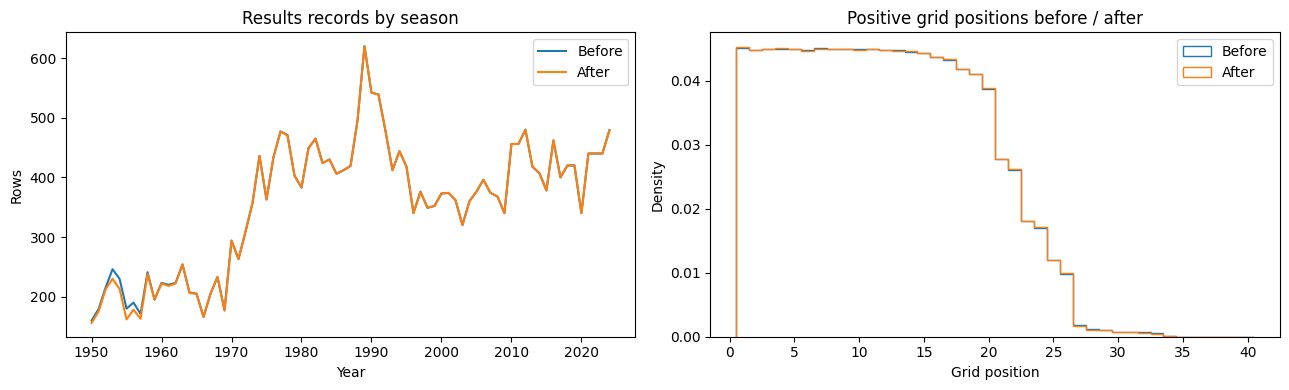

Rows removed: 91
Sentinels now appear as nulls; they were not imputed.


In [29]:
def effective_missingness(tables):
    return pd.DataFrame([
        {"table": name, "column": col,
         "missing_pct": (frame[col].isna() | frame[col].eq(r"\N").fillna(False)).mean() * 100}
        for name, frame in tables.items() for col in frame.columns
    ])

missing_compare = effective_missingness(tables_raw).merge(
    effective_missingness(tables_clean), on=["table", "column"], suffixes=("_before", "_after"))
top = missing_compare.nlargest(12, "missing_pct_before").sort_values("missing_pct_before")
plot = top.set_index(top["table"] + "." + top["column"])[["missing_pct_before", "missing_pct_after"]]
ax = plot.plot.barh(figsize=(10,6))
ax.set_xlabel("Effective missingness (%)")
ax.set_ylabel("Column")
ax.set_title("Missingness before and after cleaning")
ax.legend(["Before: nulls + sentinels", "After: nulls"])
plt.tight_layout()
save_plot("missingness_before_after.png")

fig, axes = plt.subplots(1, 2, figsize=(13,4))
for label, tables in [("Before", tables_raw), ("After", tables_clean)]:
    yearly = tables["results"].merge(tables["races"][["raceId", "year"]], on="raceId", validate="many_to_one").groupby("year").size()
    axes[0].plot(yearly.index, yearly.values, label=label)
    grid = pd.to_numeric(tables["results"]["grid"], errors="coerce")
    grid.loc[grid.gt(0)].plot.hist(bins=np.arange(.5,41.5,1), density=True, histtype="step", ax=axes[1], label=label)
axes[0].set(title="Results records by season", xlabel="Year", ylabel="Rows")
axes[1].set(title="Positive grid positions before / after", xlabel="Grid position", ylabel="Density")
for ax in axes: ax.legend()
fig.tight_layout()
save_plot("distributions_before_after.png")

print("Rows removed:", len(tables_raw["results"]) - len(tables_clean["results"]))
print("Sentinels now appear as nulls; they were not imputed.")


## 10. Q1 — Which circuits convert a front-row start into a podium most often?

**Question:** Does the circuit ranking change after the 2014 hybrid era? Distinguish qualifying from starting grid, which may differ because of penalties or weekend formats.

**Grain and joins:** join cleaned `results → races → circuits`, then left-join `qualifying` by `(raceId, driverId)`. Keep exactly one row per driver–race. Define podium as `positionOrder <= 3`.

**Two separate measures:** (1) actual front-row grid, `grid in {1, 2}`; (2) front-row qualifying, `qualifying_position in {1, 2}`. Each conversion rate is podium driver–race rows divided by front-row driver–race rows for that circuit and era. These are driver-level conversion rates, not the probability that at least one front-row car podiums.

**Missingness:** exclude unknown qualifying positions only from the qualifying calculation; never replace missing qualifying position with grid. Nonpositive grids do not count as front-row starts. Missing finishing outcomes are excluded and counted. A qualifying result need not equal the starting grid, especially on sprint weekends.

**Ranking policy:** show every circuit's numerator and denominator. Use at least 10 front-row observations per circuit–era for the displayed rankings to reduce very small-sample extremes. Compare rank movement only within the same set of circuits eligible in both eras. The full unscreened table and sensitivity summaries remain available. Wilson 95% intervals show uncertainty; rank movement alone is not proof of a meaningful change.

In [30]:
MIN_FRONT_ROW = 10

def answer_q1(tables, minimum=10):
    results = tables["results"][["raceId", "driverId", "grid", "positionOrder"]].copy()
    races = tables["races"][["raceId", "year", "circuitId"]]
    circuits = tables["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit"})
    qualifying = tables["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "qualifying_position"})
    if results.duplicated(["raceId", "driverId"]).any() or qualifying.duplicated(["raceId", "driverId"]).any():
        raise ValueError("Resolve duplicate driver–race keys before Q1")
    joined = (results.merge(races, on="raceId", validate="many_to_one")
              .merge(circuits, on="circuitId", validate="many_to_one")
              .merge(qualifying, on=["raceId", "driverId"], how="left", validate="one_to_one"))
    assert len(joined) == len(results), "Q1 join dropped result rows"
    for col in ["grid", "qualifying_position", "positionOrder"]:
        joined[col] = pd.to_numeric(joined[col], errors="coerce")
    joined["era"] = np.where(joined["year"] < 2014, "Before 2014", "2014 onward")
    joined["podium"] = joined["positionOrder"].le(3)
    summaries = []
    for definition, col in [("Starting grid", "grid"), ("Qualifying", "qualifying_position")]:
        subset = joined.loc[joined[col].isin([1, 2]) & joined["positionOrder"].notna()]
        stats = subset.groupby(["circuitId", "circuit", "era"], as_index=False).agg(
            front_row_observations=("podium", "size"), podiums=("podium", "sum"), races=("raceId", "nunique"))
        stats["definition"] = definition
        stats["conversion_rate"] = stats["podiums"] / stats["front_row_observations"]
        n, p = stats["front_row_observations"], stats["conversion_rate"]
        z = 1.96
        center = (p + z*z/(2*n)) / (1 + z*z/n)
        half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
        stats["ci_low"], stats["ci_high"] = center-half, center+half
        stats["eligible"] = n.ge(minimum)
        summaries.append(stats)
    rates = pd.concat(summaries, ignore_index=True)
    return joined, rates

q1_joined, q1_rates = answer_q1(tables_clean, MIN_FRONT_ROW)
q1_coverage = q1_joined.groupby("era").agg(
    driver_race_rows=("driverId", "size"), known_qualifying=("qualifying_position", lambda s: int(s.gt(0).sum())),
    nonpositive_or_missing_grid=("grid", lambda s: int((s.isna() | s.le(0)).sum())),
    missing_outcome=("positionOrder", lambda s: int(s.isna().sum())))
q1_coverage["qualifying_coverage_pct"] = q1_coverage["known_qualifying"] / q1_coverage["driver_race_rows"] * 100
display(q1_coverage)
q1_disagreements = q1_joined.loc[q1_joined["qualifying_position"].gt(0) & q1_joined["grid"].gt(0)].copy()
q1_disagreements["front_row_membership_differs"] = q1_disagreements["grid"].isin([1,2]) != q1_disagreements["qualifying_position"].isin([1,2])
display(q1_disagreements.groupby("era")["front_row_membership_differs"].agg(["sum", "count", "mean"]))
with pd.option_context("display.max_rows", None):
    display(q1_rates.sort_values(["definition", "era", "conversion_rate"], ascending=[True, True, False]))


,driver_race_rows,known_qualifying,nonpositive_or_missing_grid,missing_outcome,qualifying_coverage_pct
era,,,,,
2014 onward,4626,4610,79,0,99.654129
Before 2014,22042,5884,1556,0,26.694492


,sum,count,mean
era,,,
2014 onward,54,4533,0.011913
Before 2014,18,5874,0.003064


,circuitId,circuit,era,front_row_observations,podiums,races,definition,conversion_rate,ci_low,ci_high,eligible
159,75,Autódromo Internacional do Algarve,2014 onward,4,4,2,Qualifying,1.000000,0.510100,1.000000,False
160,76,Autodromo Internazionale del Mugello,2014 onward,2,2,1,Qualifying,1.000000,0.342372,1.000000,False
163,79,Miami International Autodrome,2014 onward,6,6,3,Qualifying,1.000000,0.609657,1.000000,False
139,22,Suzuka Circuit,2014 onward,18,16,9,Qualifying,0.888889,0.671998,0.968981,True
151,39,Circuit Park Zandvoort,2014 onward,8,7,4,Qualifying,0.875000,0.529105,0.977583,False
111,6,Circuit de Monaco,2014 onward,20,17,10,Qualifying,0.850000,0.639577,0.947632,True
107,4,Circuit de Barcelona-Catalunya,2014 onward,22,18,11,Qualifying,0.818182,0.614830,0.926932,True
123,13,Circuit de Spa-Francorchamps,2014 onward,22,18,11,Qualifying,0.818182,0.614830,0.926932,True
141,24,Yas Marina Circuit,2014 onward,22,18,11,Qualifying,0.818182,0.614830,0.926932,True
157,71,Sochi Autodrom,2014 onward,16,13,8,Qualifying,0.812500,0.569906,0.934085,True


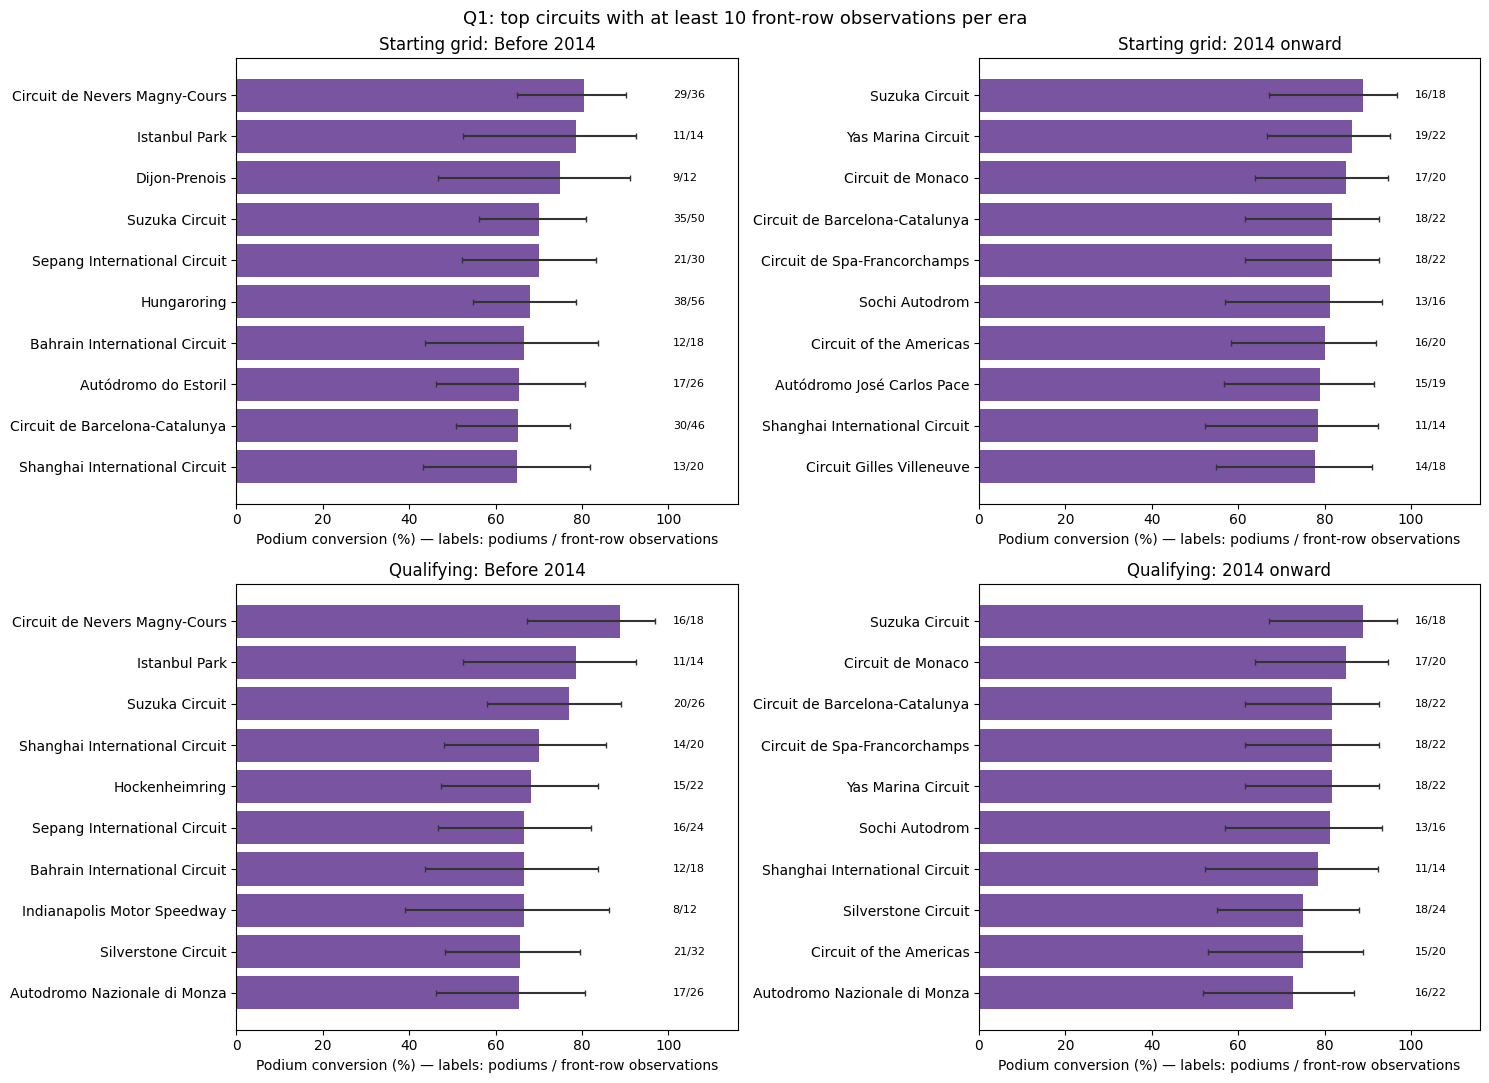

era,circuitId,circuit,2014 onward,Before 2014,rank_before,rank_after,rank_improvement,change_pp,definition
28,22,Suzuka Circuit,0.888889,0.769231,1.0,1.0,0.0,11.965812,Qualifying
19,6,Circuit de Monaco,0.850000,0.642857,7.0,2.0,5.0,20.714286,Qualifying
18,4,Circuit de Barcelona-Catalunya,0.818182,0.633333,8.0,3.0,5.0,18.484848,Qualifying
23,13,Circuit de Spa-Francorchamps,0.818182,0.541667,13.0,3.0,10.0,27.651515,Qualifying
29,24,Yas Marina Circuit,0.818182,0.600000,9.0,3.0,6.0,21.818182,Qualifying
26,17,Shanghai International Circuit,0.785714,0.700000,2.0,6.0,-4.0,8.571429,Qualifying
21,9,Silverstone Circuit,0.750000,0.656250,4.0,7.0,-3.0,9.375000,Qualifying
24,14,Autodromo Nazionale di Monza,0.727273,0.653846,5.0,8.0,-3.0,7.342657,Qualifying
16,1,Albert Park Grand Prix Circuit,0.722222,0.531250,14.0,9.0,5.0,19.097222,Qualifying
20,7,Circuit Gilles Villeneuve,0.722222,0.576923,12.0,9.0,3.0,14.529915,Qualifying


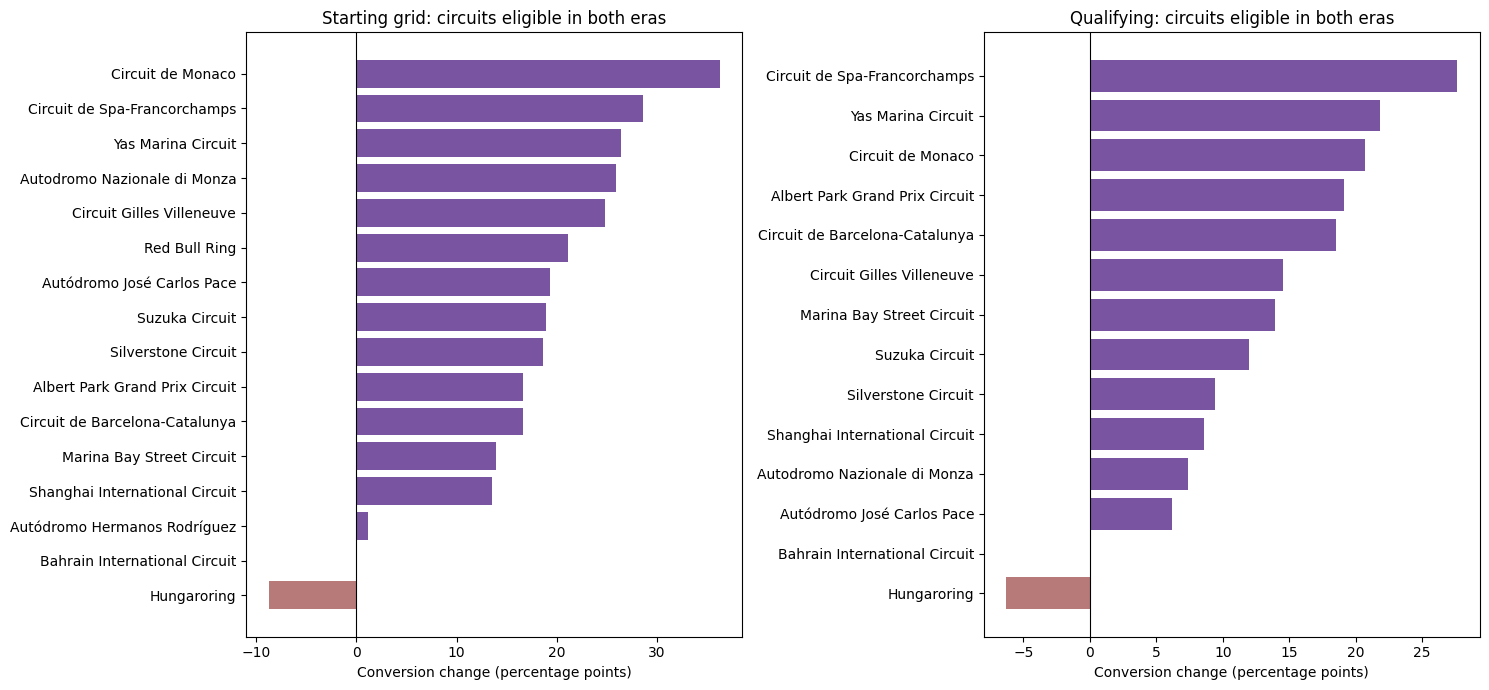

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for row, definition in enumerate(["Starting grid", "Qualifying"]):
    for col, era in enumerate(["Before 2014", "2014 onward"]):
        ax = axes[row, col]
        top = (q1_rates.loc[q1_rates["definition"].eq(definition) & q1_rates["era"].eq(era) & q1_rates["eligible"]]
               .sort_values(["conversion_rate", "front_row_observations", "circuit"], ascending=[False, False, True]).head(10)
               .iloc[::-1])
        if top.empty:
            ax.text(.5, .5, "No eligible circuits", ha="center")
            continue
        x = top["conversion_rate"].to_numpy() * 100
        ax.barh(top["circuit"], x, color="#7954a1")
        ax.errorbar(x, top["circuit"], xerr=np.vstack([x-top["ci_low"].to_numpy()*100,
                    top["ci_high"].to_numpy()*100-x]), fmt="none", ecolor="#333333", capsize=2)
        for i, (_, r) in enumerate(top.iterrows()):
            ax.text(101, i, f"{int(r.podiums)}/{int(r.front_row_observations)}", va="center", fontsize=8)
        ax.set_xlim(0, 116)
        ax.set_title(f"{definition}: {era}")
        ax.set_xlabel("Podium conversion (%) — labels: podiums / front-row observations")
fig.suptitle(f"Q1: top circuits with at least {MIN_FRONT_ROW} front-row observations per era", fontsize=13)
fig.tight_layout()
save_plot("08_q1_circuit_conversion_rankings.png")

q1_rank_changes = []
for definition in ["Starting grid", "Qualifying"]:
    eligible = q1_rates.loc[q1_rates["definition"].eq(definition) & q1_rates["eligible"]]
    wide = eligible.pivot(index=["circuitId", "circuit"], columns="era", values="conversion_rate").dropna()
    if wide.empty:
        continue
    wide["rank_before"] = wide["Before 2014"].rank(ascending=False, method="min")
    wide["rank_after"] = wide["2014 onward"].rank(ascending=False, method="min")
    wide["rank_improvement"] = wide["rank_before"] - wide["rank_after"]
    wide["change_pp"] = (wide["2014 onward"] - wide["Before 2014"]) * 100
    wide["definition"] = definition
    q1_rank_changes.append(wide.reset_index())
q1_rank_changes = pd.concat(q1_rank_changes, ignore_index=True) if q1_rank_changes else pd.DataFrame()
display(q1_rank_changes.sort_values(["definition", "rank_after"]))
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, definition in zip(axes, ["Starting grid", "Qualifying"]):
    data = q1_rank_changes.loc[q1_rank_changes["definition"].eq(definition)].sort_values("change_pp")
    ax.barh(data["circuit"], data["change_pp"], color=np.where(data["change_pp"] >= 0, "#7954a1", "#b87979"))
    ax.axvline(0, color="black", linewidth=.8)
    ax.set(title=f"{definition}: circuits eligible in both eras", xlabel="Conversion change (percentage points)")
fig.tight_layout()
save_plot("09_q1_same_circuit_era_changes.png")


In [32]:
interpretation = ["### Q1 — Computed answer and interpretation"]
for definition in ["Starting grid", "Qualifying"]:
    for era in ["Before 2014", "2014 onward"]:
        eligible = q1_rates.loc[q1_rates["definition"].eq(definition) & q1_rates["era"].eq(era) & q1_rates["eligible"]]
        if eligible.empty:
            interpretation.append(f"- **{definition}, {era}:** no eligible circuits at the selected minimum.")
            continue
        best = eligible["conversion_rate"].max()
        leaders = eligible.loc[np.isclose(eligible["conversion_rate"], best)]
        labels = [f"{r.circuit}: {r.conversion_rate:.1%} ({int(r.podiums)}/{int(r.front_row_observations)})" for r in leaders.itertuples()]
        interpretation.append(f"- **{definition}, {era}:** highest observed conversion: " + "; ".join(labels) + ".")
    changes = q1_rank_changes.loc[q1_rank_changes["definition"].eq(definition)]
    changed = int(changes["rank_before"].ne(changes["rank_after"]).sum())
    interpretation.append(f"- **{definition}, rank comparison:** {changed} of {len(changes)} common eligible circuits change rank (ties use competition ranking).")
    if not changes.empty:
        biggest = changes.loc[changes["change_pp"].abs().idxmax()]
        interpretation.append(f"  Largest absolute conversion change among those circuits: {biggest['circuit']}, {biggest['change_pp']:+.1f} percentage points.")
interpretation += ["", "**Interpretation and limits:** these are historical associations, not causal circuit effects. Driver and constructor strength, era composition, race counts and missing qualifying coverage differ. Wilson intervals are approximate: the two front-row drivers share a race, so observations are not fully independent. Sparse samples and overlapping intervals limit confidence in exact rankings. Qualifying and grid must remain distinct; neither measure's missing values are substituted with the other. The before-2014 comparison covers much more history, and the post-2014 sample ends at the dataset's latest season.",
                  "", "**Pre-race cutoff:** Q1 outcomes are used only as historical analysis labels. For later prediction, derive any circuit conversion feature from prior races only; do not merge this full-history outcome aggregate into every modeling row."]
q1_interpretation = "\n".join(interpretation)
display(Markdown(q1_interpretation))

sensitivity = []
for minimum in [4, 10, 20]:
    for (definition, era), group in q1_rates.groupby(["definition", "era"]):
        eligible = group.loc[group["front_row_observations"].ge(minimum)]
        if not eligible.empty:
            best = eligible["conversion_rate"].max()
            leaders = eligible.loc[np.isclose(eligible["conversion_rate"], best), "circuit"].tolist()
            sensitivity.append({"minimum_observations": minimum, "definition": definition, "era": era,
                                "eligible_circuits": len(eligible), "leaders": "; ".join(leaders), "best_rate": best})
display(pd.DataFrame(sensitivity))


### Q1 — Computed answer and interpretation
- **Starting grid, Before 2014:** highest observed conversion: Circuit de Nevers Magny-Cours: 80.6% (29/36).
- **Starting grid, 2014 onward:** highest observed conversion: Suzuka Circuit: 88.9% (16/18).
- **Starting grid, rank comparison:** 14 of 16 common eligible circuits change rank (ties use competition ranking).
  Largest absolute conversion change among those circuits: Circuit de Monaco, +36.2 percentage points.
- **Qualifying, Before 2014:** highest observed conversion: Circuit de Nevers Magny-Cours: 88.9% (16/18).
- **Qualifying, 2014 onward:** highest observed conversion: Suzuka Circuit: 88.9% (16/18).
- **Qualifying, rank comparison:** 13 of 14 common eligible circuits change rank (ties use competition ranking).
  Largest absolute conversion change among those circuits: Circuit de Spa-Francorchamps, +27.7 percentage points.

**Interpretation and limits:** these are historical associations, not causal circuit effects. Driver and constructor strength, era composition, race counts and missing qualifying coverage differ. Wilson intervals are approximate: the two front-row drivers share a race, so observations are not fully independent. Sparse samples and overlapping intervals limit confidence in exact rankings. Qualifying and grid must remain distinct; neither measure's missing values are substituted with the other. The before-2014 comparison covers much more history, and the post-2014 sample ends at the dataset's latest season.

**Pre-race cutoff:** Q1 outcomes are used only as historical analysis labels. For later prediction, derive any circuit conversion feature from prior races only; do not merge this full-history outcome aggregate into every modeling row.

,minimum_observations,definition,era,eligible_circuits,leaders,best_rate
0,4,Qualifying,2014 onward,30,Autódromo Internacional do Algarve; Miami Inte...,1.000000
1,4,Qualifying,Before 2014,31,Circuit of the Americas,1.000000
2,4,Starting grid,2014 onward,30,Autódromo Internacional do Algarve; Miami Inte...,1.000000
3,4,Starting grid,Before 2014,59,Circuit of the Americas,1.000000
4,10,Qualifying,2014 onward,19,Suzuka Circuit,0.888889
5,10,Qualifying,Before 2014,22,Circuit de Nevers Magny-Cours,0.888889
6,10,Starting grid,2014 onward,19,Suzuka Circuit,0.888889
7,10,Starting grid,Before 2014,45,Circuit de Nevers Magny-Cours,0.805556
8,20,Qualifying,2014 onward,11,Circuit de Monaco,0.850000
9,20,Qualifying,Before 2014,15,Suzuka Circuit,0.769231


## 11. Person 1 handoff

`tables_clean` remains the same dictionary produced by the original cells. Other team members can use it as before. The appended Q1 analysis reads the cleaned tables but does not modify them. `clean_tables(tables_raw)` is now available for reuse.

Q1's full tables, figures and written interpretation are saved below for the team's report. These outcome-based historical summaries are analysis outputs, not current-race predictive features.

All ten cleaning/Q1 figures are saved as PNGs in `OUTPUT_DIR`, along with both conversion audits. `races.year -> seasons.year` is included in foreign-key validation. The reusable cleaner includes the completed numeric/timing conversions. Set `F1_DATA_DIR` and optionally `F1_OUTPUT_DIR` to run locally.


In [33]:
q1_rates.to_csv(OUTPUT_DIR / "q1_all_circuit_rates.csv", index=False)
q1_rank_changes.to_csv(OUTPUT_DIR / "q1_common_circuit_rank_changes.csv", index=False)
q1_coverage.to_csv(OUTPUT_DIR / "q1_coverage.csv")
(OUTPUT_DIR / "q1_interpretation.md").write_text(q1_interpretation, encoding="utf-8")
print("Person 1 additions complete. Existing tables_clean preserved.")

plot_manifest = pd.DataFrame({"plot_file": sorted(p.name for p in OUTPUT_DIR.glob("*.png"))})
plot_manifest.to_csv(OUTPUT_DIR / "plot_manifest.csv", index=False)
assert len(plot_manifest) == 10, "Expected all ten cleaning and Q1 plots"
display(plot_manifest)


,plot_file
0,01_raw_table_sizes.png
1,02_raw_missing_sentinels.png
2,03_duplicate_groups_by_year.png
3,04_sentinels_before_after.png
4,05_duplicates_before_after.png
5,08_q1_circuit_conversion_rankings.png
6,09_q1_same_circuit_era_changes.png
7,calculated_duplicate_checks.png
8,distributions_before_after.png
9,missingness_before_after.png


Person 1 additions complete. Existing tables_clean preserved.


## Person 2 — Modeling Table, Feature Engineering, and Q2

Run this section after the completed Person 1 section above. It consumes copies of `tables_clean`; Person 1's cleaning and Q1 cells are preserved. The model grain remains one result entrant per `(raceId, driverId)`, including non-starters, so all team models can use the same 26,668 rows. This is a retrospective entrant dataset; its predictive estimand is podium per listed entrant, not podium conditional on actually starting. Nonqualification and withdrawal may already be known at the cutoff, but this table does not retrospectively filter its prediction cohort using post-race status.

**Start policy:** historical form and Q2 use audited inferred starts: a positive lap count, or a positive grid with a race outcome other than an explicit non-start status. Explicit non-start statuses with zero laps are non-starters; contradictory positive-lap/non-start records and zero-grid/zero-lap records without clear evidence remain unknown. Zero-lap first-lap retirements with a positive grid are retained as inferred starts. This is an operational rule, not a perfect historical start list. Unknowns are excluded from starter-based historical denominators and Q2. The entrant modeling table keeps them.

`grid_position` contains positive grids only; a raw zero becomes missing, not an assumed pit-lane start. The raw grid and inferred-start class remain audit metadata. Current-race status, laps, start class and all outcomes are excluded from `ALLOWED_FEATURES`. Historical form subtracts the entire current race before producing features. Q2 is a separate retrospective descriptive analysis.

**Evaluation contract:** train through 2019, validate on 2020–2021, test on 2022–2024. Feature evidence below uses training years only. Do not use test outcomes to select predictors. Output files are written to `F1_PERSON2_OUTPUT_DIR` or `/kaggle/working/outputs`.

In [34]:
import re
import unicodedata
import json
from pathlib import Path

OUTPUT_DIR = Path(os.environ.get("F1_PERSON2_OUTPUT_DIR", "/kaggle/working/outputs"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# Fingerprint the completed Person 1 tables before feature engineering.
person1_fingerprints = {name: pd.util.hash_pandas_object(frame, index=True).sum()
                        for name, frame in tables_clean.items()}


### Document allowed model features

`ALLOWED_FEATURES` contains only information usable as predictors. `podium` is the outcome, and race/driver/constructor identifiers plus descriptive country/date fields are retained for joins and interpretation only, not model inputs.

In [35]:
ALLOWED_FEATURES = [
    "year", "circuitId", "grid_position", "qualifying_position", "is_home_race",
    "driver_prior_starts", "driver_prior_podium_rate", "driver_prior_mean_finish",
    "constructor_prior_podium_rate", "constructor_prior_mean_points",
    "driver_circuit_prior_starts", "driver_circuit_prior_podium_rate",
    "driver_prior_standing_points", "driver_prior_standing_position",
    "constructor_prior_standing_points", "constructor_prior_standing_position",
]


### Feature-engineering helpers

Nationality adjectives and circuit country names are mapped separately and explicitly. Every distinct input value is audited. Unmapped values stay unknown. Dual nationalities (American-Italian, Argentine-Italian), East German and Rhodesian are intentionally unknown: no single modern country is silently assigned. This conservative policy may exclude genuine historical home races; the exclusions are reported.

History is cumulative prior career/circuit performance, rather than a recent rolling window. Constructor outcomes are aggregated within each race before accumulating. Starter-only counts and denominators exclude known non-starters and unknown start records. Missing historical outcomes remain missing. Championship standings use the latest strictly earlier record within the same season, even if the entity has no standings row in the current race. At a season opener or before an entity has a same-season standings record: points are zero and position is unknown.

In [36]:
def normalize_country_text(value):
    if pd.isna(value):
        return None
    value = unicodedata.normalize("NFKD", str(value))
    value = "".join(char for char in value if not unicodedata.combining(char))
    return re.sub(r"\s+", " ", value.casefold().strip()).strip(" .") or None

NATIONALITY_TO_COUNTRY = {
    "american": "united states", "argentine": "argentina", "argentinian": "argentina",
    "australian": "australia", "austrian": "austria", "belgian": "belgium",
    "brazilian": "brazil", "british": "united kingdom", "canadian": "canada",
    "chilean": "chile", "chinese": "china", "colombian": "colombia", "czech": "czech republic",
    "danish": "denmark", "dutch": "netherlands", "finnish": "finland", "french": "france",
    "german": "germany", "hungarian": "hungary", "indian": "india", "indonesian": "indonesia",
    "irish": "ireland", "italian": "italy", "japanese": "japan", "liechtensteiner": "liechtenstein",
    "malaysian": "malaysia", "mexican": "mexico", "monegasque": "monaco", "monacan": "monaco",
    "new zealander": "new zealand", "polish": "poland", "portuguese": "portugal",
    "russian": "russia", "south african": "south africa", "spanish": "spain",
    "swedish": "sweden", "swiss": "switzerland", "thai": "thailand", "uruguayan": "uruguay",
    "venezuelan": "venezuela", "american-italian": None, "argentine-italian": None,
    "east german": None, "rhodesian": None,
}
CIRCUIT_COUNTRY_TO_COUNTRY = {
    value: value for value in ["argentina", "australia", "austria", "azerbaijan", "bahrain",
    "belgium", "brazil", "canada", "china", "france", "germany", "hungary", "india", "italy",
    "japan", "malaysia", "mexico", "monaco", "morocco", "netherlands", "portugal", "qatar",
    "russia", "saudi arabia", "singapore", "south africa", "spain", "sweden", "switzerland",
    "turkey", "united states"]
}
CIRCUIT_COUNTRY_TO_COUNTRY.update({"uk": "united kingdom", "usa": "united states",
                                  "uae": "united arab emirates", "korea": "south korea"})

NON_START_STATUSES = {"Did not qualify", "Did not prequalify", "Withdrew", "Excluded",
                      "107% Rule", "Injured", "Injury", "Safety concerns"}

def classify_start_status(frame):
    laps = pd.to_numeric(frame["laps"], errors="coerce")
    grid = pd.to_numeric(frame["grid"], errors="coerce")
    explicit_nonstart = frame["status"].isin(NON_START_STATUSES)
    label = pd.Series("unknown", index=frame.index, dtype="string")
    label.loc[explicit_nonstart & laps.eq(0)] = "nonstarter"
    label.loc[~explicit_nonstart & frame["status"].notna() & (laps.gt(0) | grid.gt(0))] = "started"
    return label

def prior_history(entries, keys, prefix):
    history = entries.copy()
    started = history["start_class"].eq("started")
    history["_starts"] = started.astype(int)
    history["_podiums"] = history["podium"].where(started, 0)
    history["_finish"] = history["finish_position"].where(started)
    history["_points"] = history["points"].where(started)
    grouped = history.groupby(keys + ["race_order"], as_index=False, dropna=False).agg(
        starts=("_starts", "sum"), podiums=("_podiums", "sum"),
        finish_sum=("_finish", "sum"), finish_count=("_finish", "count"),
        points=("_points", lambda s: s.sum(min_count=1)))
    grouped = grouped.sort_values(keys + ["race_order"], kind="stable")
    grouped["started_race"] = grouped["starts"].gt(0).astype(int)
    # Unknown points on a started race are not silently treated as zero in its mean.
    grouped["points_known"] = (grouped["started_race"].eq(1) & grouped["points"].notna()).astype(int)
    grouped["points_filled"] = grouped["points"].fillna(0)
    by_entity = grouped.groupby(keys, sort=False, dropna=False)
    prior_starts = by_entity["starts"].cumsum() - grouped["starts"]
    grouped[f"{prefix}_prior_starts"] = prior_starts
    prior_podiums = by_entity["podiums"].cumsum() - grouped["podiums"]
    prior_finish_sum = by_entity["finish_sum"].cumsum() - grouped["finish_sum"]
    prior_finish_count = by_entity["finish_count"].cumsum() - grouped["finish_count"]
    prior_points = by_entity["points_filled"].cumsum() - grouped["points_filled"]
    prior_points_races = by_entity["points_known"].cumsum() - grouped["points_known"]
    grouped[f"{prefix}_podium_rate"] = prior_podiums / prior_starts.replace(0, np.nan)
    grouped[f"{prefix}_mean_finish"] = prior_finish_sum / prior_finish_count.replace(0, np.nan)
    grouped[f"{prefix}_mean_points"] = prior_points / prior_points_races.replace(0, np.nan)
    return grouped

def lag_standings(frame, entity, prefix, race_metadata):
    source = frame.merge(race_metadata, on="raceId", how="left", validate="many_to_one").copy()
    if source.duplicated(["raceId", entity]).any():
        raise ValueError(f"Duplicate standings keys for {entity}")
    for col in ["points", "position"]:
        source[col] = pd.to_numeric(source[col], errors="coerce")
    source = source.rename(columns={"race_order": "standing_source_race_order"})
    targets = entries[["raceId", "year", "race_order", entity]].drop_duplicates().copy()
    joined = pd.merge_asof(
        targets.sort_values("race_order"),
        source[["year", entity, "standing_source_race_order", "points", "position"]].sort_values("standing_source_race_order"),
        left_on="race_order", right_on="standing_source_race_order", by=["year", entity],
        direction="backward", allow_exact_matches=False)
    no_prior_record = joined["standing_source_race_order"].isna()
    joined[f"{prefix}_prior_standing_points"] = joined["points"].where(~no_prior_record, 0)
    joined[f"{prefix}_prior_standing_position"] = joined["position"]
    assert (joined.loc[~no_prior_record, "standing_source_race_order"] < joined.loc[~no_prior_record, "race_order"]).all()
    return joined[["raceId", entity, f"{prefix}_prior_standing_points", f"{prefix}_prior_standing_position"]]


### Prepare race order and clean inputs

Use Person 1's cleaned tables and confirm each join key is unique. Races are ordered by date (with `raceId` as a deterministic tie-breaker). Join results to races, drivers, constructors, circuits, and qualifying; define `podium` from finishing position while keeping it out of the allowed predictor list.

In [37]:
results = tables_clean["results"].copy()
races = tables_clean["races"].copy()
drivers = tables_clean["drivers"].copy()
constructors = tables_clean["constructors"].copy()
circuits = tables_clean["circuits"].copy()
qualifying = tables_clean["qualifying"].copy()

for frame, keys, label in [
    (results, ["raceId", "driverId"], "results"), (races, ["raceId"], "races"),
    (drivers, ["driverId"], "drivers"), (constructors, ["constructorId"], "constructors"),
    (circuits, ["circuitId"], "circuits"), (qualifying, ["raceId", "driverId"], "qualifying"),
]:
    if frame.duplicated(keys).any():
        raise ValueError(f"{label} contains duplicate keys {keys}; resolve them before feature engineering")

races["date"] = pd.to_datetime(races["date"], errors="coerce")
if races["date"].isna().any():
    raise ValueError("The races table contains missing or invalid dates")
race_order = races[["raceId", "date"]].sort_values(["date", "raceId"], kind="stable").copy()
race_order["race_order"] = np.arange(len(race_order))
races = races.merge(race_order[["raceId", "race_order"]], on="raceId", validate="one_to_one")

for column in ["grid", "positionOrder", "points"]:
    results[column] = pd.to_numeric(results[column], errors="coerce")
results["podium"] = results["positionOrder"].le(3).astype("int8")
results["finish_position"] = results["positionOrder"]
entries = results.merge(races[["raceId", "circuitId", "year", "date", "race_order"]], on="raceId", how="left", validate="many_to_one")
if entries["race_order"].isna().any():
    raise ValueError("Some result race IDs do not exist in the races table")
entries = entries.merge(drivers[["driverId", "nationality"]], on="driverId", how="left", validate="many_to_one")
entries = entries.merge(constructors[["constructorId"]], on="constructorId", how="left", validate="many_to_one")
entries = entries.merge(circuits[["circuitId", "country"]], on="circuitId", how="left", validate="many_to_one")
quali = qualifying[["raceId", "driverId", "position"]].rename(columns={"position": "qualifying_position"})
quali["qualifying_position"] = pd.to_numeric(quali["qualifying_position"], errors="coerce")
entries = entries.merge(quali, on=["raceId", "driverId"], how="left", validate="one_to_one")

entries = entries.merge(tables_clean["status"][["statusId", "status"]], on="statusId", how="left", validate="many_to_one")
assert entries["status"].notna().all(), "Missing status labels must be resolved before start auditing"
entries["start_class"] = classify_start_status(entries)
start_audit = entries.groupby(["status", "start_class"], observed=True).size().rename("rows").reset_index()
display(start_audit)
display(entries["start_class"].value_counts(dropna=False).rename("rows").to_frame())
start_audit.to_csv(OUTPUT_DIR / "start_status_audit.csv", index=False)
# Retain a separate evidence label; none of these post-race audit fields is a predictor.
entries["grid_raw"] = entries["grid"]
entries["grid"] = entries["grid"].where(entries["grid"].gt(0))


,status,start_class,rows
0,+1 Lap,started,4031
1,+10 Laps,started,31
2,+11 Laps,started,17
3,+12 Laps,started,12
4,+13 Laps,started,12
...,...,...,...
145,Wheel bearing,started,36
146,Wheel nut,started,9
147,Wheel rim,started,3
148,Withdrew,nonstarter,224


,rows
start_class,
started,24990
nonstarter,1614
unknown,64


### Create and audit the home-race indicator

Apply the nationality dictionary only to nationality values and the circuit-country dictionary only to circuit values. A missing or intentionally ambiguous mapping stays unknown. The source-value audit covers every distinct driver nationality and circuit country, including values that never occur in the result entries. Home country is a nationality proxy, not residence, birthplace or support from local spectators.

In [38]:
def mapping_audit(series, mapping, source_type):
    audit = series.value_counts(dropna=False).rename_axis("source_value").reset_index(name="source_rows")
    audit["normalized"] = audit["source_value"].map(normalize_country_text)
    audit["canonical_country"] = audit["normalized"].map(mapping)
    audit["resolution"] = audit["normalized"].map(
        lambda value: "mapped" if mapping.get(value) is not None else
                      "explicitly unknown" if value in mapping else "unmapped")
    audit["source_type"] = source_type
    return audit

country_mapping_audit = pd.concat([
    mapping_audit(drivers["nationality"], NATIONALITY_TO_COUNTRY, "nationality"),
    mapping_audit(circuits["country"], CIRCUIT_COUNTRY_TO_COUNTRY, "circuit country")], ignore_index=True)
display(country_mapping_audit)
country_mapping_audit.to_csv(OUTPUT_DIR / "country_mapping_audit.csv", index=False)
assert not country_mapping_audit["resolution"].eq("unmapped").any(), "Audit and resolve new source values explicitly"
driver_country = entries["nationality"].map(normalize_country_text).map(NATIONALITY_TO_COUNTRY)
circuit_country = entries["country"].map(normalize_country_text).map(CIRCUIT_COUNTRY_TO_COUNTRY)
known_country = driver_country.notna() & circuit_country.notna()
entries["is_home_race"] = pd.Series(pd.NA, index=entries.index, dtype="Int8")
entries.loc[known_country, "is_home_race"] = driver_country[known_country].eq(circuit_country[known_country]).astype("int8")
# Regression checks for the previously misclassified source pairs.
for nationality, country in [("Indian", "India"), ("Malaysian", "Malaysia"), ("Hungarian", "Hungary")]:
    example = entries.loc[entries["nationality"].eq(nationality) & entries["country"].eq(country)]
    assert not example.empty and example["is_home_race"].eq(1).all()
    print(f"Verified {nationality} at {country}: {len(example)} home entries")
assert entries.loc[~known_country, "is_home_race"].isna().all()


,source_value,source_rows,normalized,canonical_country,resolution,source_type
0,British,166,british,united kingdom,mapped,nationality
1,American,158,american,united states,mapped,nationality
2,Italian,99,italian,italy,mapped,nationality
3,French,73,french,france,mapped,nationality
4,German,50,german,germany,mapped,nationality
...,...,...,...,...,...,...
73,India,1,india,india,mapped,circuit country
74,Russia,1,russia,russia,mapped,circuit country
75,Azerbaijan,1,azerbaijan,azerbaijan,mapped,circuit country
76,Saudi Arabia,1,saudi arabia,saudi arabia,mapped,circuit country


Verified Indian at India: 2 home entries
Verified Malaysian at Malaysia: 1 home entries
Verified Hungarian at Hungary: 2 home entries


### Build historical driver, constructor, and circuit form

Compute cumulative prior inferred starts, podium rates, finishing performance, constructor points per earlier started race, and circuit history. Non-starters/unknown starts contribute zero to starts and are excluded from form outcomes. No current-race outcome contributes to its own feature values. Constructor teammates are aggregated together by race before cumulative subtraction.

In [39]:
driver_hist = prior_history(entries, ["driverId"], "driver")
entries = entries.merge(driver_hist[["driverId", "race_order", "driver_prior_starts", "driver_podium_rate", "driver_mean_finish"]].rename(columns={"driver_podium_rate": "driver_prior_podium_rate", "driver_mean_finish": "driver_prior_mean_finish"}), on=["driverId", "race_order"], validate="one_to_one")
constructor_hist = prior_history(entries, ["constructorId"], "constructor")
entries = entries.merge(constructor_hist[["constructorId", "race_order", "constructor_podium_rate", "constructor_mean_points"]].rename(columns={"constructor_podium_rate": "constructor_prior_podium_rate", "constructor_mean_points": "constructor_prior_mean_points"}), on=["constructorId", "race_order"], validate="many_to_one")
circuit_hist = prior_history(entries, ["driverId", "circuitId"], "driver_circuit")
entries = entries.merge(circuit_hist[["driverId", "circuitId", "race_order", "driver_circuit_prior_starts", "driver_circuit_podium_rate"]].rename(columns={"driver_circuit_podium_rate": "driver_circuit_prior_podium_rate"}), on=["driverId", "circuitId", "race_order"], validate="one_to_one")


### Add same-season pre-race championship standings

For every entrant, use the latest available standings record strictly before this race, grouped by season and entity. This also handles an entity absent from the current-race standings table. No previous-season points carry into the new season. No same-season prior record means zero points and unknown position. Later standings gaps are filled only from a genuinely earlier available record, never from a future record.

In [40]:
for table_name, entity, prefix in [("driver_standings", "driverId", "driver"), ("constructor_standings", "constructorId", "constructor")]:
    standing_features = lag_standings(tables_clean[table_name], entity, prefix, races[["raceId", "year", "race_order"]])
    if standing_features.duplicated(["raceId", entity]).any():
        raise ValueError(f"{table_name} contains duplicate (raceId, {entity}) keys")
    entries = entries.merge(standing_features, on=["raceId", entity], how="left", validate="one_to_one" if entity == "driverId" else "many_to_one")

opening_races = races.loc[races["round"].eq(1), "raceId"]
opening_entries = entries.loc[entries["raceId"].isin(opening_races)]
for prefix in ["driver", "constructor"]:
    assert opening_entries[f"{prefix}_prior_standing_points"].eq(0).all()
    assert opening_entries[f"{prefix}_prior_standing_position"].isna().all()
print("Season-openers verified: zero prior championship points, unknown championship positions.")


Season-openers verified: zero prior championship points, unknown championship positions.


### Assemble and validate the modeling dataset

Keep identifiers and descriptive metadata for auditability, but train only with `ALLOWED_FEATURES` and use `podium` as the target. Check that the dataset has exactly one row per `(raceId, driverId)` and that the target is binary.

In [41]:
modeling_table = entries[[
    "raceId", "driverId", "constructorId", "year", "circuitId", "date", "country", "nationality",
    "grid_raw", "start_class",
    "grid", "qualifying_position", "is_home_race", "driver_prior_starts", "driver_prior_podium_rate",
    "driver_prior_mean_finish", "constructor_prior_podium_rate", "constructor_prior_mean_points",
    "driver_circuit_prior_starts", "driver_circuit_prior_podium_rate", "driver_prior_standing_points",
    "driver_prior_standing_position", "constructor_prior_standing_points",
    "constructor_prior_standing_position", "podium",
]].rename(columns={"date": "race_date", "country": "circuit_country", "nationality": "driver_nationality", "grid": "grid_position"})
modeling_table = modeling_table.sort_values(["race_date", "raceId", "driverId"]).reset_index(drop=True)
if modeling_table.duplicated(["raceId", "driverId"]).any():
    raise ValueError("Modeling table is not unique at (raceId, driverId)")
assert modeling_table["podium"].isin([0, 1]).all()
assert set(ALLOWED_FEATURES).issubset(modeling_table.columns)
print(f"Modeling rows: {len(modeling_table):,}")
print("Podium prevalence:", modeling_table["podium"].mean())
print("Allowed features:", ALLOWED_FEATURES)
modeling_table.head()
assert len(modeling_table) == len(tables_clean["results"])
assert not modeling_table["grid_position"].eq(0).any()
assert not set(ALLOWED_FEATURES).intersection({"podium", "status", "statusId", "laps", "start_class", "grid_raw"})
for name, frame in tables_clean.items():
    assert pd.util.hash_pandas_object(frame, index=True).sum() == person1_fingerprints[name], name
feature_evidence = modeling_table.loc[modeling_table["year"].le(2019)].copy()
print("Feature evidence restricted to training years through 2019; rows:", len(feature_evidence))


Modeling rows: 26,668
Podium prevalence: 0.12666866656667167
Allowed features: ['year', 'circuitId', 'grid_position', 'qualifying_position', 'is_home_race', 'driver_prior_starts', 'driver_prior_podium_rate', 'driver_prior_mean_finish', 'constructor_prior_podium_rate', 'constructor_prior_mean_points', 'driver_circuit_prior_starts', 'driver_circuit_prior_podium_rate', 'driver_prior_standing_points', 'driver_prior_standing_position', 'constructor_prior_standing_points', 'constructor_prior_standing_position']
Feature evidence restricted to training years through 2019; rows: 24529


### Feature checks and justification — training period only

EDA hypotheses: a better grid and stronger prior career/circuit performance should associate with a higher podium rate. Numeric correlations provide additional descriptive evidence. Use only 1950–2019 rows for these feature decisions; validation/test outcomes are not consulted. Q2 may describe the full historical dataset separately and must not be used to tune the model's feature set. Circuit ID is a nominal feature justified as track context, not a numeric magnitude. These plots show associations, not causal effects.

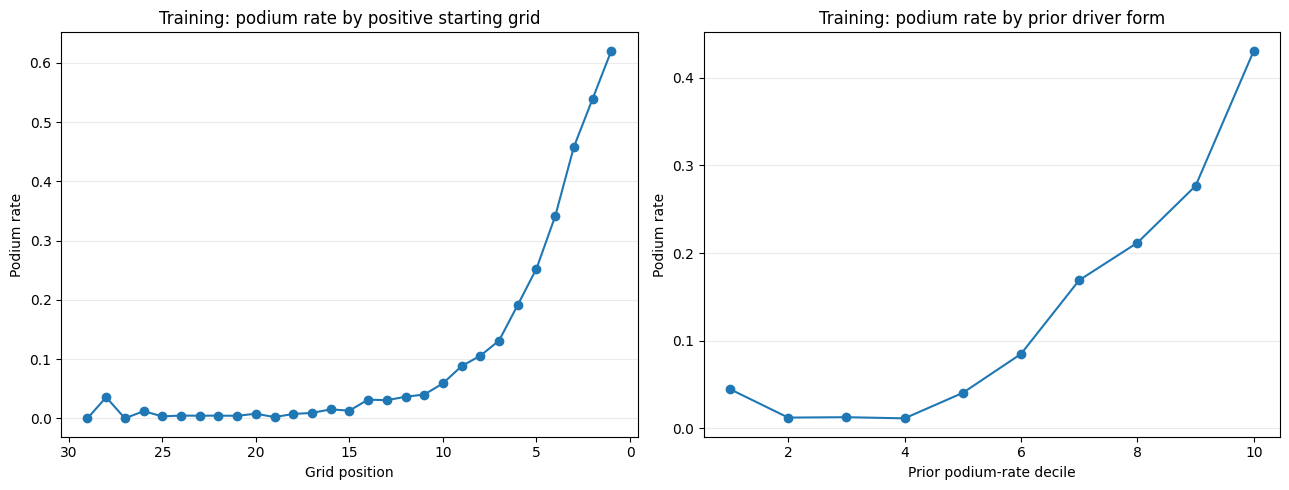

In [42]:
from pathlib import Path

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
grid_rates = feature_evidence.dropna(subset=["grid_position"]).groupby("grid_position", observed=True)["podium"].agg(["mean", "count"]).query("count >= 20")
axes[0].plot(grid_rates.index, grid_rates["mean"], marker="o")
axes[0].invert_xaxis()
axes[0].set(title="Training: podium rate by positive starting grid", xlabel="Grid position", ylabel="Podium rate")
axes[0].grid(axis="y", alpha=0.25)
form_data = feature_evidence.dropna(subset=["driver_prior_podium_rate"]).copy()
if not form_data.empty:
    form_data["prior_form_decile"] = pd.qcut(form_data["driver_prior_podium_rate"].rank(method="first"), 10, labels=False, duplicates="drop")
    form_rates = form_data.groupby("prior_form_decile", observed=True)["podium"].mean()
    axes[1].plot(form_rates.index + 1, form_rates.values, marker="o")
axes[1].set(title="Training: podium rate by prior driver form", xlabel="Prior podium-rate decile", ylabel="Podium rate")
axes[1].grid(axis="y", alpha=0.25)
fig.tight_layout()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUT_DIR / "feature_justification.png", dpi=160, bbox_inches="tight")
plt.show()

### Compare numeric feature associations

Calculate the correlation between each numeric allowed feature and the binary podium outcome, then plot the values. This provides a compact feature-screening comparison; `circuitId` is excluded because it is a nominal category, and correlation does not establish causality or determine model importance.

,correlation_with_podium
qualifying_position,-0.480552
grid_position,-0.435669
constructor_prior_standing_position,-0.352404
driver_prior_standing_position,-0.335073
driver_prior_mean_finish,-0.302812
is_home_race,-0.023388
year,0.014834
driver_circuit_prior_starts,0.156536
driver_prior_starts,0.176263
driver_circuit_prior_podium_rate,0.245963


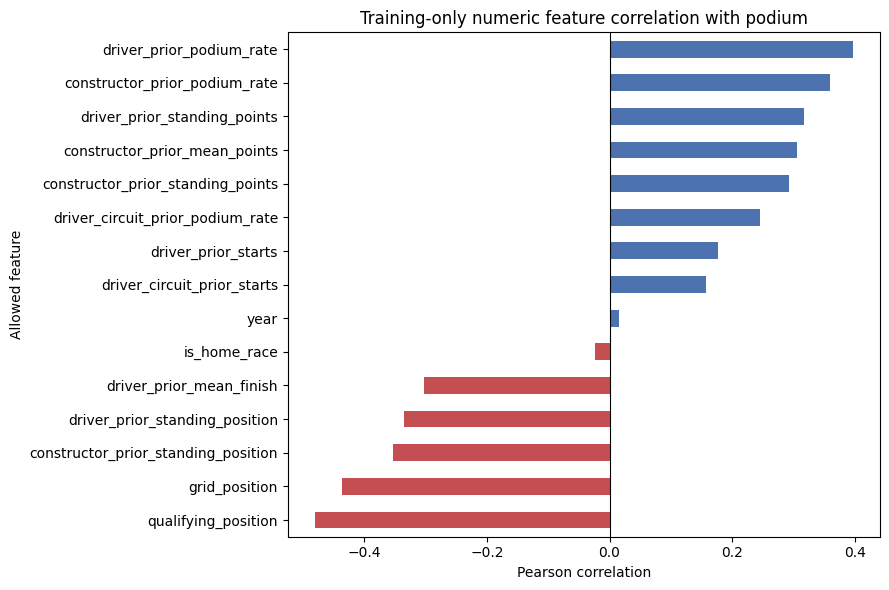

In [43]:
correlation_features = [
    "year", "grid_position", "qualifying_position", "is_home_race",
    "driver_prior_starts", "driver_prior_podium_rate", "driver_prior_mean_finish",
    "constructor_prior_podium_rate", "constructor_prior_mean_points",
    "driver_circuit_prior_starts", "driver_circuit_prior_podium_rate",
    "driver_prior_standing_points", "driver_prior_standing_position",
    "constructor_prior_standing_points", "constructor_prior_standing_position",
]
feature_correlations = feature_evidence[correlation_features + ["podium"]].corr(numeric_only=True)["podium"].drop("podium").dropna().sort_values()
display(feature_correlations.rename("correlation_with_podium").to_frame())
fig, ax = plt.subplots(figsize=(9, 6))
feature_correlations.plot(kind="barh", ax=ax, color=["#c44e52" if value < 0 else "#4c72b0" for value in feature_correlations])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Training-only numeric feature correlation with podium", xlabel="Pearson correlation", ylabel="Allowed feature")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "feature_correlations.png", dpi=160, bbox_inches="tight")
plt.show()

## Data Engineering Question 2 — Home podium rate controlling for grid

**Population:** inferred starters with a positive grid, a known nationality-to-country match and a binary podium outcome. Known non-starters, unknown start eligibility, zero/missing grids and ambiguous home-country matches are excluded with explicit counts. Zero is not labeled pit lane. The unit is one driver in one race.

**Joins:** results → races → circuits and drivers, with qualifying/standings providing model features. Unlike the entrant modeling table, Q2 explicitly conditions on inferred starts. Compare home/away within each exact grid; standardize both to the same pooled grid distribution on common home/away support. Grid-band lines are descriptive visualizations only; the adjusted result is based on exact grid positions, not bands.

Nationality, historical/dual nationality ambiguity, inferred start eligibility and sparse home observations limit the result. Grid control does not control driver strength, constructor, era or repeated observations. No causal home advantage or statistical significance is claimed.

,stage,rows
0,All modeling entrants,26668
1,Inferred starters,24990
2,Starters with positive grid,24918
3,"Starters, positive grid and known home status",24896


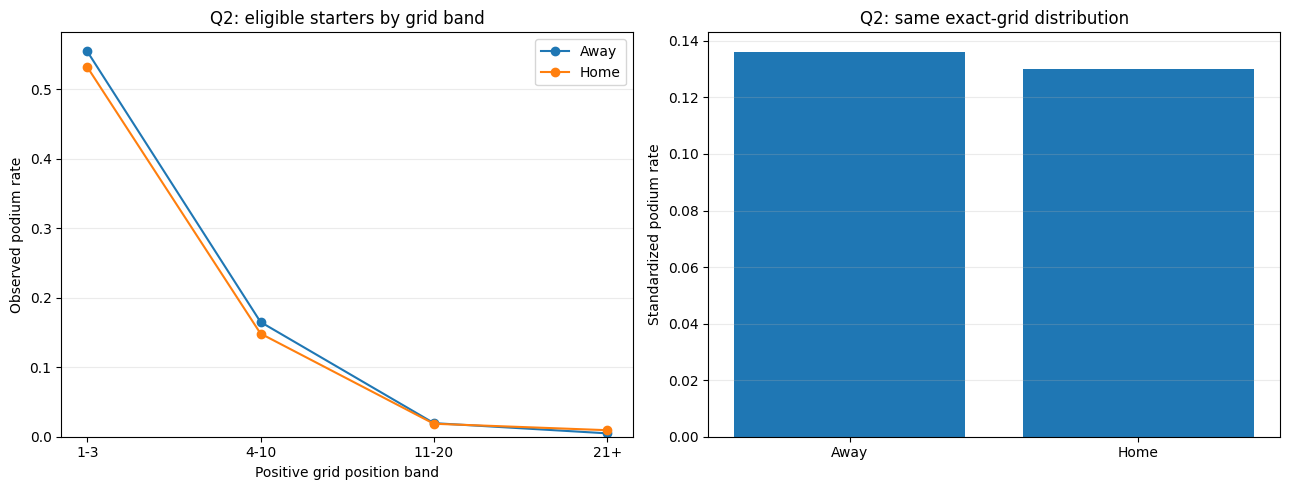

,known_home_status_starts,common_grid_support_starts,common_grid_support_fraction,grid_adjusted_away_podium_rate,grid_adjusted_home_podium_rate,grid_adjusted_rate_difference
0,24896,24884,0.999518,0.136221,0.130157,-0.006063


,grid_position,is_home_race,starts,podiums,rate
0,1.0,0,1039,668,0.642926
1,1.0,1,95,53,0.557895
2,2.0,0,1032,580,0.562016
3,2.0,1,90,46,0.511111
4,3.0,0,1041,477,0.458213
...,...,...,...,...,...
61,31.0,1,12,0,0.000000
62,32.0,0,3,0,0.000000
63,32.0,1,12,1,0.083333
64,33.0,1,11,0,0.000000


,grid_band,is_home_race,starts,podiums,podium_rate
0,1-3,0,3112,1725,0.554306
1,1-3,1,267,142,0.531835
2,4-10,0,7200,1188,0.165000
3,4-10,1,647,96,0.148377
4,11-20,0,9815,192,0.019562
5,11-20,1,964,18,0.018672
6,21+,0,2465,12,0.004868
7,21+,1,426,4,0.009390


Among 24,896 eligible starters, exact-grid standardization gives a home podium rate of 13.02% and an away rate of 13.62%. The home rate is 0.61 percentage points lower. Common-grid support covers 100.0% of eligible starters. This is a descriptive association, not a causal effect or a significance test. It is conditional on the documented starter, positive-grid and country-mapping policy; driver strength, constructor, era and repeated driver observations remain uncontrolled.

Saved Person 2 deliverables: /workspace/scratch/966e157ed519/person4_execution/person2


In [44]:
q2_population_audit = pd.DataFrame([
    {"stage": "All modeling entrants", "rows": len(modeling_table)},
    {"stage": "Inferred starters", "rows": int(modeling_table["start_class"].eq("started").sum())},
    {"stage": "Starters with positive grid", "rows": int((modeling_table["start_class"].eq("started") & modeling_table["grid_position"].gt(0)).sum())},
    {"stage": "Starters, positive grid and known home status", "rows": int((modeling_table["start_class"].eq("started") & modeling_table["grid_position"].gt(0) & modeling_table["is_home_race"].notna()).sum())},
])
display(q2_population_audit)
q2 = modeling_table.loc[modeling_table["start_class"].eq("started") & modeling_table["grid_position"].gt(0),
                        ["grid_position", "is_home_race", "podium"]].dropna().copy()
q2 = q2.loc[q2["is_home_race"].isin([0, 1])]
if q2.empty:
    raise ValueError("No eligible starters for Q2")
exact = q2.groupby(["grid_position", "is_home_race"], observed=True).agg(
    starts=("podium", "size"), podiums=("podium", "sum"), rate=("podium", "mean")).reset_index()
rate_wide = exact.pivot(index="grid_position", columns="is_home_race", values="rate")
starts_wide = exact.pivot(index="grid_position", columns="is_home_race", values="starts")
common_grids = rate_wide.dropna(subset=[0, 1]).index
if len(common_grids) == 0:
    raise ValueError("No common exact-grid support")
rate_wide, starts_wide = rate_wide.loc[common_grids], starts_wide.loc[common_grids]
weights = starts_wide.sum(axis=1) / starts_wide.to_numpy().sum()
assert np.isclose(weights.sum(), 1)
q2_summary = {
    "known_home_status_starts": len(q2),
    "common_grid_support_starts": int(starts_wide.to_numpy().sum()),
    "common_grid_support_fraction": float(starts_wide.to_numpy().sum() / len(q2)),
    "grid_adjusted_away_podium_rate": float((weights * rate_wide[0]).sum()),
    "grid_adjusted_home_podium_rate": float((weights * rate_wide[1]).sum()),
}
q2_summary["grid_adjusted_rate_difference"] = q2_summary["grid_adjusted_home_podium_rate"] - q2_summary["grid_adjusted_away_podium_rate"]
q2["grid_band"] = pd.cut(q2["grid_position"], [0, 3, 10, 20, np.inf], labels=["1-3", "4-10", "11-20", "21+"])
q2_grid_bands = q2.groupby(["grid_band", "is_home_race"], observed=True).agg(
    starts=("podium", "size"), podiums=("podium", "sum"), podium_rate=("podium", "mean")).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for flag, label in [(0, "Away"), (1, "Home")]:
    group = q2_grid_bands.loc[q2_grid_bands["is_home_race"].eq(flag)]
    axes[0].plot(group["grid_band"].astype(str), group["podium_rate"], marker="o", label=label)
axes[0].set(xlabel="Positive grid position band", ylabel="Observed podium rate", title="Q2: eligible starters by grid band")
axes[0].legend()
axes[1].bar(["Away", "Home"], [q2_summary["grid_adjusted_away_podium_rate"], q2_summary["grid_adjusted_home_podium_rate"]])
axes[1].set(ylabel="Standardized podium rate", title="Q2: same exact-grid distribution")
for ax in axes:
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "q2_home_podium_by_grid.png", dpi=160, bbox_inches="tight")
plt.show()
display(pd.DataFrame([q2_summary]))
display(exact)
display(q2_grid_bands)
difference = 100 * q2_summary["grid_adjusted_rate_difference"]
direction = "higher" if difference > 0 else "lower" if difference < 0 else "the same"
q2_interpretation = (
    f"Among {len(q2):,} eligible starters, exact-grid standardization gives a home podium rate of "
    f"{q2_summary['grid_adjusted_home_podium_rate']:.2%} and an away rate of "
    f"{q2_summary['grid_adjusted_away_podium_rate']:.2%}. The home rate is {abs(difference):.2f} percentage points "
    f"{direction}. Common-grid support covers {q2_summary['common_grid_support_fraction']:.1%} of eligible starters. "
    "This is a descriptive association, not a causal effect or a significance test. "
    "It is conditional on the documented starter, positive-grid and country-mapping policy; "
    "driver strength, constructor, era and repeated driver observations remain uncontrolled.")
display(Markdown(q2_interpretation))
pd.DataFrame([q2_summary]).to_csv(OUTPUT_DIR / "q2_summary.csv", index=False)
q2_population_audit.to_csv(OUTPUT_DIR / "q2_population_audit.csv", index=False)
exact.to_csv(OUTPUT_DIR / "q2_exact_grid_rates.csv", index=False)
weights.rename("pooled_weight").to_csv(OUTPUT_DIR / "q2_exact_grid_weights.csv")
q2_grid_bands.to_csv(OUTPUT_DIR / "q2_grid_band_rates.csv", index=False)
modeling_table.to_csv(OUTPUT_DIR / "modeling_table.csv", index=False)
(OUTPUT_DIR / "q2_interpretation.md").write_text(q2_interpretation, encoding="utf-8")
(OUTPUT_DIR / "allowed_features.json").write_text(json.dumps(ALLOWED_FEATURES, indent=2), encoding="utf-8")
print("Saved Person 2 deliverables:", OUTPUT_DIR)


## Person 3 — Q3 and Statistical Models

### Data-Engineering Question 3 — Mechanical Retirement Rate by Constructor

**Question:** Which constructors have the highest mechanical-retirement rate in 2014–2021 (turbo-hybrid era) vs. 2022–2024 (ground-effect era)?

**Tables joined (multi-hop):** `results` → `status` (why the race ended) → `races` (year) → `constructors` (team name).

**Grain:** one row per inferred driver–race start, using Person 2’s documented start policy on the unique cleaned results. Ambiguous starts are excluded and counted in the population audit.

**Definition used:** a *mechanical retirement* is a start that ended early because a car component failed.
Crashes, driver errors, disqualifications and regulation decisions are **not** mechanical.

**Rate:** `mechanical retirements / race starts` per constructor per era.

**Pre-race cutoff:** not relevant here — this is a descriptive, post-race analysis. `status` is post-race information and is **never** used as a model feature.

In [45]:
PERSON3_OUTPUT_DIR = Path(os.environ.get("F1_PERSON3_OUTPUT_DIR", "/kaggle/working/person3_outputs"))
PERSON3_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# Retain Person 1/2 inputs unchanged throughout this section.
person3_input_fingerprints = {name: pd.util.hash_pandas_object(frame, index=True).sum()
                              for name, frame in tables_clean.items()}
person3_model_fingerprint = pd.util.hash_pandas_object(modeling_table, index=True).sum()


In [46]:
res = tables_clean["results"].copy()
res["statusId"] = pd.to_numeric(res["statusId"], errors="coerce")
res["laps"] = pd.to_numeric(res["laps"], errors="coerce")

q3 = (
    res[["raceId", "driverId", "constructorId", "statusId", "laps", "grid"]]
    .merge(tables_clean["status"][["statusId", "status"]], on="statusId", how="left", validate="many_to_one")
    .merge(tables_clean["races"][["raceId", "year"]], on="raceId", how="left", validate="many_to_one")
    .merge(tables_clean["constructors"][["constructorId", "name"]], on="constructorId", how="left", validate="many_to_one")
    .rename(columns={"name": "constructor"})
)

q3 = q3[q3["year"].between(2014, 2024)].copy()
q3["era"] = np.where(q3["year"] <= 2021, "2014–2021", "2022–2024")

print("Rows 2014–2024:", len(q3))
print("Missing status after join:", q3["status"].isna().sum())
print("Missing constructor after join:", q3["constructor"].isna().sum())
assert not q3.duplicated(["raceId", "driverId"]).any()
assert q3[["status", "year", "constructor"]].notna().all().all()
q3["start_class"] = classify_start_status(q3)
race_distance = tables_clean["results"].groupby("raceId")["laps"].max()
q3["race_max_laps"] = q3["raceId"].map(race_distance)
q3["ended_early"] = q3["laps"].lt(q3["race_max_laps"])
q3_population_audit = q3.groupby(["era", "start_class"], observed=True).size().rename("rows").reset_index()
display(q3_population_audit)


,era,start_class,rows
0,2014–2021,nonstarter,7
1,2014–2021,started,3254
2,2014–2021,unknown,6
3,2022–2024,nonstarter,4
4,2022–2024,started,1353
5,2022–2024,unknown,2


Rows 2014–2024: 4626
Missing status after join: 0
Missing constructor after join: 0


In [47]:
status_counts = q3["status"].value_counts()
print("Distinct status values in 2014–2024:", len(status_counts))
status_counts

status
Finished          2403
+1 Lap            1178
+2 Laps            208
Collision          150
Accident            85
                  ... 
Water pump           1
Cooling system       1
Fuel pump            1
Differential         1
+7 Laps              1
Name: count, Length: 66, dtype: int64

Distinct status values in 2014–2024: 66


### Status mapping

Sama’s explicit component/status sets are retained, with ambiguous labels removed from the mechanical numerator. Engine, gearbox, hydraulics, brakes and power-unit failures count. Crash, driver, regulation and non-start outcomes do not. Generic `Retired`, tyre/puncture, `Technical`, `Vibrations`, wing/undertray/wheel damage and generic fuel/refuelling/stalling labels do not establish a component failure and are conservatively excluded. This dataset records a status label, not a verified causal investigation; even explicit component labels can be imperfect.

The numerator additionally requires fewer completed laps than the maximum recorded for that race, an operational early-ending check. The denominator uses the same inferred-start policy as P2: unknown starts are excluded, and zero-lap positive-grid retirements can count. A recorded mechanical problem before a start must not become a retirement. `Not restarted` is treated as ambiguous rather than proof of never starting.

All observed statuses are audited. Missing or unmapped labels stop the calculation. Constructor IDs remain separate across team renamings. At least 30 inferred starts per constructor–era are required for displayed rankings; the full unscreened rates are also exported. These choices and exclusions must accompany the report’s Q3 answer.


In [48]:
MECHANICAL = {
    "Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical",
    "Radiator", "Suspension", "Brakes", "Differential", "Overheating", "Mechanical",
    "Driveshaft", "Fuel pressure", "Water pressure", "Wheel", "Throttle", "Steering",
    "Technical", "Electronics", "Exhaust", "Oil leak", "Wheel rim", "Water leak",
    "Fuel pump", "Track rod", "Oil pressure", "Engine fire", "Engine misfire",
    "Wheel nut", "Pneumatics", "Handling", "Fire", "Wheel bearing", "Fuel system",
    "Oil line", "Fuel leak", "Power loss", "Vibrations", "Drivetrain", "Ignition",
    "Chassis", "Battery", "Halfshaft", "Crankshaft", "Alternator", "Oil pump",
    "Injection", "Distributor", "Turbo", "CV joint", "Water pump", "Spark plugs",
    "Fuel pipe", "Oil pipe", "Axle", "Water pipe", "Magneto", "Supercharger",
    "Power Unit", "ERS", "Brake duct", "Seat", "Undertray", "Cooling system",
    "Heat shield fire", "Front wing", "Rear wing", "Broken wing", "Launch control",
    "Fuel", "Refuelling", "Stalled", "Driver Seat", "Safety belt",
}

ACCIDENT_DRIVER = {
    "Accident", "Collision", "Collision damage", "Spun off", "Damage", "Debris",
    "Fatal accident", "Injured", "Injury", "Eye injury", "Physical", "Illness",
    "Driver unwell",
}

NOT_STARTED = {
    "Did not qualify", "Did not prequalify", "107% Rule", "Did not start",
    "Not restarted",
}

OTHER = {
    "Disqualified", "Excluded", "Withdrew", "Retired", "Not classified",
    "Tyre", "Puncture", "Tyre puncture", "Out of fuel", "Underweight",
    "Safety", "Safety concerns", "Fuel rig",
}


def status_group(s):
    if pd.isna(s):
        return "unmapped"
    if s == "Finished" or str(s).startswith("+"):
        return "finished"
    if s in MECHANICAL:
        return "mechanical"
    if s in ACCIDENT_DRIVER:
        return "accident_driver"
    if s in NOT_STARTED:
        return "not_started"
    if s in OTHER:
        return "other"
    return "unmapped"


# Ambiguous causes cannot establish component failure from this label alone.
AMBIGUOUS_COMPONENT_LABELS = {
    "Handling", "Fire", "Fuel", "Refuelling", "Stalled", "Technical", "Vibrations",
    "Front wing", "Rear wing", "Broken wing", "Undertray", "Wheel", "Wheel nut",
    "Seat", "Driver Seat", "Safety belt", "Launch control",
}
MECHANICAL = MECHANICAL - AMBIGUOUS_COMPONENT_LABELS
OTHER = OTHER | AMBIGUOUS_COMPONENT_LABELS

q3["status_group"] = q3["status"].apply(status_group)

unmapped = q3.loc[q3["status_group"] == "unmapped", "status"].value_counts()
print("Unmapped statuses:", len(unmapped))
print(unmapped)

q3["status_group"].value_counts()
assert q3["status_group"].ne("unmapped").all(), "Review new/missing Q3 status labels"


Unmapped statuses: 0
Series([], Name: count, dtype: int64)


In [49]:
starts = q3[q3["start_class"].eq("started")].copy()
starts["mechanical"] = (starts["status_group"].eq("mechanical") & starts["ended_early"]).astype(int)

MIN_STARTS = 30

mech_rates = (
    starts.groupby(["era", "constructor"])
    .agg(starts=("mechanical", "size"), mech_dnfs=("mechanical", "sum"))
    .reset_index()
)
mech_rates["mech_rate_pct"] = mech_rates["mech_dnfs"] / mech_rates["starts"] * 100
all_mech_rates = mech_rates.copy()
mech_rates = mech_rates[mech_rates["starts"] >= MIN_STARTS]

era_overall = starts.groupby("era")["mechanical"].mean() * 100
print("Overall mechanical-retirement rate per era (%):")
print(era_overall.round(2))

for era in ["2014–2021", "2022–2024"]:
    print(f"\nTop 5 constructors, {era}:")
    print(
        mech_rates[mech_rates["era"] == era]
        .sort_values("mech_rate_pct", ascending=False)
        .head(5)[["constructor", "starts", "mech_dnfs", "mech_rate_pct"]]
        .round(2)
        .to_string(index=False)
    )

Overall mechanical-retirement rate per era (%):
era
2014–2021    9.04
2022–2024    5.47
Name: mechanical, dtype: float64

Top 5 constructors, 2014–2021:
constructor  starts  mech_dnfs  mech_rate_pct
   Caterham      34          8          23.53
   Lotus F1      75         13          17.33
 Toro Rosso     242         39          16.12
    McLaren     318         43          13.52
    Renault     200         27          13.50

Top 5 constructors, 2022–2024:
   constructor  starts  mech_dnfs  mech_rate_pct
    Alfa Romeo      88         10          11.36
Alpine F1 Team     136         15          11.03
    AlphaTauri      88          6           6.82
      Williams     134          7           5.22
       Ferrari     135          7           5.19


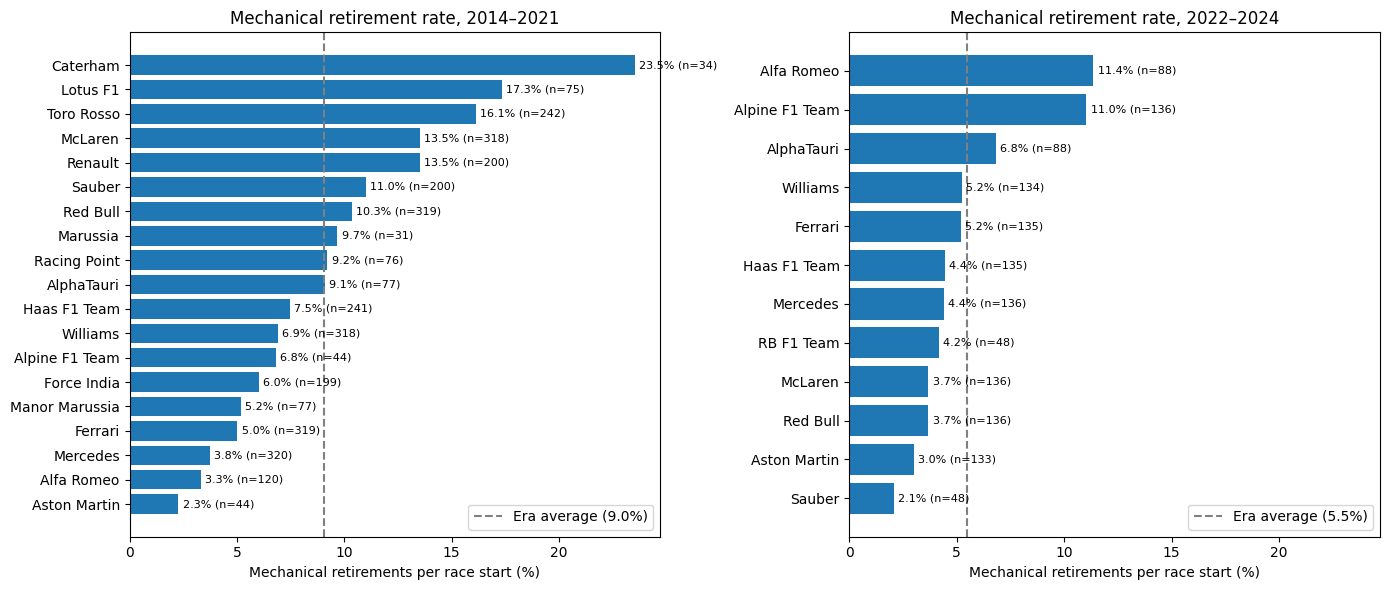

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)

for ax, era in zip(axes, ["2014–2021", "2022–2024"]):
    d = mech_rates[mech_rates["era"] == era].sort_values("mech_rate_pct")
    ax.barh(d["constructor"], d["mech_rate_pct"])
    ax.axvline(era_overall[era], linestyle="--", color="gray",
               label=f"Era average ({era_overall[era]:.1f}%)")
    for y, (rate, n) in enumerate(zip(d["mech_rate_pct"], d["starts"])):
        ax.text(rate + 0.2, y, f"{rate:.1f}% (n={n})", va="center", fontsize=8)
    ax.set_title(f"Mechanical retirement rate, {era}")
    ax.set_xlabel("Mechanical retirements per race start (%)")
    ax.legend(loc="lower right")

plt.tight_layout()
fig.savefig(PERSON3_OUTPUT_DIR / "q3_mechanical_retirement_rates.png", dpi=160, bbox_inches="tight")
plt.show()

In [51]:
top_causes = (
    starts[starts["mechanical"] == 1]
    .groupby(["era", "status"])
    .size()
    .reset_index(name="count")
    .sort_values(["era", "count"], ascending=[True, False])
    .groupby("era")
    .head(6)
)
top_causes

,era,status,count
9,2014–2021,Engine,59
2,2014–2021,Brakes,44
18,2014–2021,Power Unit,34
12,2014–2021,Gearbox,33
23,2014–2021,Suspension,24
7,2014–2021,Electrical,13
33,2022–2024,Engine,21
37,2022–2024,Gearbox,9
42,2022–2024,Power Unit,7
38,2022–2024,Hydraulics,5


### Q3 answer and limitations

The next cell computes the interpretation from the current corrected rates, avoiding stale hand-entered percentages. Rates describe recorded component-failure retirements under the documented policy; they do not establish that an era rule change caused improved reliability. Team strength, entries, race calendars and sample sizes differ. Unknown starts and ambiguous failure causes can affect rankings. See the exported full rates, population audit and status audit for exclusions.


In [52]:
q3_lines = []
for era in ["2014–2021", "2022–2024"]:
    leaders = mech_rates.loc[mech_rates["era"].eq(era)].nlargest(5, "mech_rate_pct")
    labels = [f"{r.constructor}: {r.mech_rate_pct:.2f}% ({r.mech_dnfs}/{r.starts})" for r in leaders.itertuples()]
    q3_lines.append(f"**{era}:** " + "; ".join(labels) + f". Era rate: {era_overall[era]:.2f}%.")
q3_interpretation = "\n\n".join(q3_lines) + "\n\nDescriptive recorded-cause rates only, conditional on the documented inferred-start, early-ending and conservative status policies. No causal claim or significance test. Renamed constructors remain separate; displayed groups require at least 30 starts."
display(Markdown(q3_interpretation))
q3_status_audit = q3.groupby(["era", "status", "status_group", "start_class", "ended_early"], dropna=False).size().rename("rows").reset_index()
all_mech_rates.to_csv(PERSON3_OUTPUT_DIR / "q3_all_constructor_rates.csv", index=False)
mech_rates.to_csv(PERSON3_OUTPUT_DIR / "q3_displayed_constructor_rates.csv", index=False)
q3_status_audit.to_csv(PERSON3_OUTPUT_DIR / "q3_status_audit.csv", index=False)
q3_population_audit.to_csv(PERSON3_OUTPUT_DIR / "q3_population_audit.csv", index=False)
top_causes.to_csv(PERSON3_OUTPUT_DIR / "q3_top_failure_causes.csv", index=False)
(PERSON3_OUTPUT_DIR / "q3_interpretation.md").write_text(q3_interpretation, encoding="utf-8")


**2014–2021:** Caterham: 23.53% (8/34); Lotus F1: 17.33% (13/75); Toro Rosso: 16.12% (39/242); McLaren: 13.52% (43/318); Renault: 13.50% (27/200). Era rate: 9.04%.

**2022–2024:** Alfa Romeo: 11.36% (10/88); Alpine F1 Team: 11.03% (15/136); AlphaTauri: 6.82% (6/88); Williams: 5.22% (7/134); Ferrari: 5.19% (7/135). Era rate: 5.47%.

Descriptive recorded-cause rates only, conditional on the documented inferred-start, early-ending and conservative status policies. No causal claim or significance test. Renamed constructors remain separate; displayed groups require at least 30 starts.

586

### Statistical models — preprocessing and chronological evaluation

Sama’s branch supplied Q3 only; this section completes Person 3’s missing conventional ML deliverables. Both models use the identical P2 entrant table, target and 16 allowed features. Logistic Regression is the simple statistical baseline; Random Forest tests nonlinear relationships and interactions. Neither model uses current outcomes, status or retrospective start eligibility as a predictor or cohort filter.

Train: years through 2019. Validation: 2020–2021. Test: 2022–2024. Time order simulates prediction in later seasons and avoids a random split mixing future races into training. The recent test period also exposes era drift. Histories in later races may use completed earlier races, as at deployment, but models/preprocessing are fitted on training only. Validation selects hyperparameters by average precision (primary PR metric), with ROC-AUC as a tie-breaker. Thresholds maximize validation F1; test data is accessed for evaluation only after these choices are frozen.

Numeric missing values: training medians and missing indicators, then standard scaling. Circuit ID is nominal: training most-frequent imputation and one-hot encoding, with unseen circuits ignored. All transformations live inside each fitted pipeline. Compare `class_weight=None` with `balanced` in both models instead of assuming reweighting helps; no synthetic samples cross time splits. Scaling is appropriate for Logistic Regression and is harmless for tree splits, allowing a shared feature transformation.

PR-AUC is reported as **average precision (AP)**, not trapezoidal PR area. ROC-AUC, F1, precision and recall are also reported on train/validation/test. Accuracy is supplementary. AP is primary because podiums are rare; ROC-AUC is secondary for overall ranking, while F1 evaluates the validation-selected operating threshold. Validation scores are selection scores rather than an unbiased estimate. These choices are fixed before inspecting test results.


In [53]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
    precision_score, recall_score, accuracy_score, precision_recall_curve,
    RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay)
from sklearn.base import clone
import sklearn

FEATURES = list(ALLOWED_FEATURES)
assert "podium" not in FEATURES
split_masks = {"train": modeling_table["year"].le(2019),
               "validation": modeling_table["year"].between(2020, 2021),
               "test": modeling_table["year"].between(2022, 2024)}
assert sum(mask.astype(int) for mask in split_masks.values()).eq(1).all()
split_data = {name: (modeling_table.loc[mask, FEATURES].copy(),
                     modeling_table.loc[mask, "podium"].astype(int).copy())
              for name, mask in split_masks.items()}
split_summary = pd.DataFrame([{"split": name, "rows": int(mask.sum()),
    "first_year": int(modeling_table.loc[mask, "year"].min()),
    "last_year": int(modeling_table.loc[mask, "year"].max()),
    "podium_rate": float(modeling_table.loc[mask, "podium"].mean())}
    for name, mask in split_masks.items()])
display(split_summary)
assert split_summary["rows"].sum() == len(modeling_table)
assert all(y.nunique() == 2 for X, y in split_data.values())

numeric_features = [f for f in FEATURES if f != "circuitId"]
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]), numeric_features),
    ("circuit", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), ["circuitId"]),
])
X_train, y_train = split_data["train"]
X_validation, y_validation = split_data["validation"]
# Small, explicit tuning grids keep every attempt reviewable and Run All practical.
candidates = []
for weight in [None, "balanced"]:
    for C in [0.1, 1.0]:
        candidates.append(("Logistic Regression", {"C": C, "class_weight": weight},
            LogisticRegression(C=C, class_weight=weight, max_iter=3000, random_state=42)))
    for leaf, depth in [(2, None), (8, 12)]:
        candidates.append(("Random Forest", {"min_samples_leaf": leaf, "max_depth": depth, "class_weight": weight},
            RandomForestClassifier(n_estimators=150, min_samples_leaf=leaf, max_depth=depth,
                                   class_weight=weight, random_state=42, n_jobs=2)))


,split,rows,first_year,last_year,podium_rate
0,train,24529,1950,2019,0.124628
1,validation,780,2020,2021,0.150000
2,test,1359,2022,2024,0.150110


### Training and validation tuning — all attempts retained

Each candidate is fitted on training rows only. Hyperparameter comparisons below use validation ranking scores; no test score is computed in this cell. After choosing one candidate per family, each threshold is frozen using validation F1. Models are not refitted on validation afterward, so validation reports refer to the exact model later tested.


In [54]:
tuning_rows = []
selected_models = {}
selected_ranks = {}
for family, parameters, estimator in candidates:
    fitted = Pipeline([("preprocess", clone(preprocessor)), ("model", estimator)])
    fitted.fit(X_train, y_train)
    validation_probability = fitted.predict_proba(X_validation)[:, 1]
    ap = average_precision_score(y_validation, validation_probability)
    auc = roc_auc_score(y_validation, validation_probability)
    tuning_rows.append({"model": family, "parameters": json.dumps(parameters),
                        "validation_AP": ap, "validation_ROC_AUC": auc})
    if family not in selected_ranks or (ap, auc) > selected_ranks[family]:
        selected_models[family] = fitted
        selected_ranks[family] = (ap, auc)
tuning_results = pd.DataFrame(tuning_rows)
display(tuning_results)
thresholds = {}
selection_rows = []
for family, fitted in selected_models.items():
    probability = fitted.predict_proba(X_validation)[:, 1]
    precision, recall, candidate_thresholds = precision_recall_curve(y_validation, probability)
    scores = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-15)
    best_index = int(np.argmax(scores)) # deterministic first threshold among ties
    thresholds[family] = float(candidate_thresholds[best_index])
    selection_rows.append({"model": family, "threshold": thresholds[family],
                           "validation_F1": float(scores[best_index]),
                           "parameters": json.dumps(fitted.named_steps["model"].get_params(), default=str)})
selection_results = pd.DataFrame(selection_rows)
display(selection_results[["model", "threshold", "validation_F1"]])
# Frozen choices. Test is not used to select either a candidate or threshold.
frozen_selection = selection_results.copy(deep=True)


,model,parameters,validation_AP,validation_ROC_AUC
0,Logistic Regression,"{""C"": 0.1, ""class_weight"": null}",0.737523,0.928311
1,Logistic Regression,"{""C"": 1.0, ""class_weight"": null}",0.731590,0.928272
2,Random Forest,"{""min_samples_leaf"": 2, ""max_depth"": null, ""cl...",0.694632,0.925140
3,Random Forest,"{""min_samples_leaf"": 8, ""max_depth"": 12, ""clas...",0.718048,0.929252
4,Logistic Regression,"{""C"": 0.1, ""class_weight"": ""balanced""}",0.726050,0.928117
5,Logistic Regression,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.706771,0.927602
6,Random Forest,"{""min_samples_leaf"": 2, ""max_depth"": null, ""cl...",0.696177,0.926210
7,Random Forest,"{""min_samples_leaf"": 8, ""max_depth"": 12, ""clas...",0.698611,0.928504


,model,threshold,validation_F1
0,Logistic Regression,0.422013,0.701754
1,Random Forest,0.441623,0.713043


### Frozen-model evaluation and comparison

Report every selected model on identical rows in each split. ROC and PR curves compare ranking behavior; confusion matrices use the previously frozen validation thresholds. The PR plot includes the no-skill prevalence baseline. Training scores reveal fitting behavior; a large train-to-later-period gap can reflect both overfitting and historical distribution shift, rather than proving either by itself.


,model,split,rows,threshold,ROC_AUC,PR_AUC_AP,F1,precision,recall,accuracy
0,Logistic Regression,train,24529,0.4220,0.9056,0.5652,0.5395,0.5794,0.5047,0.8926
1,Logistic Regression,validation,780,0.4220,0.9283,0.7375,0.7018,0.7207,0.6838,0.9128
2,Logistic Regression,test,1359,0.4220,0.9317,0.6719,0.6575,0.6154,0.7059,0.8896
3,Random Forest,train,24529,0.4416,0.9339,0.6770,0.5704,0.6934,0.4845,0.9090
4,Random Forest,validation,780,0.4416,0.9293,0.7180,0.7130,0.7257,0.7009,0.9154
5,Random Forest,test,1359,0.4416,0.9385,0.7076,0.6584,0.6650,0.6520,0.8985


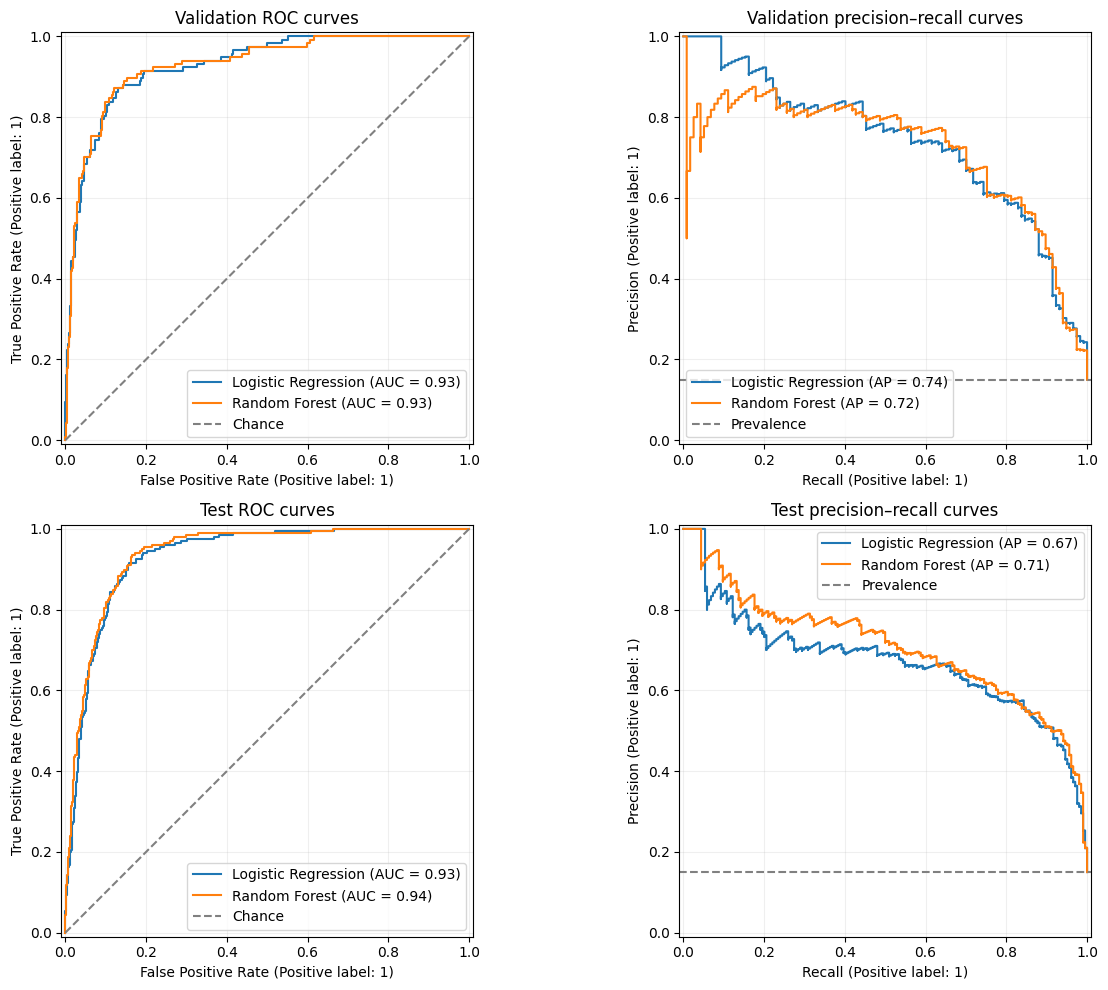

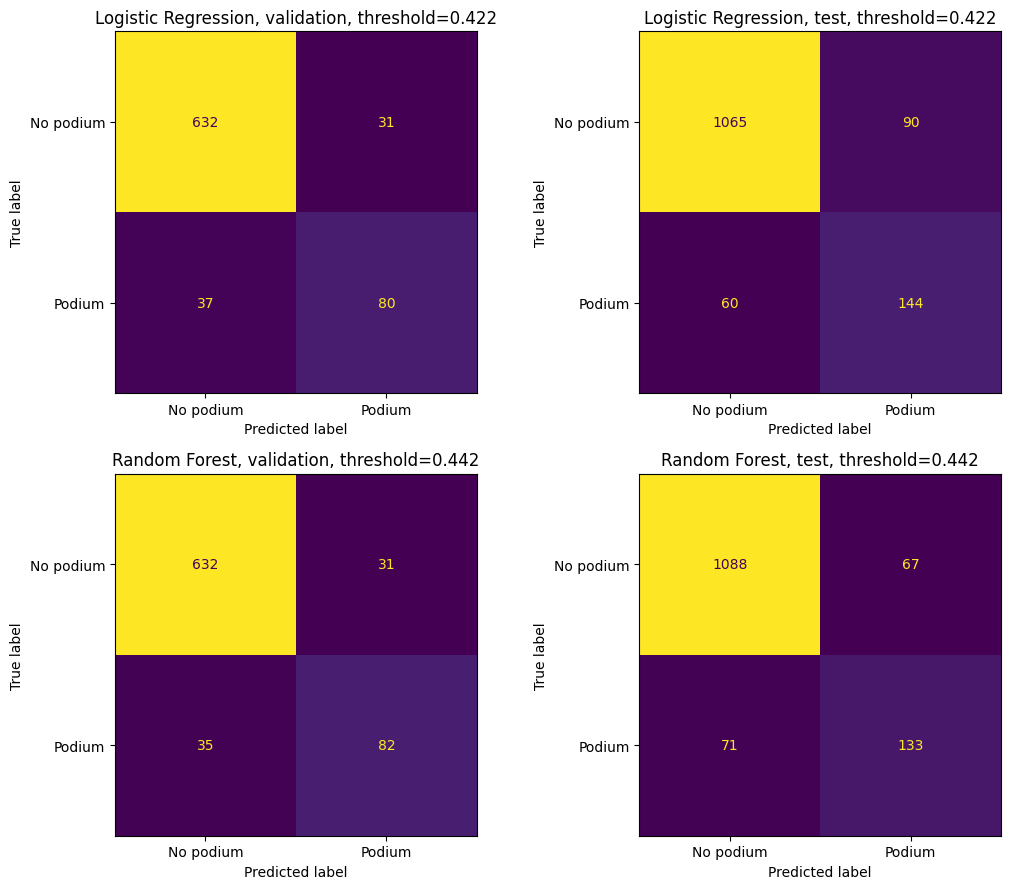

In [55]:
metric_rows = []
model_predictions = {}
for family, fitted in selected_models.items():
    for split, (X_part, y_part) in split_data.items():
        probability = fitted.predict_proba(X_part)[:, 1]
        prediction = (probability >= thresholds[family]).astype(int)
        model_predictions[(family, split)] = (probability, prediction)
        metric_rows.append({"model": family, "split": split, "rows": len(y_part),
            "threshold": thresholds[family], "ROC_AUC": roc_auc_score(y_part, probability),
            "PR_AUC_AP": average_precision_score(y_part, probability),
            "F1": f1_score(y_part, prediction, zero_division=0),
            "precision": precision_score(y_part, prediction, zero_division=0),
            "recall": recall_score(y_part, prediction, zero_division=0),
            "accuracy": accuracy_score(y_part, prediction)})
model_comparison = pd.DataFrame(metric_rows)
display(model_comparison.round(4))
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for row, split in enumerate(["validation", "test"]):
    y_part = split_data[split][1]
    for family in selected_models:
        probability = model_predictions[(family, split)][0]
        RocCurveDisplay.from_predictions(y_part, probability, name=family, ax=axes[row, 0])
        PrecisionRecallDisplay.from_predictions(y_part, probability, name=family, ax=axes[row, 1])
    axes[row, 0].plot([0, 1], [0, 1], "--", color="gray", label="Chance")
    axes[row, 1].axhline(y_part.mean(), linestyle="--", color="gray", label="Prevalence")
    axes[row, 0].set_title(f"{split.title()} ROC curves")
    axes[row, 1].set_title(f"{split.title()} precision–recall curves")
    for ax in axes[row]: ax.legend(); ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(PERSON3_OUTPUT_DIR / "statistical_roc_pr_curves.png", dpi=160, bbox_inches="tight")
plt.show()
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for row, family in enumerate(selected_models):
    for col, split in enumerate(["validation", "test"]):
        ConfusionMatrixDisplay.from_predictions(split_data[split][1], model_predictions[(family, split)][1],
            display_labels=["No podium", "Podium"], colorbar=False, ax=axes[row, col])
        axes[row, col].set_title(f"{family}, {split}, threshold={thresholds[family]:.3f}")
fig.tight_layout()
fig.savefig(PERSON3_OUTPUT_DIR / "statistical_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()


### Interpretation, limitations and handoff

Logistic Regression learns an additive linear score in transformed features; it can miss interactions and nonlinear effects. Random Forest averages decision trees and can learn interactions, but can overfit historical driver/team patterns and struggle with new eras. Neither model’s coefficients nor its predictive success establish causal effects. Lifetime form and historical points are sensitive to era/scoring changes; early qualifying missingness and the entrant-versus-starter distinction remain limitations from P2.

Do not change features, thresholds or hyperparameters in response to the test results below. Any further model selection must return to training/validation. The shallow neural network must use these same features and split masks for comparison. Feature-group ablation, preprocessing-order experiments, XAI and inference remain in the later team section, not silently declared complete here. Q3 and statistical results/figures must also be copied into the team report.


In [56]:
comparison_lines = []
for family in selected_models:
    rows = model_comparison.loc[model_comparison["model"].eq(family)].set_index("split")
    comparison_lines.append(f"**{family}:** AP train/validation/test = " + "/".join(f"{rows.loc[s, 'PR_AUC_AP']:.3f}" for s in ["train", "validation", "test"]) +
        f"; test ROC-AUC {rows.loc['test', 'ROC_AUC']:.3f}, F1 {rows.loc['test', 'F1']:.3f}, precision {rows.loc['test', 'precision']:.3f}, recall {rows.loc['test', 'recall']:.3f}. " +
        f"Threshold {thresholds[family]:.3f} was selected on validation only.")
model_interpretation = "\n\n".join(comparison_lines)
display(Markdown(model_interpretation))
for filename, frame in [("split_summary.csv", split_summary), ("tuning_results.csv", tuning_results),
                        ("selected_models.csv", selection_results), ("model_comparison.csv", model_comparison)]:
    frame.to_csv(PERSON3_OUTPUT_DIR / filename, index=False)
(PERSON3_OUTPUT_DIR / "statistical_interpretation.md").write_text(model_interpretation, encoding="utf-8")
(PERSON3_OUTPUT_DIR / "model_contract.json").write_text(json.dumps({"features": FEATURES,
    "target": "podium", "train_end": 2019, "validation_years": [2020, 2021],
    "test_years": [2022, 2024], "thresholds": thresholds, "primary_metric": "average_precision",
    "secondary_metric": "ROC_AUC", "sklearn_version": sklearn.__version__}, indent=2), encoding="utf-8")
# Predictions include stable keys so every downstream model can verify identical rows.
for split, mask in split_masks.items():
    predictions = modeling_table.loc[mask, ["raceId", "driverId", "podium"]].copy()
    for family in selected_models:
        predictions[family + " probability"] = model_predictions[(family, split)][0]
        predictions[family + " prediction"] = model_predictions[(family, split)][1]
    predictions.to_csv(PERSON3_OUTPUT_DIR / f"statistical_predictions_{split}.csv", index=False)
for name, frame in tables_clean.items():
    assert pd.util.hash_pandas_object(frame, index=True).sum() == person3_input_fingerprints[name]
assert pd.util.hash_pandas_object(modeling_table, index=True).sum() == person3_model_fingerprint
pd.testing.assert_frame_equal(selection_results, frozen_selection)
print("Person 3 complete. P1/P2 inputs preserved; all exports:", PERSON3_OUTPUT_DIR)


**Logistic Regression:** AP train/validation/test = 0.565/0.738/0.672; test ROC-AUC 0.932, F1 0.658, precision 0.615, recall 0.706. Threshold 0.422 was selected on validation only.

**Random Forest:** AP train/validation/test = 0.677/0.718/0.708; test ROC-AUC 0.938, F1 0.658, precision 0.665, recall 0.652. Threshold 0.442 was selected on validation only.

Person 3 complete. P1/P2 inputs preserved; all exports: /workspace/scratch/966e157ed519/person4_execution/person3


# Person 4 — Zeina: Neural Network, Ablation, XAI & Inference

Integrated from her newer structured notebook. Her model architectures, preprocessing, training/selection, ablation and explanation workflows are retained. Required changes align metrics and rows with P3, refresh stale findings, make inference input validation explicit, and add the two missing preprocessing-order comparisons. Her original branch remains unchanged.

## Part 4 Overview

### Goal

The aim of this section is to train and evaluate a **shallow neural network** for podium prediction using only information available **after qualifying and before the race starts**, then explain the model using ablation and XAI methods.

### Part 4 Workflow

| Stage | Purpose |
|---|---|
| Data handoff | Reuse Person 2's leakage-safe `modeling_table` |
| Validation | Confirm target, year field, class balance, and row uniqueness |
| Feature selection | Use Person 2's exact 16 allowed predictors |
| Chronological split | Train on past seasons and evaluate on future seasons |
| Preprocessing | Impute missing values, scale numeric features, one-hot encode circuit |
| NN Trial 1 | Baseline shallow architecture |
| NN Trial 2 | Larger shallow architecture with dropout |
| Model selection | Choose using validation PR-AUC |
| Test evaluation | Evaluate the selected model once on unseen test seasons |
| Ablation | Remove feature groups to measure their contribution |
| Permutation importance | Measure validation PR-AUC drop after feature shuffling |
| SHAP | Explain global and local model behavior |
| Inference | Predict on complete and partially missing records |

### Important Evaluation Principle

The **test set is not used to select the architecture, threshold, or hyperparameters**.  
All choices are made using training and validation data only, and the test period is kept for final unseen evaluation.


## 4.1 Data Handoff & Validation

### Reusing Person 2's Modeling Table

Person 2 constructs the final leakage-safe `modeling_table`. Rather than rebuilding the dataset, this section takes a copy of that table so the neural network uses the **same driver-race rows and engineered features** as the rest of the team pipeline.

The modeling table contains **26,668 driver-race observations; additional P2 audit metadata is excluded from the 16 allowed predictors**.


In [57]:
PERSON4_OUTPUT_DIR = Path(os.environ.get("F1_PERSON4_OUTPUT_DIR", "/kaggle/working/person4_outputs"))
PERSON4_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
person4_input_fingerprints = {name: pd.util.hash_pandas_object(frame, index=True).sum()
                              for name, frame in tables_clean.items()}
person4_model_fingerprint = pd.util.hash_pandas_object(modeling_table, index=True).sum()
# Save this section's original plots without rewriting Zeina's plot functions.
person4_plot_files = []
def person4_show(*args, _original_show=plt.show, **kwargs):
    for figure_number in plt.get_fignums():
        figure = plt.figure(figure_number)
        if any("SHAP" in axis.get_title() for axis in figure.axes):
            figure.set_size_inches(max(16, figure.get_figwidth()), figure.get_figheight())
            figure.tight_layout()
        filename = f"person4_figure_{len(person4_plot_files) + 1:02d}.png"
        figure.savefig(PERSON4_OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
        person4_plot_files.append(filename)
    result = _original_show(*args, **kwargs)
    plt.close("all")
    return result
plt.show = person4_show


In [58]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_recall_curve, roc_curve, confusion_matrix,
    classification_report
)

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

# Keep warnings visible during verification.

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Small fixed thread pools keep Run All usable in CPU and constrained environments.
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
print("TensorFlow:", tf.__version__)

try:
    import shap
    SHAP_AVAILABLE = True
    print("SHAP:", shap.__version__)
except Exception as e:
    SHAP_AVAILABLE = False
    raise ImportError("SHAP is required for this section; install shap and rerun.") from e

TensorFlow: 2.20.0
SHAP: 0.49.1


In [59]:
df = modeling_table.copy()
DATA_READY = True

print("Loaded modeling table from Person 2")
print("Shape:", df.shape)
display(df.head())

,raceId,driverId,constructorId,year,circuitId,race_date,circuit_country,driver_nationality,grid_raw,start_class,grid_position,qualifying_position,is_home_race,driver_prior_starts,driver_prior_podium_rate,driver_prior_mean_finish,constructor_prior_podium_rate,constructor_prior_mean_points,driver_circuit_prior_starts,driver_circuit_prior_podium_rate,driver_prior_standing_points,driver_prior_standing_position,constructor_prior_standing_points,constructor_prior_standing_position,podium
0,833,579,51,1950,9,1950-05-13,UK,Argentine,3,started,3.0,NaN,0,0,NaN,NaN,NaN,NaN,0,NaN,0.0,NaN,0.0,NaN,0
1,833,589,105,1950,9,1950-05-13,UK,Monegasque,11,started,11.0,NaN,0,0,NaN,NaN,NaN,NaN,0,NaN,0.0,NaN,0.0,NaN,0
2,833,619,151,1950,9,1950-05-13,UK,British,13,started,13.0,NaN,1,0,NaN,NaN,NaN,NaN,0,NaN,0.0,NaN,0.0,NaN,0
3,833,627,154,1950,9,1950-05-13,UK,French,9,started,9.0,NaN,0,0,NaN,NaN,NaN,NaN,0,NaN,0.0,NaN,0.0,NaN,0
4,833,640,105,1950,9,1950-05-13,UK,Swiss,8,started,8.0,NaN,0,0,NaN,NaN,NaN,NaN,0,NaN,0.0,NaN,0.0,NaN,0


Loaded modeling table from Person 2
Shape: (26668, 25)


### Target and Modeling-Grain Checks

Before training, we verify four things:

- target column is `podium`;
- year column is `year`;
- podium target is binary;
- there is exactly one row per `(raceId, driverId)`.

The observed podium prevalence is **12.67%**, confirming a meaningful class imbalance. This is why accuracy alone would be misleading and why PR-AUC is especially important.


In [60]:
target_col = "podium"
year_col = "year"

required = {target_col, year_col}
missing = required - set(df.columns)

if missing:
    raise ValueError(f"Missing required columns: {missing}")

if not df[target_col].dropna().isin([0, 1]).all():
    raise ValueError("podium target must be binary 0/1")

print("Target:", target_col)
print("Year column:", year_col)
print("Podium prevalence:", round(df[target_col].mean(), 4))

if {"raceId", "driverId"}.issubset(df.columns):
    duplicate_pairs = df.duplicated(["raceId", "driverId"]).sum()
    print("Duplicate (raceId, driverId) rows:", duplicate_pairs)
assert {"raceId", "driverId", target_col, year_col}.issubset(df.columns)
assert df[["raceId", "driverId", target_col, year_col]].notna().all().all()
assert duplicate_pairs == 0


Target: podium
Year column: year
Podium prevalence: 0.1267
Duplicate (raceId, driverId) rows: 0


## 4.2 Final Feature Set

The neural network uses the **exact 16 predictors defined by Person 2**. No additional post-race variables are introduced.

The feature families represented are:

| Feature family | Examples |
|---|---|
| Race context | `year`, `circuitId`, `is_home_race` |
| Starting position | `grid_position`, `qualifying_position` |
| Driver history | prior starts, podium rate, mean finish |
| Constructor history | prior podium rate, mean points |
| Circuit-specific history | driver starts and podium rate at circuit |
| Championship standings | prior driver and constructor standings |

Identifiers such as `raceId`, `driverId`, and `constructorId` are not used as predictors.


In [61]:
PERSON2_ALLOWED_FEATURES = [
    "year",
    "circuitId",
    "grid_position",
    "qualifying_position",
    "is_home_race",
    "driver_prior_starts",
    "driver_prior_podium_rate",
    "driver_prior_mean_finish",
    "constructor_prior_podium_rate",
    "constructor_prior_mean_points",
    "driver_circuit_prior_starts",
    "driver_circuit_prior_podium_rate",
    "driver_prior_standing_points",
    "driver_prior_standing_position",
    "constructor_prior_standing_points",
    "constructor_prior_standing_position",
]

missing_features = [
    c for c in PERSON2_ALLOWED_FEATURES
    if c not in df.columns
]

if missing_features:
    raise ValueError(f"Missing Person 2 features: {missing_features}")

feature_cols = PERSON2_ALLOWED_FEATURES.copy()

print("Number of features:", len(feature_cols))
print(feature_cols)
assert PERSON2_ALLOWED_FEATURES == list(ALLOWED_FEATURES), "Feature contract changed"


Number of features: 16
['year', 'circuitId', 'grid_position', 'qualifying_position', 'is_home_race', 'driver_prior_starts', 'driver_prior_podium_rate', 'driver_prior_mean_finish', 'constructor_prior_podium_rate', 'constructor_prior_mean_points', 'driver_circuit_prior_starts', 'driver_circuit_prior_podium_rate', 'driver_prior_standing_points', 'driver_prior_standing_position', 'constructor_prior_standing_points', 'constructor_prior_standing_position']


## 4.3 Chronological Train / Validation / Test Split

A chronological split is used instead of a random split so that the model is always evaluated on **future seasons relative to its training data**.

| Split | Seasons | Rows | Podium rate |
|---|---:|---:|---:|
| Train | 1950–2019 | 24,529 | 12.46% |
| Validation | 2020–2021 | 780 | 15.00% |
| Test | 2022–2024 | 1,359 | 15.01% |

### Why this split?

A random split could place observations from the same racing era on both sides of the split and make performance look more optimistic. The chronological split better reflects the real use case: learning from historical seasons and predicting later ones.


In [62]:
work = df.dropna(subset=[target_col, year_col]).copy()

work[year_col] = pd.to_numeric(
    work[year_col],
    errors="coerce"
)

work = work.dropna(subset=[year_col])

train_df = work[
    work[year_col] <= 2019
].copy()

val_df = work[
    work[year_col].between(2020, 2021)
].copy()

test_df = work[
    work[year_col] >= 2022
].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print(
    "Train years:",
    int(train_df[year_col].min()),
    "-",
    int(train_df[year_col].max())
)

print(
    "Validation years:",
    int(val_df[year_col].min()),
    "-",
    int(val_df[year_col].max())
)

print(
    "Test years:",
    int(test_df[year_col].min()),
    "-",
    int(test_df[year_col].max())
)
assert len(work) == len(modeling_table), "No entrant may silently disappear"
for label, frame in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    expected = modeling_table.loc[split_masks[label], ["raceId", "driverId"]]
    pd.testing.assert_frame_equal(frame[["raceId", "driverId"]], expected)


Train: (24529, 25)
Validation: (780, 25)
Test: (1359, 25)
Train years: 1950 - 2019
Validation years: 2020 - 2021
Test years: 2022 - 2024


In [63]:
X_train_raw = train_df[feature_cols].copy()
y_train = train_df[target_col].astype(int).to_numpy()

X_val_raw = val_df[feature_cols].copy()
y_val = val_df[target_col].astype(int).to_numpy()

X_test_raw = test_df[feature_cols].copy()
y_test = test_df[target_col].astype(int).to_numpy()

print("Train podium rate:", round(y_train.mean(), 4))
print("Validation podium rate:", round(y_val.mean(), 4))
print("Test podium rate:", round(y_test.mean(), 4))

Train podium rate: 0.1246
Validation podium rate: 0.15
Test podium rate: 0.1501


## 4.4 Preprocessing

The neural network receives a fully numeric matrix.

### Numeric features
Numeric predictors are processed with:

1. **median imputation** for missing values;
2. **missing-value indicator columns** so the model can learn whether missingness itself carries information;
3. **standardization** using `StandardScaler`.

### Categorical feature
`circuitId` is treated as a nominal category rather than a numeric quantity and is encoded using:

- most-frequent imputation;
- one-hot encoding;
- `handle_unknown="ignore"` so unseen categories do not break inference.

### Leakage control
The preprocessing pipeline is fit **only on the training split** and then applied unchanged to validation and test data.

The actual transformed dimension is printed below; it depends on training categories and missingness.


In [64]:
CATEGORICAL_RAW = ["circuitId"]

def build_preprocessor(X):
    categorical_cols = [
        c for c in CATEGORICAL_RAW
        if c in X.columns
    ]

    numeric_cols = [
        c for c in X.columns
        if c not in categorical_cols
    ]

    num_pipe = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ])

    cat_pipe = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ])

    transformers = [
        ("num", num_pipe, numeric_cols)
    ]

    if categorical_cols:
        transformers.append(
            ("cat", cat_pipe, categorical_cols)
        )

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    return (
        preprocessor,
        numeric_cols,
        categorical_cols
    )

In [65]:
for split_x in [
    X_train_raw,
    X_val_raw,
    X_test_raw
]:
    split_x["circuitId"] = (
        split_x["circuitId"]
        .astype("string")
    )

preprocessor, numeric_cols, categorical_cols = (
    build_preprocessor(X_train_raw)
)

X_train = np.asarray(
    preprocessor.fit_transform(X_train_raw),
    dtype=np.float32
)

X_val = np.asarray(
    preprocessor.transform(X_val_raw),
    dtype=np.float32
)

X_test = np.asarray(
    preprocessor.transform(X_test_raw),
    dtype=np.float32
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("Numeric features:", len(numeric_cols))
print("Categorical features:", categorical_cols)

X_train: (24529, 96)
X_val: (780, 96)
X_test: (1359, 96)
Numeric features: 15
Categorical features: ['circuitId']


In [66]:
try:
    transformed_feature_names = (
        preprocessor
        .get_feature_names_out()
        .tolist()
    )
except Exception:
    transformed_feature_names = [
        f"x{i}"
        for i in range(X_train.shape[1])
    ]

print(
    "Number of transformed features:",
    len(transformed_feature_names)
)

print(
    "First 20 transformed features:"
)

print(
    transformed_feature_names[:20]
)

Number of transformed features: 96
First 20 transformed features:
['num__year', 'num__grid_position', 'num__qualifying_position', 'num__is_home_race', 'num__driver_prior_starts', 'num__driver_prior_podium_rate', 'num__driver_prior_mean_finish', 'num__constructor_prior_podium_rate', 'num__constructor_prior_mean_points', 'num__driver_circuit_prior_starts', 'num__driver_circuit_prior_podium_rate', 'num__driver_prior_standing_points', 'num__driver_prior_standing_position', 'num__constructor_prior_standing_points', 'num__constructor_prior_standing_position', 'num__missingindicator_grid_position', 'num__missingindicator_qualifying_position', 'num__missingindicator_is_home_race', 'num__missingindicator_driver_prior_podium_rate', 'num__missingindicator_driver_prior_mean_finish']


## 4.5 Evaluation Strategy

ROC-AUC, PR-AUC/AP, F1, precision and recall are reported for every model. The PR-AUC convention is average precision (AP), matching P3. The principal ranking metrics are:

| Metric | Why it matters |
|---|---|
| ROC-AUC | Measures ranking ability across thresholds |
| PR-AUC | Especially useful for the minority podium class |
| F1 | Balances precision and recall at a chosen threshold |

### Threshold selection

The probability threshold is **not fixed automatically at 0.50**.  
Instead, the threshold that maximizes validation F1 is selected using the validation set only.

For model selection, **validation PR-AUC is prioritized** because podium finishes are relatively rare.


In [67]:
from sklearn.metrics import precision_score, recall_score

def best_f1_threshold(y_true, y_prob):
    precision, recall, thresholds = (
        precision_recall_curve(
            y_true,
            y_prob
        )
    )

    if len(thresholds) == 0:
        return 0.5

    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        /
        np.clip(
            precision[:-1] + recall[:-1],
            1e-12,
            None
        )
    )

    best_index = int(
        np.nanargmax(f1_scores)
    )

    return float(
        thresholds[best_index]
    )


def evaluate_model(
    y_true,
    y_prob,
    threshold
):

    y_pred = (
        np.asarray(y_prob)
        >= threshold
    ).astype(int)

    return {
        "ROC-AUC":
            roc_auc_score(
                y_true,
                y_prob
            ),

        "PR-AUC":
            average_precision_score(
                y_true,
                y_prob
            ),

        "F1":
            f1_score(
                y_true,
                y_pred
            ),

        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Threshold":
            threshold
    }

In [68]:
def plot_roc_pr(
    y_true,
    y_prob,
    title_prefix
):

    # ROC
    fpr, tpr, _ = roc_curve(
        y_true,
        y_prob
    )

    roc_auc = roc_auc_score(
        y_true,
        y_prob
    )

    plt.figure(figsize=(6, 5))

    plt.plot(
        fpr,
        tpr,
        label=f"AUC = {roc_auc:.3f}"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    plt.xlabel(
        "False Positive Rate"
    )

    plt.ylabel(
        "True Positive Rate"
    )

    plt.title(
        f"{title_prefix} — ROC Curve"
    )

    plt.legend()

    plt.show()


    # Precision Recall
    precision, recall, _ = (
        precision_recall_curve(
            y_true,
            y_prob
        )
    )

    pr_auc = (
        average_precision_score(
            y_true,
            y_prob
        )
    )

    plt.figure(figsize=(6, 5))

    plt.plot(
        recall,
        precision,
        label=f"PR-AUC = {pr_auc:.3f}"
    )

    plt.xlabel("Recall")

    plt.ylabel("Precision")

    plt.title(
        f"{title_prefix} — Precision Recall Curve"
    )

    plt.legend()

    plt.show()

## 4.6 Neural Network Trials

Two shallow feed-forward architectures are compared.

### Trial 1 — Baseline

`Input → Dense(32, ReLU) → Dense(16, ReLU) → Sigmoid`

This is a simple two-hidden-layer baseline.

### Trial 2 — Regularized Alternative

`Input → Dense(64, ReLU) → Dropout(0.20) → Dense(32, ReLU) → Sigmoid`

Trial 2 has a slightly larger hidden representation and includes dropout to reduce overfitting.

Both models use:

- Adam optimizer;
- binary cross-entropy loss;
- early stopping on validation loss;
- restoration of the best validation-loss weights.


In [69]:
def build_nn_trial_1(
    input_dim
):

    model = Sequential([
        Input(
            shape=(input_dim,)
        ),

        Dense(
            32,
            activation="relu"
        ),

        Dense(
            16,
            activation="relu"
        ),

        Dense(
            1,
            activation="sigmoid"
        )
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy"
    )

    return model

In [70]:
def build_nn_trial_2(
    input_dim
):

    model = Sequential([
        Input(
            shape=(input_dim,)
        ),

        Dense(
            64,
            activation="relu"
        ),

        Dropout(
            0.20
        ),

        Dense(
            32,
            activation="relu"
        ),

        Dense(
            1,
            activation="sigmoid"
        )
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy"
    )

    return model

In [71]:
def train_nn(
    builder,
    X_train,
    y_train,
    X_val,
    y_val,
    verbose=0
):

    tf.keras.backend.clear_session()

    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    tf.keras.utils.set_random_seed(SEED)

    model = builder(
        X_train.shape[1]
    )

    early_stopping = (
        EarlyStopping(
            monitor="val_loss",
            patience=8,
            min_delta=0.0001,
            restore_best_weights=True
        )
    )

    history = model.fit(
        X_train,
        y_train,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=150,

        batch_size=32,

        callbacks=[
            early_stopping
        ],

        verbose=verbose
    )

    return (
        model,
        history
    )

### Trial 1 Training

The first architecture is trained with early stopping. Its validation probability outputs are later used to choose the best F1 threshold and compute ROC-AUC, PR-AUC, and F1.


In [72]:
model1, history1 = train_nn(
    build_nn_trial_1,

    X_train,
    y_train,

    X_val,
    y_val,

    verbose=1
)

Epoch 1/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.2617 - val_loss: 0.2312
Epoch 2/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2367 - val_loss: 0.2282
Epoch 3/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2332 - val_loss: 0.2279
Epoch 4/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2309 - val_loss: 0.2275
Epoch 5/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2292 - val_loss: 0.2274
Epoch 6/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2276 - val_loss: 0.2292
Epoch 7/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2263 - val_loss: 0.2291
Epoch 8/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2252 - val_loss: 0.2306
Epoch 9/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2242 - val_loss: 0.2312
Epoch 10/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2232 - val_loss: 0.2312
Epoch 11/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2222 - val_loss: 0.2309
Epoch 12/150
767/767 ━━━━━━━━━━━━━━━━━━━━

In [73]:
def plot_history(
    history,
    title
):

    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        history.history["loss"],
        label="Train Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")

    plt.ylabel(
        "Binary Cross-Entropy Loss"
    )

    plt.title(title)

    plt.legend()

    plt.show()

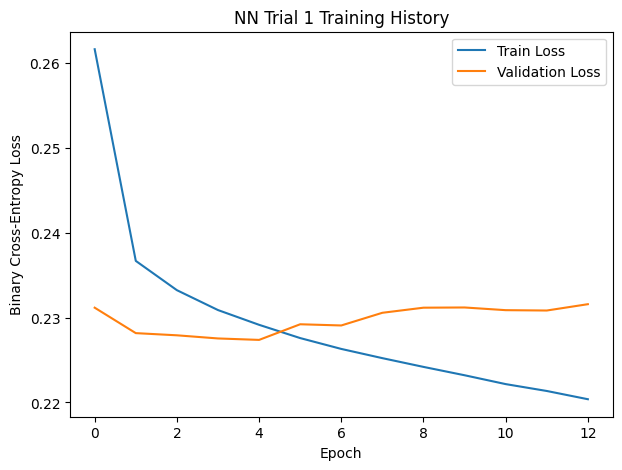

In [74]:
plot_history(
    history1,
    "NN Trial 1 Training History"
)

In [75]:
val_prob_1 = (
    model1
    .predict(
        X_val,
        verbose=0
    )
    .ravel()
)

threshold_1 = (
    best_f1_threshold(
        y_val,
        val_prob_1
    )
)

results_1 = (
    evaluate_model(
        y_val,
        val_prob_1,
        threshold_1
    )
)

print(
    "Trial 1 threshold:",
    threshold_1
)

print(
    results_1
)

Trial 1 threshold: 0.42671194672584534
{'ROC-AUC': 0.9302574415696587, 'PR-AUC': 0.7011203615250513, 'F1': 0.6960352422907489, 'Precision': 0.7181818181818181, 'Recall': 0.6752136752136753, 'Threshold': 0.42671194672584534}


### Trial 1 result

The preceding computed metrics establish the baseline. They are recomputed from the corrected P2 inputs; no old fixed percentages are reused.

### Trial 2 Training

The second architecture adds more hidden capacity and 20% dropout. The same training, validation, and threshold-selection procedure is used so the comparison remains fair.


In [76]:
model2, history2 = train_nn(
    build_nn_trial_2,

    X_train,
    y_train,

    X_val,
    y_val,

    verbose=1
)

Epoch 1/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.2707 - val_loss: 0.2334
Epoch 2/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2409 - val_loss: 0.2271
Epoch 3/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2367 - val_loss: 0.2262
Epoch 4/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2339 - val_loss: 0.2237
Epoch 5/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2328 - val_loss: 0.2252
Epoch 6/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2310 - val_loss: 0.2296
Epoch 7/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2298 - val_loss: 0.2215
Epoch 8/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2273 - val_loss: 0.2237
Epoch 9/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2270 - val_loss: 0.2257
Epoch 10/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2262 - val_loss: 0.2213
Epoch 11/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2249 - val_loss: 0.2235
Epoch 12/150
767/767 ━━━━━━━━━━━━━━━━━━━━

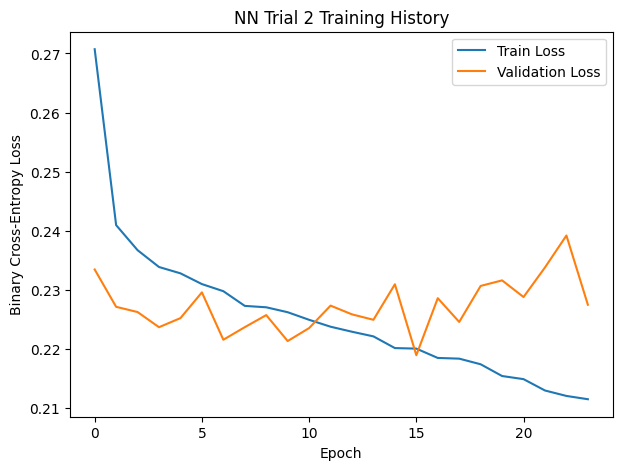

In [77]:
plot_history(
    history2,
    "NN Trial 2 Training History"
)

In [78]:
val_prob_2 = (
    model2
    .predict(
        X_val,
        verbose=0
    )
    .ravel()
)

threshold_2 = (
    best_f1_threshold(
        y_val,
        val_prob_2
    )
)

results_2 = (
    evaluate_model(
        y_val,
        val_prob_2,
        threshold_2
    )
)

print(
    "Trial 2 threshold:",
    threshold_2
)

print(
    results_2
)

Trial 2 threshold: 0.20224826037883759
{'ROC-AUC': 0.9396552835466863, 'PR-AUC': 0.7618965042310542, 'F1': 0.7237354085603113, 'Precision': 0.6642857142857143, 'Recall': 0.7948717948717948, 'Threshold': 0.20224826037883759}


### Trial 2 result

The preceding computed validation metrics compare the larger dropout architecture with Trial 1. AP and F1 are evaluated from this run.

### Model Comparison and Selection

The two networks are compared on the **same validation data**.  
The selected architecture is the one with the stronger validation PR-AUC, with F1 used as a secondary check.

No test-set result is used in this decision.


In [79]:
nn_comparison = pd.DataFrame([
    {
        "Model":
            "NN Trial 1 (32-16)",

        **results_1
    },

    {
        "Model":
            "NN Trial 2 (64-32 + Dropout)",

        **results_2
    }
])

nn_comparison = (
    nn_comparison
    .sort_values(
        by=[
            "PR-AUC",
            "F1"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    nn_comparison
)

,Model,ROC-AUC,PR-AUC,F1,Precision,Recall,Threshold
0,NN Trial 2 (64-32 + Dropout),0.939655,0.761897,0.723735,0.664286,0.794872,0.202248
1,NN Trial 1 (32-16),0.930257,0.701120,0.696035,0.718182,0.675214,0.426712


### Neural network selection

The comparison above determines the selected trial using validation AP, with F1 as the stated tie-breaker. Its threshold was selected on validation only. The next cell applies that decision; test outcomes are not consulted.

In [80]:
winner = (
    nn_comparison
    .iloc[0]["Model"]
)

if winner.startswith(
    "NN Trial 1"
):

    best_model = model1

    best_threshold = (
        threshold_1
    )

    best_label = (
        "NN Trial 1"
    )

else:

    best_model = model2

    best_threshold = (
        threshold_2
    )

    best_label = (
        "NN Trial 2"
    )


print(
    "Selected model:",
    best_label
)

print(
    "Selected threshold:",
    round(
        best_threshold,
        4
    )
)

Selected model: NN Trial 2
Selected threshold: 0.2022


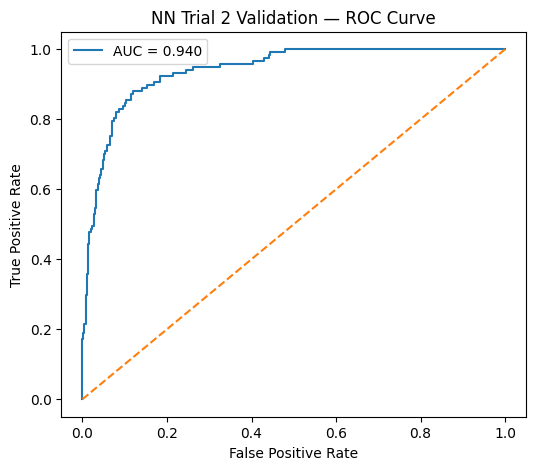

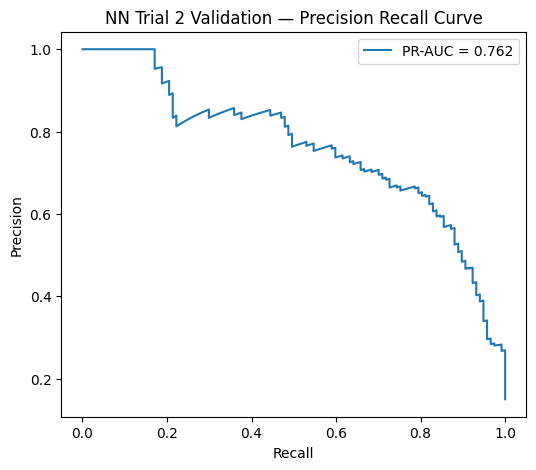

In [81]:
best_val_prob = (
    best_model
    .predict(
        X_val,
        verbose=0
    )
    .ravel()
)

plot_roc_pr(
    y_val,
    best_val_prob,
    f"{best_label} Validation"
)

## 4.7 Final unseen test evaluation

After selecting the architecture and freezing its validation-derived threshold, evaluate it on training, validation and the unseen 2022–2024 period. Later ablation and order experiments are prespecified training/validation diagnostics and do not alter this frozen selection.

In [82]:
split_results = []

for (
    split_name,
    X_split,
    y_split
) in [

    (
        "Train",
        X_train,
        y_train
    ),

    (
        "Validation",
        X_val,
        y_val
    ),

    (
        "Test",
        X_test,
        y_test
    )
]:

    probabilities = (
        best_model
        .predict(
            X_split,
            verbose=0
        )
        .ravel()
    )

    metrics = (
        evaluate_model(
            y_split,
            probabilities,
            best_threshold
        )
    )

    split_results.append({
        "Split":
            split_name,

        **metrics
    })


final_nn_results = (
    pd.DataFrame(
        split_results
    )
)

display(
    final_nn_results
)

,Split,ROC-AUC,PR-AUC,F1,Precision,Recall,Threshold
0,Train,0.928267,0.645960,0.608555,0.490873,0.800458,0.202248
1,Validation,0.939655,0.761897,0.723735,0.664286,0.794872,0.202248
2,Test,0.934169,0.688229,0.649007,0.590361,0.720588,0.202248


### Final performance summary

The preceding table reports this run’s ROC-AUC, AP, F1, precision and recall at the frozen threshold. Compare the three periods directly; their different eras, qualifying coverage and class prevalence can affect scores.

### Temporal generalization

A larger validation AP than training AP alone does not establish leakage because periods differ. The train-only preprocessing and prior-race feature construction are the leakage controls. Test performance is descriptive final evaluation and must not drive subsequent tuning.

In [83]:
split_results = []

for (
    split_name,
    X_split,
    y_split
) in [

    (
        "Train",
        X_train,
        y_train
    ),

    (
        "Validation",
        X_val,
        y_val
    ),

    (
        "Test",
        X_test,
        y_test
    )
]:

    probabilities = (
        best_model
        .predict(
            X_split,
            verbose=0
        )
        .ravel()
    )

    metrics = (
        evaluate_model(
            y_split,
            probabilities,
            best_threshold
        )
    )

    split_results.append({
        "Split":
            split_name,

        **metrics
    })


final_nn_results = (
    pd.DataFrame(
        split_results
    )
)

display(
    final_nn_results
)

,Split,ROC-AUC,PR-AUC,F1,Precision,Recall,Threshold
0,Train,0.928267,0.645960,0.608555,0.490873,0.800458,0.202248
1,Validation,0.939655,0.761897,0.723735,0.664286,0.794872,0.202248
2,Test,0.934169,0.688229,0.649007,0.590361,0.720588,0.202248


In [84]:
test_prob = (
    best_model
    .predict(
        X_test,
        verbose=0
    )
    .ravel()
)

test_pred = (
    test_prob
    >= best_threshold
).astype(int)


print(
    classification_report(
        y_test,
        test_pred,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9486    0.9117    0.9298      1155
           1     0.5904    0.7206    0.6490       204

    accuracy                         0.8830      1359
   macro avg     0.7695    0.8161    0.7894      1359
weighted avg     0.8949    0.8830    0.8877      1359



In [85]:
cm = confusion_matrix(
    y_test,
    test_pred
)

cm_df = pd.DataFrame(
    cm,

    index=[
        "Actual Non-Podium",
        "Actual Podium"
    ],

    columns=[
        "Predicted Non-Podium",
        "Predicted Podium"
    ]
)

display(
    cm_df
)

,Predicted Non-Podium,Predicted Podium
Actual Non-Podium,1053,102
Actual Podium,57,147


### Test classification behavior

The printed classification report and confusion matrix give the actual precision, recall, false positives and missed podiums at the frozen validation threshold. The interpretation at the end is generated from these current results.

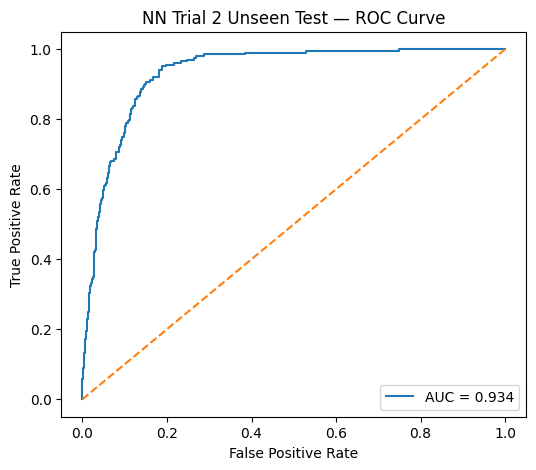

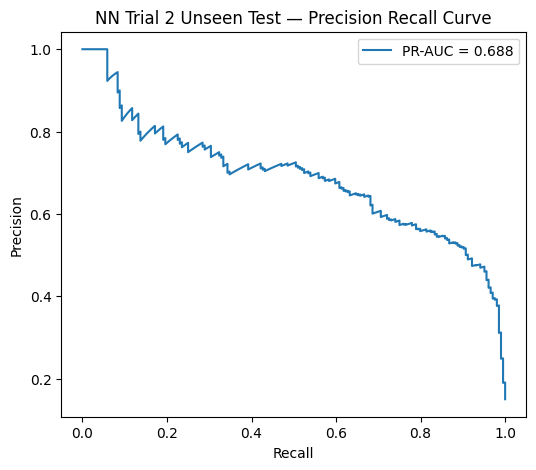

In [86]:
plot_roc_pr(
    y_test,
    test_prob,
    f"{best_label} Unseen Test"
)

## 4.8 Feature-Group Ablation

Ablation measures how much each **group of raw features** contributes to validation performance.

The full model is retrained repeatedly, each time removing one feature group:

| Group | Removed variables |
|---|---|
| Grid | starting grid position |
| Qualifying | qualifying position |
| Driver form | driver historical performance features |
| Constructor form | constructor historical performance features |
| Standings | driver and constructor championship standings |
| Context | year, circuit, home-race indicator |

A drop in PR-AUC after removing a group suggests that the group contributes useful predictive information.


In [87]:
feature_groups = {

    "grid": [
        "grid_position"
    ],

    "qualifying": [
        "qualifying_position"
    ],

    "driver_form": [
        "driver_prior_starts",
        "driver_prior_podium_rate",
        "driver_prior_mean_finish",
        "driver_circuit_prior_starts",
        "driver_circuit_prior_podium_rate"
    ],

    "constructor_form": [
        "constructor_prior_podium_rate",
        "constructor_prior_mean_points"
    ],

    "standings": [
        "driver_prior_standing_points",
        "driver_prior_standing_position",
        "constructor_prior_standing_points",
        "constructor_prior_standing_position"
    ],

    "context": [
        "year",
        "circuitId",
        "is_home_race"
    ]
}


for group_name, cols in (
    feature_groups.items()
):

    print(
        group_name,
        "->",
        cols
    )

grid -> ['grid_position']
qualifying -> ['qualifying_position']
driver_form -> ['driver_prior_starts', 'driver_prior_podium_rate', 'driver_prior_mean_finish', 'driver_circuit_prior_starts', 'driver_circuit_prior_podium_rate']
constructor_form -> ['constructor_prior_podium_rate', 'constructor_prior_mean_points']
standings -> ['driver_prior_standing_points', 'driver_prior_standing_position', 'constructor_prior_standing_points', 'constructor_prior_standing_position']
context -> ['year', 'circuitId', 'is_home_race']


In [88]:
selected_builder = (
    build_nn_trial_1
    if best_label == "NN Trial 1"
    else build_nn_trial_2
)


def run_ablation(
    raw_train,
    y_train,
    raw_val,
    y_val,
    base_features,
    feature_groups
):

    rows = []


    def fit_and_score(
        selected_features,
        experiment_name
    ):

        train_part = (
            raw_train[
                selected_features
            ].copy()
        )

        val_part = (
            raw_val[
                selected_features
            ].copy()
        )


        if "circuitId" in train_part.columns:

            train_part[
                "circuitId"
            ] = (
                train_part[
                    "circuitId"
                ].astype("string")
            )

            val_part[
                "circuitId"
            ] = (
                val_part[
                    "circuitId"
                ].astype("string")
            )


        prep, _, _ = (
            build_preprocessor(
                train_part
            )
        )


        Xt = np.asarray(
            prep.fit_transform(
                train_part
            ),
            dtype=np.float32
        )


        Xv = np.asarray(
            prep.transform(
                val_part
            ),
            dtype=np.float32
        )


        model, _ = train_nn(
            selected_builder,
            Xt,
            y_train,
            Xv,
            y_val,
            verbose=0
        )


        prob = (
            model
            .predict(
                Xv,
                verbose=0
            )
            .ravel()
        )


        threshold = (
            best_f1_threshold(
                y_val,
                prob
            )
        )


        metrics = (
            evaluate_model(
                y_val,
                prob,
                threshold
            )
        )


        rows.append({
            "Experiment":
                experiment_name,

            "Raw Feature Count":
                len(
                    selected_features
                ),

            **metrics
        })


        return metrics


    full_metrics = fit_and_score(
        base_features,
        "Full Feature Set"
    )


    for (
        group_name,
        group_columns
    ) in feature_groups.items():

        remaining = [
            feature
            for feature in base_features
            if feature
            not in group_columns
        ]


        fit_and_score(
            remaining,
            f"Without {group_name}"
        )


    results = pd.DataFrame(
        rows
    )


    results[
        "Δ PR-AUC vs Full"
    ] = (
        results["PR-AUC"]
        -
        full_metrics["PR-AUC"]
    )


    results[
        "Δ ROC-AUC vs Full"
    ] = (
        results["ROC-AUC"]
        -
        full_metrics["ROC-AUC"]
    )


    results[
        "Δ F1 vs Full"
    ] = (
        results["F1"]
        -
        full_metrics["F1"]
    )


    return results

In [89]:
ablation_results = (
    run_ablation(
        X_train_raw,
        y_train,

        X_val_raw,
        y_val,

        feature_cols,
        feature_groups
    )
)

display(
    ablation_results
)

,Experiment,Raw Feature Count,ROC-AUC,PR-AUC,F1,Precision,Recall,Threshold,Δ PR-AUC vs Full,Δ ROC-AUC vs Full,Δ F1 vs Full
0,Full Feature Set,16,0.939655,0.761897,0.723735,0.664286,0.794872,0.202248,0.000000,0.000000,0.000000
1,Without grid,15,0.931418,0.729568,0.695279,0.698276,0.692308,0.358147,-0.032328,-0.008238,-0.028456
2,Without qualifying,15,0.932024,0.742725,0.690265,0.715596,0.666667,0.410780,-0.019172,-0.007632,-0.033470
3,Without driver_form,11,0.933171,0.738814,0.703863,0.706897,0.700855,0.326128,-0.023082,-0.006484,-0.019873
4,Without constructor_form,14,0.932836,0.731562,0.693878,0.664062,0.726496,0.284154,-0.030335,-0.006820,-0.029858
5,Without standings,12,0.931237,0.741368,0.702703,0.742857,0.666667,0.492469,-0.020529,-0.008418,-0.021033
6,Without context,13,0.933248,0.733086,0.716814,0.743119,0.692308,0.448371,-0.028810,-0.006407,-0.006921


In [90]:
display(
    ablation_results
    .sort_values(
        "PR-AUC",
        ascending=False
    )
)

,Experiment,Raw Feature Count,ROC-AUC,PR-AUC,F1,Precision,Recall,Threshold,Δ PR-AUC vs Full,Δ ROC-AUC vs Full,Δ F1 vs Full
0,Full Feature Set,16,0.939655,0.761897,0.723735,0.664286,0.794872,0.202248,0.000000,0.000000,0.000000
2,Without qualifying,15,0.932024,0.742725,0.690265,0.715596,0.666667,0.410780,-0.019172,-0.007632,-0.033470
5,Without standings,12,0.931237,0.741368,0.702703,0.742857,0.666667,0.492469,-0.020529,-0.008418,-0.021033
3,Without driver_form,11,0.933171,0.738814,0.703863,0.706897,0.700855,0.326128,-0.023082,-0.006484,-0.019873
6,Without context,13,0.933248,0.733086,0.716814,0.743119,0.692308,0.448371,-0.028810,-0.006407,-0.006921
4,Without constructor_form,14,0.932836,0.731562,0.693878,0.664062,0.726496,0.284154,-0.030335,-0.006820,-0.029858
1,Without grid,15,0.931418,0.729568,0.695279,0.698276,0.692308,0.358147,-0.032328,-0.008238,-0.028456


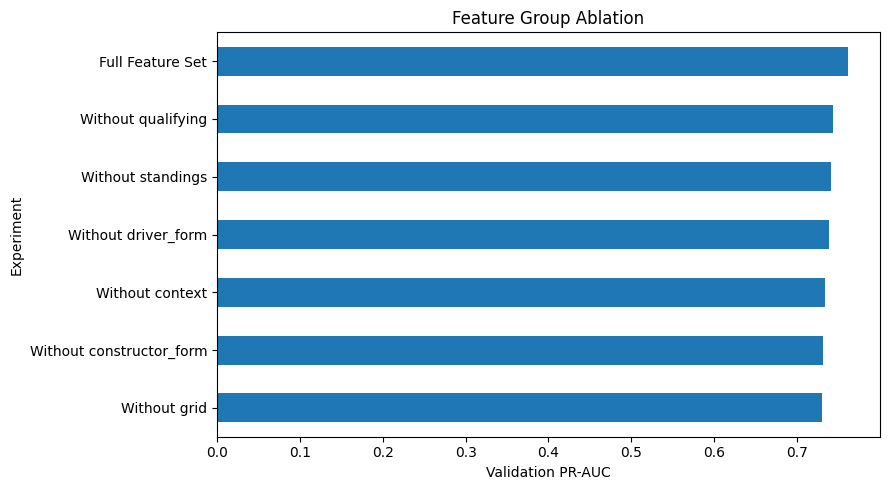

In [91]:
ablation_plot = (
    ablation_results
    .set_index(
        "Experiment"
    )["PR-AUC"]
    .sort_values()
)

plt.figure(
    figsize=(9, 5)
)

ablation_plot.plot(
    kind="barh"
)

plt.xlabel(
    "Validation PR-AUC"
)

plt.title(
    "Feature Group Ablation"
)

plt.tight_layout()

plt.show()

### Ablation findings

The table and plot above report actual validation changes from removing each complete feature group. Negative AP changes indicate a harmful removal; positive changes can reflect redundancy, fitting noise or era composition. They do not show that a feature is universally useful or useless.

### Ablation limitations

Each condition is retrained using the same selected architecture, seed and early-stopping rule. Different input dimensions change optimization and initialization effects, so one-seed differences have no uncertainty estimate and should not be overinterpreted. No feature set is changed using test performance.

## 4.8b Required preprocessing-order experiments

The brief requires at least two preprocessing-order experiments. These were absent from Zeina’s branch. Both comparisons hold raw features, temporal rows, selected NN architecture, seed and early-stopping rule constant and use training/validation only.

1. **Median imputation → scaling versus scaling → median imputation.** In the reversed order, the scaler estimates moments from observed training values, and indicators added afterward stay binary; in the original order, medians and indicators participate in standardization.
2. **Median imputation → quantile transform → scaling versus quantile transform → median imputation → scaling.** Median-imputed mass changes the training empirical quantiles when imputation comes first. Quantile transforms map each numerical distribution toward normal scores. This measures order effects rather than claiming that quantile transformation is necessarily better than the original pipeline.

Circuit imputation/one-hot is unchanged. Quantile/scaler/imputer parameters are fitted on training only; transformed dimensions and distribution summaries are saved. These are fixed diagnostics, not additional test-based model selection. One seeded run per condition does not estimate training uncertainty.


,Order,transformed_columns,epochs,ROC-AUC,PR-AUC,F1,Precision,Recall,Threshold
0,impute_then_scale,96,24,0.939655,0.761897,0.723735,0.664286,0.794872,0.202248
1,scale_then_impute,96,18,0.935594,0.749014,0.702041,0.671875,0.735043,0.256469
2,impute_then_quantile_then_scale,96,9,0.921556,0.690275,0.692641,0.701754,0.683761,0.291992
3,quantile_then_impute_then_scale,96,9,0.923979,0.699336,0.700000,0.682927,0.717949,0.248182


,columns,average_std,lowest_value,highest_value
Order,,,,
impute_then_quantile_then_scale,96,0.335267,-5.220234,30.124434
impute_then_scale,96,0.335267,-3.432778,30.124434
quantile_then_impute_then_scale,96,0.335267,-6.194656,30.124434
scale_then_impute,96,0.249946,-3.356871,11.137815


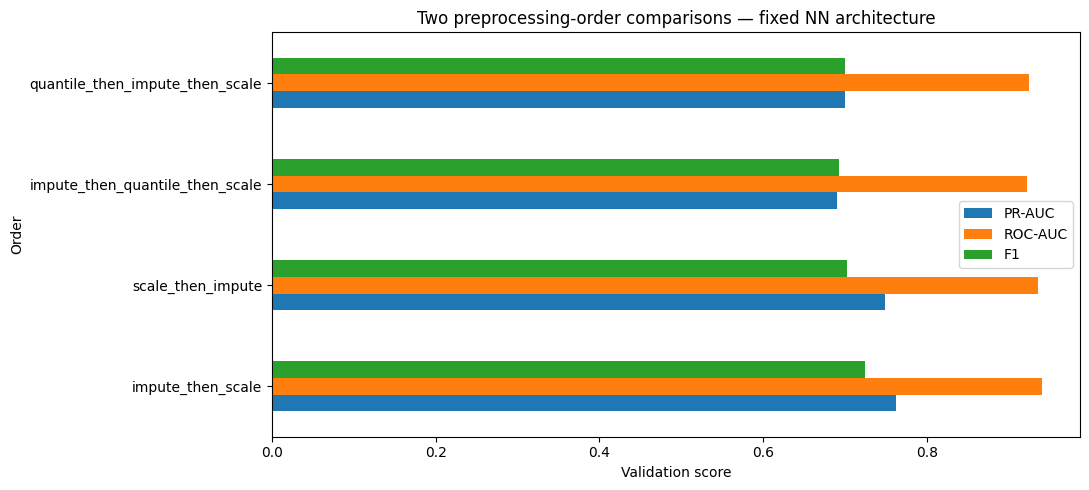

In [92]:
from sklearn.preprocessing import QuantileTransformer

order_pipelines = {
    "impute_then_scale": Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler())]),
    "scale_then_impute": Pipeline([
        ("scaler", StandardScaler()),
        ("imputer", SimpleImputer(strategy="median", add_indicator=True))]),
    "impute_then_quantile_then_scale": Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("quantile", QuantileTransformer(n_quantiles=100, output_distribution="normal", random_state=SEED)),
        ("scaler", StandardScaler())]),
    "quantile_then_impute_then_scale": Pipeline([
        ("quantile", QuantileTransformer(n_quantiles=100, output_distribution="normal", random_state=SEED)),
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler())]),
}
order_rows = []
order_distribution_rows = []
order_preprocessors = {}
for name, numeric_pipeline in order_pipelines.items():
    experiment_prep = ColumnTransformer([
        ("num", numeric_pipeline, numeric_cols),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), categorical_cols)])
    train_matrix = np.asarray(experiment_prep.fit_transform(X_train_raw), dtype=np.float32)
    validation_matrix = np.asarray(experiment_prep.transform(X_val_raw), dtype=np.float32)
    order_preprocessors[name] = experiment_prep
    assert np.isfinite(train_matrix).all() and np.isfinite(validation_matrix).all()
    if name == "impute_then_scale":
        np.testing.assert_allclose(train_matrix, X_train, atol=1e-6)
        experiment_probability = best_val_prob
        trained_epochs = len(history1.history["loss"]) if best_label == "NN Trial 1" else len(history2.history["loss"])
    else:
        experiment_model, experiment_history = train_nn(selected_builder, train_matrix, y_train,
            validation_matrix, y_val, verbose=0)
        experiment_probability = experiment_model.predict(validation_matrix, verbose=0).ravel()
        trained_epochs = len(experiment_history.history["loss"])
    experiment_threshold = best_f1_threshold(y_val, experiment_probability)
    order_rows.append({"Order": name, "transformed_columns": train_matrix.shape[1],
        "epochs": trained_epochs, **evaluate_model(y_val, experiment_probability, experiment_threshold)})
    for j, feature_name in enumerate(experiment_prep.get_feature_names_out()):
        values = train_matrix[:, j]
        order_distribution_rows.append({"Order": name, "feature": feature_name,
            "mean": float(values.mean()), "std": float(values.std()),
            "min": float(values.min()), "max": float(values.max()),
            "missing_fraction": float(np.isnan(values).mean())})
order_results = pd.DataFrame(order_rows)
order_distribution = pd.DataFrame(order_distribution_rows)
display(order_results)
display(order_distribution.groupby("Order").agg(columns=("feature", "size"),
    average_std=("std", "mean"), lowest_value=("min", "min"), highest_value=("max", "max")))
order_results.set_index("Order")[["PR-AUC", "ROC-AUC", "F1"]].plot(kind="barh", figsize=(11, 5))
plt.xlabel("Validation score")
plt.title("Two preprocessing-order comparisons — fixed NN architecture")
plt.tight_layout()
plt.show()


## 4.9 Permutation Importance

Permutation importance measures model reliance one transformed feature at a time.

### Method

1. Compute baseline validation PR-AUC.
2. Shuffle one feature column.
3. Recompute PR-AUC.
4. Measure the drop.
5. Repeat several times and average the decrease.

A larger PR-AUC drop means the model depended more strongly on that feature.

Because preprocessing creates one-hot columns and missingness indicators, permutation importance is reported at the **transformed-feature level**.


In [93]:
def permutation_importance_pr_auc(
    model,
    X,
    y,
    feature_names,
    repeats=3
):

    rng = np.random.default_rng(
        SEED
    )

    baseline_probability = (
        model
        .predict(
            X,
            verbose=0
        )
        .ravel()
    )

    baseline_score = (
        average_precision_score(
            y,
            baseline_probability
        )
    )

    rows = []


    for column_index, feature_name in (
        enumerate(feature_names)
    ):

        score_drops = []


        for _ in range(repeats):

            X_permuted = (
                X.copy()
            )

            rng.shuffle(
                X_permuted[
                    :,
                    column_index
                ]
            )

            perm_probability = (
                model
                .predict(
                    X_permuted,
                    verbose=0
                )
                .ravel()
            )

            perm_score = (
                average_precision_score(
                    y,
                    perm_probability
                )
            )

            score_drops.append(
                baseline_score
                -
                perm_score
            )


        rows.append({
            "Feature":
                feature_name,

            "Importance_PR_AUC_Drop":
                float(
                    np.mean(
                        score_drops
                    )
                ),

            "Std":
                float(
                    np.std(
                        score_drops
                    )
                )
        })


    return (
        pd.DataFrame(
            rows
        )
        .sort_values(
            "Importance_PR_AUC_Drop",
            ascending=False
        )
        .reset_index(drop=True)
    )

In [94]:
permutation_df = (
    permutation_importance_pr_auc(
        best_model,

        X_val,
        y_val,

        transformed_feature_names,

        repeats=3
    )
)

display(
    permutation_df.head(20)
)

,Feature,Importance_PR_AUC_Drop,Std
0,num__grid_position,0.157271,0.037625
1,num__driver_prior_podium_rate,0.091591,0.016847
2,num__driver_prior_standing_points,0.079096,0.004373
3,num__qualifying_position,0.078964,0.018030
4,num__driver_circuit_prior_starts,0.031353,0.003758
5,num__constructor_prior_mean_points,0.026831,0.005419
6,num__constructor_prior_standing_points,0.023141,0.010112
7,num__constructor_prior_podium_rate,0.022842,0.010853
8,num__constructor_prior_standing_position,0.020247,0.002920
9,num__missingindicator_driver_prior_standing_po...,0.016845,0.010972


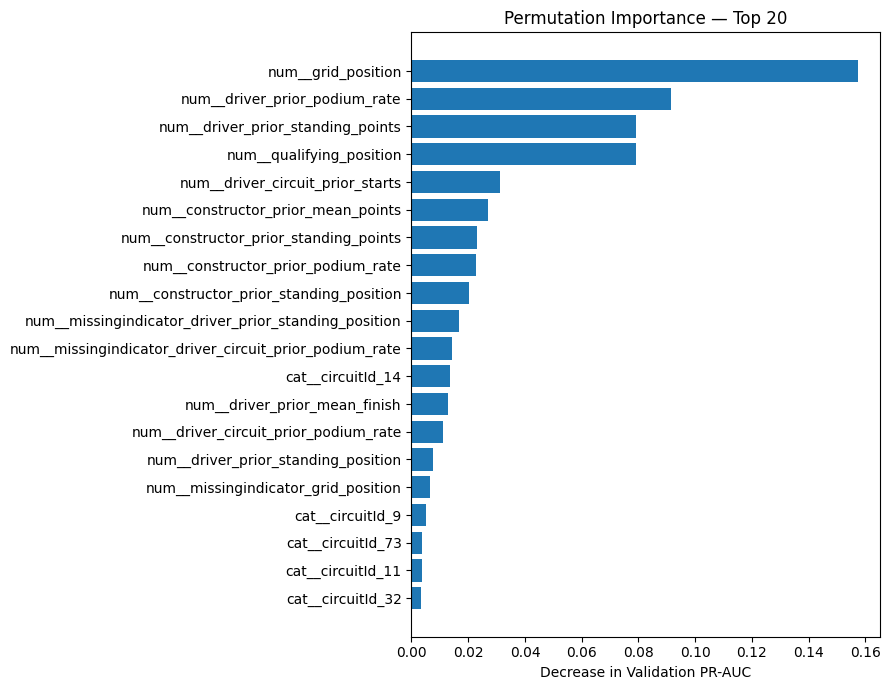

In [95]:
top_permutation = (
    permutation_df
    .head(20)
    .sort_values(
        "Importance_PR_AUC_Drop"
    )
)

plt.figure(
    figsize=(9, 7)
)

plt.barh(
    top_permutation["Feature"],
    top_permutation[
        "Importance_PR_AUC_Drop"
    ]
)

plt.xlabel(
    "Decrease in Validation PR-AUC"
)

plt.title(
    "Permutation Importance — Top 20"
)

plt.tight_layout()

plt.show()

### Permutation-importance findings

The table above reports the current mean validation AP drops and their variation over three shuffles. Positive drops suggest reliance; near-zero or negative values can reflect redundancy or sampling noise. These are model properties, not causal effects.

### Permutation-importance interpretation

This retains Zeina’s transformed-column method. Shuffling individual one-hot columns or missingness indicators can create combinations not seen in real data, and correlated predictors can mask each other’s importance. Interpret circuit dummy rankings accordingly; raw group ablation is the complementary check.

## 4.10 SHAP Explainability

SHAP is used in two ways:

### Global explanation
A SHAP summary plot shows which transformed features have the largest overall impact across a sample of validation observations.

### Local explanation
A SHAP waterfall plot explains one specific prediction by showing which features push its probability upward or downward.

To keep runtime practical, SHAP uses:

- 30 training observations as the background sample;
- 25 validation observations for explanation.

The explanation sample is used only for interpretation, not model tuning.


In [96]:
print(
    "SHAP available:",
    SHAP_AVAILABLE
)

SHAP available: True


In [97]:
if SHAP_AVAILABLE:

    rng = np.random.default_rng(
        SEED
    )

    background_size = min(
        30,
        len(X_train)
    )

    explanation_size = min(
        25,
        len(X_val)
    )


    background_indices = (
        rng.choice(
            len(X_train),
            size=background_size,
            replace=False
        )
    )


    explanation_indices = (
        rng.choice(
            len(X_val),
            size=explanation_size,
            replace=False
        )
    )


    X_background = (
        X_train[
            background_indices
        ]
    )


    X_explain = (
        X_val[
            explanation_indices
        ]
    )


    print(
        "Background shape:",
        X_background.shape
    )

    print(
        "Explanation shape:",
        X_explain.shape
    )

Background shape: (30, 96)
Explanation shape: (25, 96)


In [98]:
if SHAP_AVAILABLE:

    def shap_predict(
        x
    ):

        x = np.asarray(
            x,
            dtype=np.float32
        )

        return (
            best_model
            .predict(
                x,
                verbose=0
            )
            .ravel()
        )


    shap_explainer = (
        shap.KernelExplainer(
            shap_predict,
            X_background
        )
    )

In [99]:
if SHAP_AVAILABLE:

    shap_values = (
        shap_explainer
        .shap_values(
            X_explain,
            nsamples=100
        )
    )


    if isinstance(
        shap_values,
        list
    ):

        shap_values = (
            shap_values[0]
        )


    shap_values = np.asarray(
        shap_values
    )


    print(
        "SHAP values shape:",
        shap_values.shape
    )

100%|##########| 25/25 [00:04<00:00,  5.47it/s]
SHAP values shape: (25, 96)


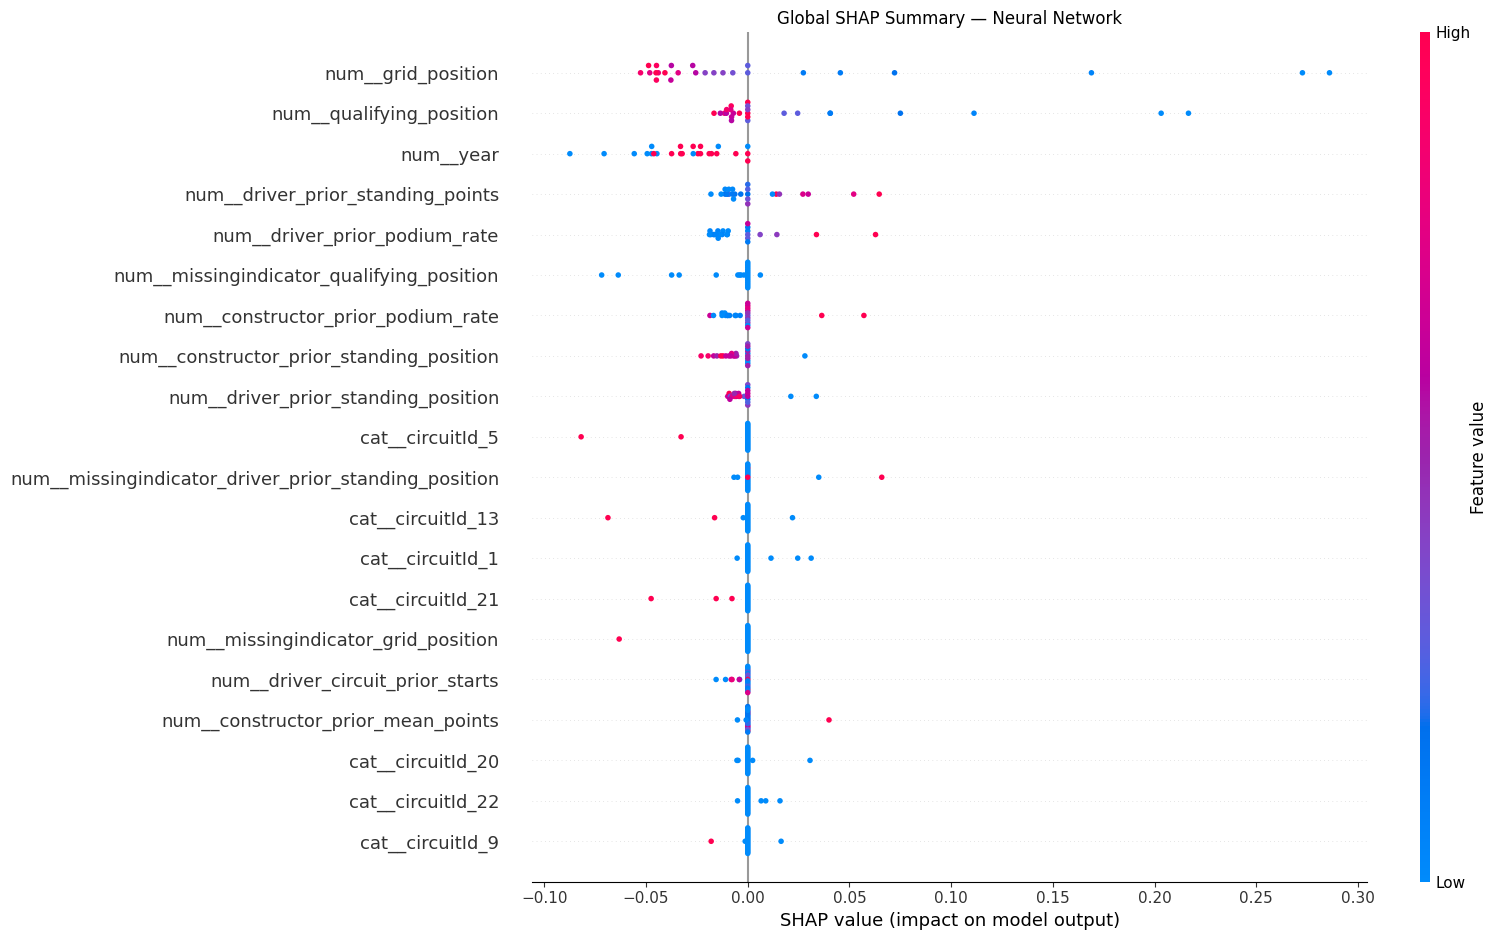

<ipython-input-100-908c1dffcafe>:12: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


In [100]:
if SHAP_AVAILABLE:

    X_explain_df = (
        pd.DataFrame(
            X_explain,
            columns=
                transformed_feature_names
        )
    )


    shap.summary_plot(
        shap_values,

        X_explain_df,

        max_display=20,

        show=False
    )


    plt.title(
        "Global SHAP Summary — Neural Network"
    )

    plt.tight_layout()

    plt.show()

### Global SHAP findings

The summary plot above is computed for the selected model and sampled validation rows. The final interpretation ranks actual mean absolute attributions from this run, rather than reusing old feature rankings.

### Global SHAP interpretation

Kernel SHAP here approximates changes in predicted probability relative to a sampled training background. The small sample and finite coalition budget limit stability, especially for correlated historical features and one-hot constraints. Transformed values are standardized/encoded values, not original units. These explanations describe model reliance, not causality.

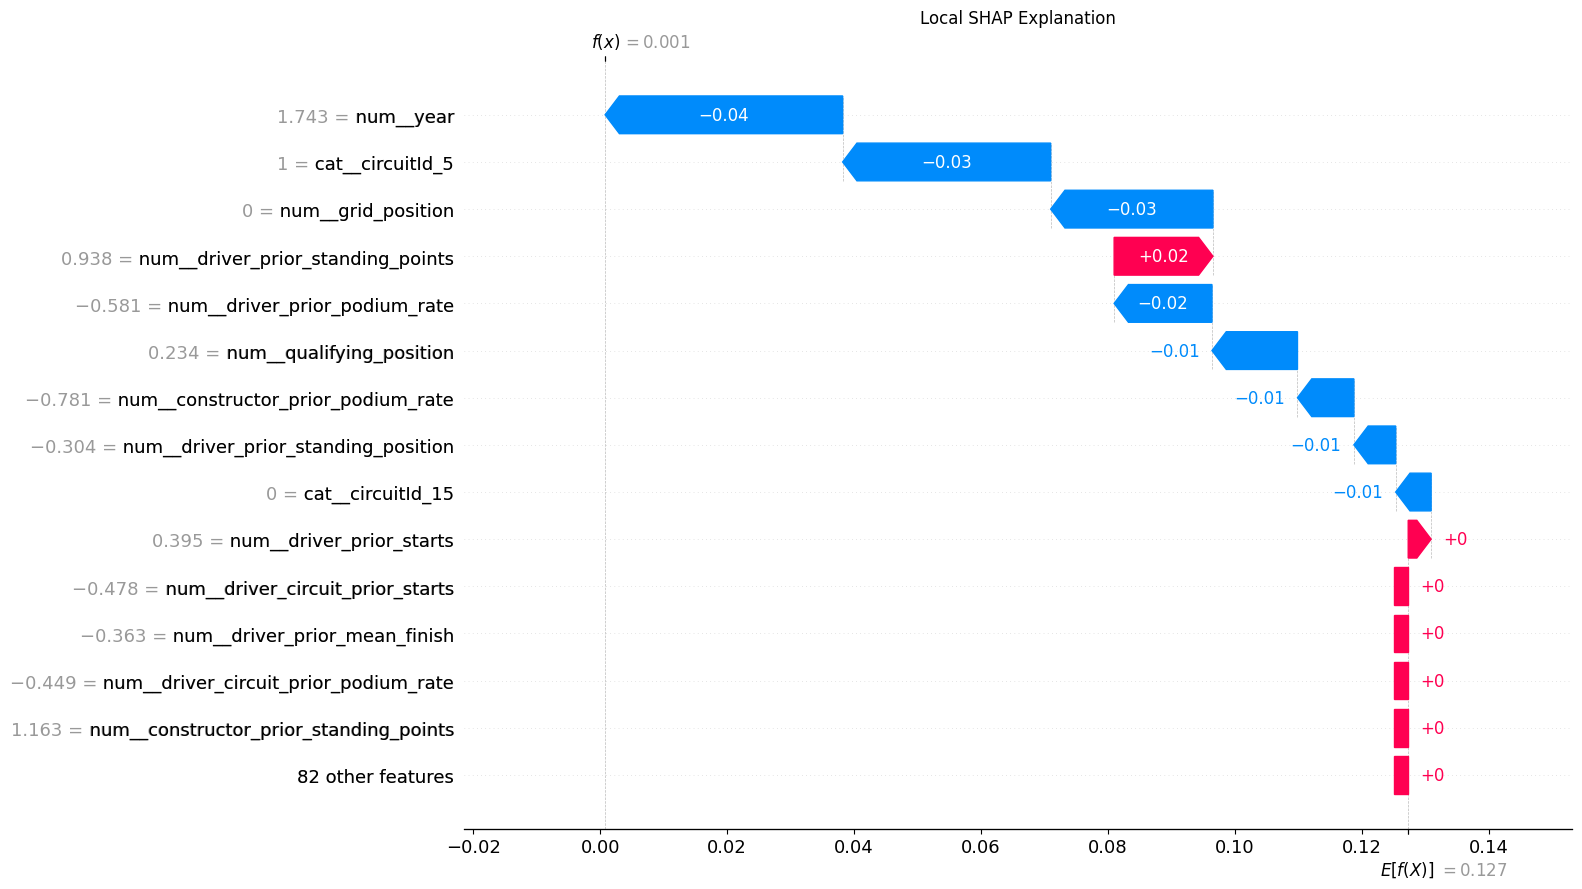

Predicted podium probability: 0.0008


In [101]:
if SHAP_AVAILABLE:

    local_index = 0

    local_values = (
        shap_values[
            local_index
        ]
    )

    local_input = (
        X_explain[
            local_index
        ]
    )


    expected_value = (
        np.asarray(
            shap_explainer
            .expected_value
        )
        .reshape(-1)[0]
    )


    local_explanation = (
        shap.Explanation(
            values=
                local_values,

            base_values=
                expected_value,

            data=
                local_input,

            feature_names=
                transformed_feature_names
        )
    )


    local_probability = float(
        best_model
        .predict(
            local_input
            .reshape(1, -1),

            verbose=0
        )
        .ravel()[0]
    )


    print(
        "Predicted podium probability:",
        round(
            local_probability,
            4
        )
    )


    shap.plots.waterfall(
        local_explanation,

        max_display=15,

        show=False
    )


    plt.title(
        "Local SHAP Explanation"
    )

    plt.tight_layout()

    plt.show()

### Local SHAP findings

The waterfall explains the first randomly sampled validation record. Its prediction, baseline and largest signed contributions are calculated from this run and identified by race/driver in the final interpretation.

### Local SHAP interpretation

Positive contributions increase this probability relative to the background expectation; negative ones decrease it. The final checks verify baseline plus contributions reconstructs the explained probability within numerical tolerance. One local explanation cannot be generalized to every race.

## 4.11 Inference Function

The final inference function accepts a raw pre-race record, applies the **same fitted preprocessing pipeline**, and returns:

- podium probability;
- binary prediction;
- selected classification threshold.

The function also adds absent feature columns as missing values, allowing the trained imputers to handle partially incomplete input.


In [102]:
def predict_podium(
    record
):

    if isinstance(
        record,
        dict
    ):

        row = pd.DataFrame(
            [record]
        )

    elif isinstance(
        record,
        pd.Series
    ):

        row = (
            record
            .to_frame()
            .T
        )

    elif isinstance(
        record,
        pd.DataFrame
    ):

        row = (
            record.copy()
        )

    else:

        raise TypeError(
            "record must be dict, Series or DataFrame"
        )


    if len(row) != 1:
        raise ValueError("predict_podium expects exactly one driver–race record")

    for feature in feature_cols:

        if feature not in row.columns:

            row[
                feature
            ] = np.nan


    row = row[
        feature_cols
    ].copy()


    # Normalize categories exactly as during fit; represent missing categories as np.nan.
    def normalize_circuit_id(value):
        if pd.isna(value):
            return np.nan
        try:
            number = float(value)
            return str(int(number)) if np.isfinite(number) and number.is_integer() else str(value)
        except (TypeError, ValueError):
            return str(value)
    row["circuitId"] = row["circuitId"].map(normalize_circuit_id)
    for column in numeric_cols:
        row[column] = pd.to_numeric(row[column], errors="coerce")

    X_new = np.asarray(
        preprocessor
        .transform(
            row
        ),

        dtype=np.float32
    )


    probability = float(
        best_model
        .predict(
            X_new,
            verbose=0
        )
        .ravel()[0]
    )


    prediction = int(
        probability
        >= best_threshold
    )


    return {
        "podium_probability":
            probability,

        "podium_prediction":
            prediction,

        "threshold":
            float(
                best_threshold
            )
    }

In [103]:
complete_record = (
    X_test_raw
    .dropna()
    .iloc[0]
    .copy()
)

complete_prediction = (
    predict_podium(
        complete_record
    )
)

print(
    "Complete Record"
)

print(
    complete_prediction
)

Complete Record
{'podium_probability': 0.04016012325882912, 'podium_prediction': 0, 'threshold': 0.20224826037883759}


In [104]:
partially_missing_record = (
    complete_record.copy()
)

missing_demo_features = [
    "qualifying_position",
    "driver_prior_podium_rate",
    "constructor_prior_standing_position"
]

for feature in (
    missing_demo_features
):

    partially_missing_record[
        feature
    ] = np.nan


missing_prediction = (
    predict_podium(
        partially_missing_record
    )
)


print(
    "Partially Missing Record"
)

print(
    "Missing:",
    missing_demo_features
)

print(
    missing_prediction
)

Partially Missing Record
Missing: ['qualifying_position', 'driver_prior_podium_rate', 'constructor_prior_standing_position']
{'podium_probability': 0.015244712121784687, 'podium_prediction': 0, 'threshold': 0.20224826037883759}


### Inference demonstration

The complete example is selected from rows with all 16 predictors present. A copy then removes qualifying position, driver prior podium rate and constructor prior standing position. Both use the fitted training preprocessing and frozen model/threshold; neither call changes model parameters.

### Missing-input interpretation

The printed predictions show the actual result for each case. Imputation permits incomplete inputs but does not guarantee equal accuracy or calibrated probabilities for missing records. Numeric missingness and unseen/missing circuit input are checked separately.

## 4.12 Part 4 Conclusion

The final summary below collects the selected neural network, the common threshold, split-level performance, ablation results, and top permutation features in one place.


In [105]:
print(
    "FINAL PERSON 4 SUMMARY"
)

print(
    "----------------------"
)

print(
    "Best neural network:",
    best_label
)

print(
    "Threshold:",
    round(
        best_threshold,
        4
    )
)

print(
    "\\nTrain / Validation / Test:"
)

display(
    final_nn_results
)

print(
    "\\nAblation results:"
)

display(
    ablation_results
)

print(
    "\\nTop 10 permutation features:"
)

display(
    permutation_df
    .head(10)
)

,Split,ROC-AUC,PR-AUC,F1,Precision,Recall,Threshold
0,Train,0.928267,0.645960,0.608555,0.490873,0.800458,0.202248
1,Validation,0.939655,0.761897,0.723735,0.664286,0.794872,0.202248
2,Test,0.934169,0.688229,0.649007,0.590361,0.720588,0.202248


,Experiment,Raw Feature Count,ROC-AUC,PR-AUC,F1,Precision,Recall,Threshold,Δ PR-AUC vs Full,Δ ROC-AUC vs Full,Δ F1 vs Full
0,Full Feature Set,16,0.939655,0.761897,0.723735,0.664286,0.794872,0.202248,0.000000,0.000000,0.000000
1,Without grid,15,0.931418,0.729568,0.695279,0.698276,0.692308,0.358147,-0.032328,-0.008238,-0.028456
2,Without qualifying,15,0.932024,0.742725,0.690265,0.715596,0.666667,0.410780,-0.019172,-0.007632,-0.033470
3,Without driver_form,11,0.933171,0.738814,0.703863,0.706897,0.700855,0.326128,-0.023082,-0.006484,-0.019873
4,Without constructor_form,14,0.932836,0.731562,0.693878,0.664062,0.726496,0.284154,-0.030335,-0.006820,-0.029858
5,Without standings,12,0.931237,0.741368,0.702703,0.742857,0.666667,0.492469,-0.020529,-0.008418,-0.021033
6,Without context,13,0.933248,0.733086,0.716814,0.743119,0.692308,0.448371,-0.028810,-0.006407,-0.006921


,Feature,Importance_PR_AUC_Drop,Std
0,num__grid_position,0.157271,0.037625
1,num__driver_prior_podium_rate,0.091591,0.016847
2,num__driver_prior_standing_points,0.079096,0.004373
3,num__qualifying_position,0.078964,0.018030
4,num__driver_circuit_prior_starts,0.031353,0.003758
5,num__constructor_prior_mean_points,0.026831,0.005419
6,num__constructor_prior_standing_points,0.023141,0.010112
7,num__constructor_prior_podium_rate,0.022842,0.010853
8,num__constructor_prior_standing_position,0.020247,0.002920
9,num__missingindicator_driver_prior_standing_po...,0.016845,0.010972


FINAL PERSON 4 SUMMARY
----------------------
Best neural network: NN Trial 2
Threshold: 0.2022
\nTrain / Validation / Test:
\nAblation results:
\nTop 10 permutation features:


### Person 4 conclusion

The final generated interpretation below summarizes the actual trial selection, held-out metrics, ablation, XAI and inference. All explanations are associative model behavior. The separate analytical PDF report and final Kaggle publication remain team deliverables.

### Final interpretation

See the computed narrative and saved interpretation file below. Statistical models and the NN use the same raw feature contract and chronological rows. Preprocessing-order comparisons are validation-only and do not replace the frozen selected network based on test outcomes.

## 4.13 Combined model comparison and computed interpretation

The table below combines P3’s two statistical models and the selected shallow NN. AP, ROC-AUC, F1, precision and recall use the same driver–race rows and allowed raw feature set; each threshold and configuration was chosen on validation only. The table does not choose a winner using test scores. The required final report must include these comparisons and the explanations/figures.


In [106]:
nn_for_comparison = final_nn_results.rename(columns={"Split": "split", "ROC-AUC": "ROC_AUC", "PR-AUC": "PR_AUC_AP",
    "Precision": "precision", "Recall": "recall", "Threshold": "threshold"}).copy()
nn_for_comparison["split"] = nn_for_comparison["split"].str.lower()
nn_for_comparison["model"] = best_label + " (shallow NN)"
nn_for_comparison["rows"] = nn_for_comparison["split"].map(split_summary.set_index("split")["rows"])
comparison_columns = ["model", "split", "rows", "ROC_AUC", "PR_AUC_AP", "F1", "precision", "recall", "threshold"]
all_model_comparison = pd.concat([model_comparison[comparison_columns], nn_for_comparison[comparison_columns]], ignore_index=True)
display(all_model_comparison.round(4))

narrative = [f"Selected {best_label} by validation AP; frozen threshold {best_threshold:.4f}."]
for row in final_nn_results.to_dict("records"):
    narrative.append(f"{row['Split']}: ROC-AUC {row['ROC-AUC']:.4f}, AP {row['PR-AUC']:.4f}, F1 {row['F1']:.4f}, precision {row['Precision']:.4f}, recall {row['Recall']:.4f}.")
worst_removal = ablation_results.loc[ablation_results["Experiment"].ne("Full Feature Set")].sort_values("Δ PR-AUC vs Full").iloc[0]
narrative.append(f"Most negative ablation change: {worst_removal['Experiment']}, validation AP delta {worst_removal['Δ PR-AUC vs Full']:+.4f}. This is a one-seed model comparison, not a causal effect.")
for left, right in [("impute_then_scale", "scale_then_impute"),
                    ("impute_then_quantile_then_scale", "quantile_then_impute_then_scale")]:
    vals = order_results.set_index("Order")["PR-AUC"]
    narrative.append(f"Order comparison {left} versus {right}: validation AP {vals[left]:.4f} versus {vals[right]:.4f}; no test-driven change to the selected model.")
narrative.append("Largest positive permutation AP drops: " + "; ".join(f"{row.Feature}: {row.Importance_PR_AUC_Drop:+.4f}" for row in permutation_df.head(5).itertuples()) + ". Transformed-column shuffles may break valid dummy/indicator combinations.")
shap_ranking = pd.DataFrame({"feature": transformed_feature_names,
    "mean_abs_SHAP": np.abs(shap_values).mean(axis=0)}).sort_values("mean_abs_SHAP", ascending=False)
narrative.append("Largest sample mean absolute SHAP contributions: " + "; ".join(f"{row.feature}: {row.mean_abs_SHAP:.4f}" for row in shap_ranking.head(5).itertuples()) + ". These are approximate probability attributions on sampled validation records.")
local_keys = val_df.iloc[int(explanation_indices[local_index])][["raceId", "driverId"]].to_dict()
local_contributions = pd.DataFrame({"feature": transformed_feature_names, "SHAP": local_values}).assign(abs_SHAP=lambda x: x["SHAP"].abs()).sort_values("abs_SHAP", ascending=False)
narrative.append(f"Local case {local_keys}: probability {local_probability:.4f}, baseline {float(expected_value):.4f}. Largest signed contributions: " + "; ".join(f"{row.feature}: {row.SHAP:+.4f}" for row in local_contributions.head(5).itertuples()) + ". This explanation is specific to that record.")
narrative.append(f"Complete-input prediction: {complete_prediction}. Partial-input prediction: {missing_prediction}. Missing fields: {missing_demo_features}.")
narrative.append("Permutation importance and SHAP describe model reliance, not causality. Era drift, missing qualifying history, inferred historical starts, correlated features and small explanation samples remain limitations. The notebook’s analyses and plots must also appear in the separate PDF report.")
person4_interpretation = "\n\n".join(narrative)
display(Markdown(person4_interpretation))
for name, table in [("nn_trials.csv", nn_comparison), ("nn_metrics.csv", final_nn_results),
    ("all_model_comparison.csv", all_model_comparison), ("ablation_results.csv", ablation_results),
    ("preprocessing_order_results.csv", order_results), ("preprocessing_order_distributions.csv", order_distribution),
    ("permutation_importance.csv", permutation_df), ("shap_global_ranking.csv", shap_ranking),
    ("shap_local_contributions.csv", local_contributions)]:
    table.to_csv(PERSON4_OUTPUT_DIR / name, index=False)
np.savez_compressed(PERSON4_OUTPUT_DIR / "shap_values.npz", values=shap_values,
    transformed_inputs=X_explain, background_indices=background_indices,
    validation_indices=explanation_indices, expected_value=float(expected_value))
(PERSON4_OUTPUT_DIR / "interpretation.md").write_text(person4_interpretation, encoding="utf-8")
(PERSON4_OUTPUT_DIR / "inference_examples.json").write_text(json.dumps({"complete": complete_prediction,
    "partially_missing": missing_prediction, "removed_features": missing_demo_features}, indent=2))
pd.DataFrame({"plot_file": person4_plot_files}).to_csv(PERSON4_OUTPUT_DIR / "plot_manifest.csv", index=False)
for name, frame in tables_clean.items():
    assert pd.util.hash_pandas_object(frame, index=True).sum() == person4_input_fingerprints[name]
assert pd.util.hash_pandas_object(modeling_table, index=True).sum() == person4_model_fingerprint


,model,split,rows,ROC_AUC,PR_AUC_AP,F1,precision,recall,threshold
0,Logistic Regression,train,24529,0.9056,0.5652,0.5395,0.5794,0.5047,0.4220
1,Logistic Regression,validation,780,0.9283,0.7375,0.7018,0.7207,0.6838,0.4220
2,Logistic Regression,test,1359,0.9317,0.6719,0.6575,0.6154,0.7059,0.4220
3,Random Forest,train,24529,0.9339,0.6770,0.5704,0.6934,0.4845,0.4416
4,Random Forest,validation,780,0.9293,0.7180,0.7130,0.7257,0.7009,0.4416
5,Random Forest,test,1359,0.9385,0.7076,0.6584,0.6650,0.6520,0.4416
6,NN Trial 2 (shallow NN),train,24529,0.9283,0.6460,0.6086,0.4909,0.8005,0.2022
7,NN Trial 2 (shallow NN),validation,780,0.9397,0.7619,0.7237,0.6643,0.7949,0.2022
8,NN Trial 2 (shallow NN),test,1359,0.9342,0.6882,0.6490,0.5904,0.7206,0.2022


Selected NN Trial 2 by validation AP; frozen threshold 0.2022.

Train: ROC-AUC 0.9283, AP 0.6460, F1 0.6086, precision 0.4909, recall 0.8005.

Validation: ROC-AUC 0.9397, AP 0.7619, F1 0.7237, precision 0.6643, recall 0.7949.

Test: ROC-AUC 0.9342, AP 0.6882, F1 0.6490, precision 0.5904, recall 0.7206.

Most negative ablation change: Without grid, validation AP delta -0.0323. This is a one-seed model comparison, not a causal effect.

Order comparison impute_then_scale versus scale_then_impute: validation AP 0.7619 versus 0.7490; no test-driven change to the selected model.

Order comparison impute_then_quantile_then_scale versus quantile_then_impute_then_scale: validation AP 0.6903 versus 0.6993; no test-driven change to the selected model.

Largest positive permutation AP drops: num__grid_position: +0.1573; num__driver_prior_podium_rate: +0.0916; num__driver_prior_standing_points: +0.0791; num__qualifying_position: +0.0790; num__driver_circuit_prior_starts: +0.0314. Transformed-column shuffles may break valid dummy/indicator combinations.

Largest sample mean absolute SHAP contributions: num__grid_position: 0.0584; num__qualifying_position: 0.0334; num__year: 0.0313; num__driver_prior_standing_points: 0.0136; num__driver_prior_podium_rate: 0.0133. These are approximate probability attributions on sampled validation records.

Local case {'raceId': 1067, 'driverId': 839}: probability 0.0008, baseline 0.1273. Largest signed contributions: num__year: -0.0374; cat__circuitId_5: -0.0328; num__grid_position: -0.0256; num__driver_prior_standing_points: +0.0156; num__driver_prior_podium_rate: -0.0154. This explanation is specific to that record.

Complete-input prediction: {'podium_probability': 0.04016012325882912, 'podium_prediction': 0, 'threshold': 0.20224826037883759}. Partial-input prediction: {'podium_probability': 0.015244712121784687, 'podium_prediction': 0, 'threshold': 0.20224826037883759}. Missing fields: ['qualifying_position', 'driver_prior_podium_rate', 'constructor_prior_standing_position'].

Permutation importance and SHAP describe model reliance, not causality. Era drift, missing qualifying history, inferred historical starts, correlated features and small explanation samples remain limitations. The notebook’s analyses and plots must also appear in the separate PDF report.